# Process-Informed Learning and GeoConformal Prediction for Soil-Erosion Susceptibility Modeling and Reliability-Aware Subwatershed Prioritization

This notebook implements the locked Mandakini River Basin workflow using only the current final project inputs.

## Locked analytical contract
- Exact 20,700 point coordinates are retained.
- Final ECF set: Lithology, LD, Dd, TRI, TWI, STI, BSI, MNDWI, S1-VV, and ESRI LULC.
- RUSLE target thresholds: Target 0 = A < 50; Target 1 = 50 <= A < 75; Target 2 = A >= 75.
- Whole-block spatial 70/15/15 TRAIN/CALIBRATION/TEST design within all 23 SWs.
- Five spatial folds inside TRAIN only.
- Four process-informed model families: CatBoost, Extra-Trees, MLP-ANN, and TabNet.
- Dirichlet calibration, Ordinary class-conditional conformal prediction, and GeoCP.
- Development-only Borda selection.
- Locked TEST remains untouched until final evaluation.
- Standard SHAP uses the full locked TEST set.
- SHAP-IQ FSII uses a frozen 1,000-point TEST subset and a 300-point TRAIN background.
- Top-15 SHAP-IQ effects control the follow-up visualizations: order 1 = dependence; order 2 = 2D; order 3 = 3D.
- Continuous-continuous order-2 effects use interpolated 2D FSII surfaces.
- Final susceptibility and consensus SWPI maps display internal SW boundaries.
- All 10 ECF maps display only the outer Mandakini basin boundary.
- Two area-percentage figures are retained.
- All important tables and figures are displayed in Colab after creation or restoration.


## 1. Package readiness


In [1]:
import os, sys, subprocess, importlib
REQUIRED_PACKAGES = {
    'numpy':'numpy','pandas':'pandas','geopandas':'geopandas','rasterio':'rasterio',
    'pyproj':'pyproj','shapely':'shapely','scipy':'scipy','sklearn':'scikit-learn',
    'statsmodels':'statsmodels','matplotlib':'matplotlib','tqdm':'tqdm','joblib':'joblib',
    'catboost':'catboost','pytorch_tabnet':'pytorch-tabnet','shap':'shap','shapiq':'shapiq',
    'jenkspy':'jenkspy','torch':'torch'
}
for import_name,pip_name in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(import_name); print(f'[OK] {import_name}')
    except ModuleNotFoundError:
        print(f'[INSTALL] {pip_name}')
        subprocess.check_call([sys.executable,'-m','pip','install','-q',pip_name])
print('Package readiness complete.')


[OK] numpy
[OK] pandas
[OK] geopandas
[OK] rasterio
[OK] pyproj
[OK] shapely
[OK] scipy
[OK] sklearn
[OK] statsmodels
[OK] matplotlib
[OK] tqdm
[OK] joblib
[INSTALL] catboost
[INSTALL] pytorch-tabnet
[OK] shap
[INSTALL] shapiq
[INSTALL] jenkspy
[OK] torch
Package readiness complete.


## 2. Imports, Drive mount, and reproducibility


In [2]:
import os, gc, json, math, time, hashlib, warnings, re
from pathlib import Path
from itertools import combinations
from datetime import datetime
from dataclasses import dataclass

import numpy as np, pandas as pd, geopandas as gpd, rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import geometry_mask
from rasterio.transform import from_origin, rowcol
from pyproj import Transformer
from scipy import stats
from scipy.spatial.distance import pdist, squareform, cdist
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from tqdm.auto import tqdm
from IPython.display import display, Image as IPImage, Markdown
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score, log_loss, roc_curve)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedShuffleSplit
from statsmodels.stats.outliers_influence import variance_inflation_factor
from catboost import CatBoostClassifier
from pytorch_tabnet.tab_model import TabNetClassifier
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import shap, shapiq, jenkspy

warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'): drive.mount('/content/drive')
    else: print('Drive already mounted at /content/drive.')
except Exception as exc:
    print('Drive mount check:', exc)

SEED=42
np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch device:',DEVICE)

FIG_DPI=700; FONT_BASE=16; FONT_LABEL=17; FONT_TITLE=19; FONT_LEGEND=16; FONT_TICK=16; SCALE_BAR_M=5000.0
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':FONT_BASE,'axes.titlesize':FONT_TITLE,
    'axes.labelsize':FONT_LABEL,'xtick.labelsize':FONT_TICK,'ytick.labelsize':FONT_TICK,
    'legend.fontsize':FONT_LEGEND,'legend.title_fontsize':FONT_LABEL,'savefig.dpi':FIG_DPI,
    'figure.dpi':120,'axes.unicode_minus':False})
print('shapiq',getattr(shapiq,'__version__','unknown'),'| shap',getattr(shap,'__version__','unknown'))


Mounted at /content/drive
Torch device: cpu
shapiq 1.7.0 | shap 0.52.0


## 3. Locked configuration and existing project folders


In [3]:
PROJECT_ROOT=Path('/content/drive/MyDrive/Mandakini_reu')
RUN_ROOT=PROJECT_ROOT

# Existing top-level project folders shown in Drive.
TOP_LEVEL_DIRS={
    'gee':PROJECT_ROOT/'01_GEE_Exports',
    'splits':PROJECT_ROOT/'02_Spatial_Splits',
    'models':PROJECT_ROOT/'03_Models',
    'calibration':PROJECT_ROOT/'04_Calibration_GeoCP',
    'xai':PROJECT_ROOT/'05_XAI_SHAP_IQ',
    'tables':PROJECT_ROOT/'06_Tables',
    'figures':PROJECT_ROOT/'07_Figures',
    'supplementary':PROJECT_ROOT/'08_Supplementary',
    'logs':PROJECT_ROOT/'09_Logs',
}

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(f'Project folder not found: {PROJECT_ROOT}')

for key,p in TOP_LEVEL_DIRS.items():
    if p.exists():
        print(f'[USE] {p.name}')
    else:
        p.mkdir(parents=True,exist_ok=True)
        print(f'[CREATE missing folder] {p.name}')

# Only workflow subfolders that are genuinely needed are added, and only if absent.
DIRS={
    **TOP_LEVEL_DIRS,
    'aligned':TOP_LEVEL_DIRS['gee']/'Aligned_ECFs_30m',
    'checkpoints':TOP_LEVEL_DIRS['logs']/'Checkpoints',
    'metadata':TOP_LEVEL_DIRS['logs']/'Metadata',
    'predictions':TOP_LEVEL_DIRS['calibration']/'Predictions',
    'rasters':TOP_LEVEL_DIRS['calibration']/'Full_Basin_Rasters',
    'conformal':TOP_LEVEL_DIRS['calibration'],
}
for key in ['aligned','checkpoints','metadata','predictions','rasters']:
    p=DIRS[key]
    if p.exists():
        print(f'[USE] {p.relative_to(PROJECT_ROOT)}')
    else:
        p.mkdir(parents=True,exist_ok=True)
        print(f'[CREATE missing folder] {p.relative_to(PROJECT_ROOT)}')

FORCE_RECOMPUTE=False
WORKFLOW_VERSION='Mandakini_ProcessInformed_GeoCP_v3_2026-09-29'

CRS='EPSG:32644'
PIXEL_SIZE=30.0
NODATA_FLOAT=-9999.0
NODATA_INT=-9999

ECFS=['Lithology','LD','Dd','TRI','TWI','STI','BSI','MNDWI','S1_VV','LULC']
CONTINUOUS_ECFS=['LD','Dd','TRI','TWI','STI','BSI','MNDWI','S1_VV']
CATEGORICAL_ECFS=['Lithology','LULC']
CAT_INDICES_RAW=[0,9]

ECF_LABELS={
    'Lithology':'Lithology',
    'LD':'LD',
    'Dd':'Dd',
    'TRI':'TRI',
    'TWI':'TWI',
    'STI':'STI',
    'BSI':'BSI',
    'MNDWI':'MNDWI',
    'S1_VV':'S1-VV',
    'LULC':'LULC',
}
MODEL_LABELS={
    'CatBoost':'CatBoost',
    'ExtraTrees':'Extra-Trees',
    'MLP_ANN':'MLP-ANN',
    'TabNet':'TabNet',
}
def ecf_label(name):
    return ECF_LABELS.get(name,str(name))
def model_label(name):
    return MODEL_LABELS.get(name,str(name))

TARGET_THRESHOLDS=(50.0,75.0)
LAMBDA_GRID=[0.0,0.25,0.50,1.0]
MODEL_FAMILIES=['CatBoost','ExtraTrees','MLP_ANN','TabNet']

ALPHA_MAIN=0.10
ALPHA_SUPP=0.05
GEO_BANDWIDTHS_M=[1000.,2000.,3000.,5000.,7500.,10000.,15000.]

SHAP_BACKGROUND_SIZE=300
SHAPIQ_SAMPLE_SIZE=1000
SHAPIQ_BACKGROUND_SIZE=300
SHAPIQ_IMPUTER_SAMPLE_SIZE=32
SHAPIQ_BUDGET=256
SHAPIQ_MAX_ORDER=3
SHAPIQ_TOP_N=15
SHAPIQ_CHECKPOINT_EVERY=25

PREDICT_BATCH_SIZE=100000
MAX_JENKS_VALUES=1000000

# Strict ESRI native codes and standard colors.
ESRI_LULC={
    1:('Water','#1A5BAB'),
    2:('Trees','#358221'),
    4:('Flooded Vegetation','#87D19E'),
    5:('Crops','#FFDB5C'),
    7:('Built Area','#ED022A'),
    8:('Bare Ground','#EDE9E4'),
    9:('Snow/Ice','#F2FAFF'),
    10:('Clouds','#C8C8C8'),
    11:('Rangeland','#C6AD8D'),
}

SUSCEPTIBILITY_LABELS=['Very Low','Low','Moderate','High','Very High']
SUSCEPTIBILITY_COLORS=['#2c7bb6','#abd9e9','#ffffbf','#fdae61','#d7191c']
MODEL_COLORS={'CatBoost':'#2F5597','ExtraTrees':'#ED7D31','MLP_ANN':'#70AD47','TabNet':'#A64D79'}
FSII_ORDER_COLORS={1:'#2878B5',2:'#E07A1F',3:'#2CA25F'}

SW_NAMES={
'SW01':'Hilayun Gad','SW02':'Laster Gad','SW03':'Chak Gad','SW04':'Badhani Gad','SW05':'Damar Gad',
'SW06':'Rawan Gad','SW07':'Pati Gad','SW08':'Triyungi Narayan Gad','SW09':'Sina Gad','SW10':'Vasuki Ganga',
'SW11':'Mandakini River','SW12':'Madhani River','SW13':'Markanda Ganga','SW14':'Bantoli Gad','SW15':'Kyar Gad',
'SW16':'Kakra Gad','SW17':'Kyunja Gad','SW18':'Sauri Gad','SW19':'Sur Gad','SW20':'Madhyamaheswar Ganga',
'SW21':'Upper Mandakini','SW22':'Mid Mandakini','SW23':'Lower Mandakini'}

print('Project root:',PROJECT_ROOT)
print('Final ECFs:',[ecf_label(x) for x in ECFS])


[USE] 01_GEE_Exports
[USE] 02_Spatial_Splits
[USE] 03_Models
[USE] 04_Calibration_GeoCP
[USE] 05_XAI_SHAP_IQ
[USE] 06_Tables
[USE] 07_Figures
[USE] 08_Supplementary
[USE] 09_Logs
[USE] 01_GEE_Exports/Aligned_ECFs_30m
[USE] 09_Logs/Checkpoints
[USE] 09_Logs/Metadata
[USE] 04_Calibration_GeoCP/Predictions
[USE] 04_Calibration_GeoCP/Full_Basin_Rasters
Project root: /content/drive/MyDrive/Mandakini_reu
Final ECFs: ['Lithology', 'LD', 'Dd', 'TRI', 'TWI', 'STI', 'BSI', 'MNDWI', 'S1-VV', 'LULC']


## 4. Restart-safe utilities and map-layout helpers


In [4]:
def stage(title):
    print('\n'+'='*88); print(title); print('='*88); print('Started:',datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
def finish(title,t0): print(f'[DONE] {title} | elapsed {(time.time()-t0)/60:.2f} min')
def sha256_file(path,chunk=1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        while True:
            b=f.read(chunk)
            if not b: break
            h.update(b)
    return h.hexdigest()
def hash_payload(payload):
    wrapped={
        'workflow_version':globals().get('WORKFLOW_VERSION','UNSET'),
        'payload':payload,
    }
    return hashlib.sha256(
        json.dumps(wrapped,sort_keys=True,default=str).encode()
    ).hexdigest()[:20]
def save_json(path,obj): Path(path).write_text(json.dumps(obj,indent=2,default=str),encoding='utf-8')
def load_json(path): return json.loads(Path(path).read_text(encoding='utf-8'))

def checkpoint_signature_matches(meta_path,signature):
    p=Path(meta_path)
    if FORCE_RECOMPUTE or not p.exists():
        return False
    try:
        m=load_json(p)
        return m.get('signature')==signature
    except Exception:
        return False

def valid_checkpoint(meta_path,signature):
    p=Path(meta_path)
    if FORCE_RECOMPUTE or not p.exists(): return False
    try:
        m=load_json(p); return m.get('status')=='COMPLETE' and m.get('signature')==signature
    except Exception: return False
def show_table(df,caption=None,precision=4,max_rows=200):
    if caption: display(Markdown(f'**{caption}**'))
    view=df if len(df)<=max_rows else df.head(max_rows)
    display(view.style.format(precision=precision,na_rep='—'))
    if len(df)>max_rows: print(f'Displayed first {max_rows:,} of {len(df):,} rows.')
def display_saved_figure(path,title=None):
    if title: display(Markdown(f'**{title}**'))
    p=Path(path)
    if p.exists(): display(IPImage(filename=str(p)))
def save_figure(fig,path):
    p=Path(path); p.parent.mkdir(parents=True,exist_ok=True); fig.savefig(p,dpi=FIG_DPI,bbox_inches='tight',facecolor='white'); return p
def cleanup():
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
def add_scale_bar_below(ax,x_span_m,length_m=5000.0,y=-0.045):
    frac=min(max(length_m/float(x_span_m),0.08),0.45); x0=0.08; x1=x0+frac
    ax.plot([x0,x1],[y,y],transform=ax.transAxes,color='black',lw=2.6,clip_on=False)
    for x in (x0,x1): ax.plot([x,x],[y-0.015,y+0.015],transform=ax.transAxes,color='black',lw=2,clip_on=False)
    ax.text((x0+x1)/2,y-0.027,f'{int(length_m/1000)} km',transform=ax.transAxes,ha='center',va='top',
            fontsize=FONT_LEGEND,fontweight='bold',clip_on=False)
print('Helpers loaded.')


def ensure_swid_column(gdf):
    out=gdf.copy()
    lookup={str(c).strip().lower():c for c in out.columns}
    if 'swid' in lookup:
        out['SWID']=out[lookup['swid']].astype(str).str.strip()
    else:
        object_col=next((lookup[k] for k in ['objectid','objectid_num'] if k in lookup),None)
        if object_col is None:
            raise ValueError(f'SW boundary file lacks SWID/OBJECTID fields: {list(out.columns)}')
        vals=pd.to_numeric(out[object_col],errors='raise').astype(int)
        out['SWID']=vals.map(lambda v:f'SW{v:02d}')
    expected={f'SW{i:02d}' for i in range(1,24)}
    found=set(out['SWID'])
    if found!=expected:
        raise RuntimeError(f'SW boundary IDs do not match SW01-SW23. Found: {sorted(found)}')
    return out


Helpers loaded.


## 5. Exact current-source preflight and audit


In [5]:
stage('CURRENT SOURCE PREFLIGHT AND AUDIT'); _t0=time.time()

# Exact current inputs visible in Mandakini_reu.
SOURCE_PATHS={
    'Lithology':PROJECT_ROOT/'Lithology.tif',
    'LD':PROJECT_ROOT/'Copy of Mandakini_Lineament_Density_km_per_km2.tif',
    'Dd':PROJECT_ROOT/'Drainage_Density_Dd_30m.tif',
    'TRI':PROJECT_ROOT/'TRI.tif',
    'TWI':PROJECT_ROOT/'Copy of Mandakini_TWI.tif',
    'STI':PROJECT_ROOT/'STI.tif',
    'BSI':PROJECT_ROOT/'Copy of Mandakini_BSI.tif',
    'MNDWI':PROJECT_ROOT/'Copy of Mandakini_MNDWI.tif',
    'S1_VV':PROJECT_ROOT/'S1_VV_2020_2025.tif',
    'LULC':PROJECT_ROOT/'ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif',
    'Coordinates':PROJECT_ROOT/'Mandakini_20700_Point_Coordinates.csv',
    'SW_Boundary':PROJECT_ROOT/'Mandakini_23SW.shp',
    'Lithology_Lookup':PROJECT_ROOT/'Mandakini_Lithology_ID_Lookup_Table.csv',
}

# Shapefile sidecars required by the current SW boundary.
SW_SIDECARS=[
    PROJECT_ROOT/'Mandakini_23SW.shx',
    PROJECT_ROOT/'Mandakini_23SW.dbf',
    PROJECT_ROOT/'Mandakini_23SW.prj',
]

# Continuous RUSLE is numerical input, not the RGB display raster.
RUSLE_EXACT_CANDIDATES=[
    PROJECT_ROOT/'Mandakini_REU_RUSLE_Continuous_30m.tif',
    DIRS['gee']/'Mandakini_REU_RUSLE_Continuous_30m.tif',
]

# Display current root inventory so nothing is hidden.
root_inventory=[]
official_folder_names={p.name for p in TOP_LEVEL_DIRS.values()}
for p in sorted(PROJECT_ROOT.iterdir(),key=lambda x:x.name.lower()):
    if p.is_dir() and p.name not in official_folder_names:
        continue
    root_inventory.append({
        'Name':p.name,
        'Type':'Folder' if p.is_dir() else 'File',
        'Size_MB':np.nan if p.is_dir() else p.stat().st_size/1e6,
    })
show_table(pd.DataFrame(root_inventory),'Current Mandakini_reu files and workflow folders',max_rows=300)

audit_rows=[]
for item,path in SOURCE_PATHS.items():
    audit_rows.append({
        'Input':item,
        'Expected_Name':path.name,
        'Exists':path.exists(),
        'Resolved_Path':str(path) if path.exists() else '',
    })

for p in SW_SIDECARS:
    audit_rows.append({
        'Input':'SW_Boundary_Sidecar',
        'Expected_Name':p.name,
        'Exists':p.exists(),
        'Resolved_Path':str(p) if p.exists() else '',
    })

rusle_hits=[p for p in RUSLE_EXACT_CANDIDATES if p.exists()]
# Same file name may exist in root and 01_GEE_Exports. If both exist, require identical bytes.
if len(rusle_hits)>1:
    hashes={str(p):sha256_file(p) for p in rusle_hits}
    if len(set(hashes.values()))!=1:
        raise RuntimeError(
            'Two exact continuous RUSLE files were found with different contents. '
            f'No source will be guessed: {list(hashes)}'
        )
RUSLE_CONTINUOUS_PATH=rusle_hits[0] if rusle_hits else None

audit_rows.append({
    'Input':'Continuous_RUSLE',
    'Expected_Name':'Mandakini_REU_RUSLE_Continuous_30m.tif',
    'Exists':RUSLE_CONTINUOUS_PATH is not None,
    'Resolved_Path':str(RUSLE_CONTINUOUS_PATH) if RUSLE_CONTINUOUS_PATH else '',
})

source_audit=pd.DataFrame(audit_rows)
show_table(source_audit,'Exact current-source contract')

missing=source_audit.loc[~source_audit['Exists'],'Expected_Name'].tolist()
if missing:
    print('\nMISSING REQUIRED CURRENT INPUTS:')
    for name in missing:
        print('  -',name)
    if 'Mandakini_REU_RUSLE_Continuous_30m.tif' in missing:
        print('\nNOTE: Mandakini_FULL_RUSLE_Colour_Coded_RGB.tif is a display RGB raster and is not used as numerical RUSLE.')
    raise FileNotFoundError(
        'Preflight stopped before alignment/modeling because required current inputs are missing.'
    )

RASTERS={ecf:SOURCE_PATHS[ecf] for ecf in ECFS}
coord_csv=SOURCE_PATHS['Coordinates']
sw_shp=SOURCE_PATHS['SW_Boundary']
lith_lookup=SOURCE_PATHS['Lithology_Lookup']

# Exact coordinate audit.
_coords=pd.read_csv(coord_csv)
_coord_lookup={str(c).strip().lower():c for c in _coords.columns}
if len(_coords)!=20700:
    raise RuntimeError(f'Coordinate file must contain exactly 20,700 rows; found {len(_coords):,}.')
if 'longitude' not in _coord_lookup or 'latitude' not in _coord_lookup:
    raise RuntimeError(
        f'Coordinate file must contain longitude and latitude columns. Found: {list(_coords.columns)}'
    )
_lon_col=_coord_lookup['longitude']
_lat_col=_coord_lookup['latitude']
if _coords[[_lon_col,_lat_col]].isna().any().any():
    raise RuntimeError('Coordinate file contains missing longitude/latitude values.')
if _coords.duplicated([_lon_col,_lat_col]).any():
    raise RuntimeError('Coordinate file contains duplicate coordinate pairs.')
print('Coordinate audit: 20,700 unique coordinate pairs PASS')

# Current SW boundary audit.
_sw=ensure_swid_column(gpd.read_file(sw_shp))
if len(_sw)!=23:
    raise RuntimeError(f'SW boundary must contain exactly 23 polygons; found {len(_sw)}.')
if _sw.crs is None:
    raise RuntimeError('SW boundary file has no CRS.')
print('SW boundary audit: 23 SWs PASS')

# Exact raster metadata audit.
raster_rows=[]
for ecf,p in RASTERS.items():
    with rasterio.open(p) as src:
        if src.count!=1:
            raise RuntimeError(f'{ecf_label(ecf)} must be single-band; {p.name} has {src.count} bands.')
        if src.crs is None:
            raise RuntimeError(f'{ecf_label(ecf)} raster has no CRS: {p.name}')
        raster_rows.append({
            'ECF':ecf_label(ecf),
            'File':p.name,
            'Bands':src.count,
            'Dtype':str(src.dtypes[0]),
            'CRS':str(src.crs),
            'Width':src.width,
            'Height':src.height,
            'NoData':src.nodata,
        })

with rasterio.open(RUSLE_CONTINUOUS_PATH) as src:
    if src.count!=1:
        raise RuntimeError(
            f'Continuous RUSLE must be single-band; {RUSLE_CONTINUOUS_PATH.name} has {src.count} bands.'
        )
    if src.crs is None:
        raise RuntimeError('Continuous RUSLE raster has no CRS.')
    sample=src.read(1,masked=True)
    vals=np.asarray(sample.compressed(),dtype=float)
    if len(vals)==0 or len(np.unique(vals[:min(len(vals),200000)]))<=50:
        raise RuntimeError(
            'Continuous RUSLE source does not behave like a continuous numerical soil-loss surface.'
        )
    print(
        'Continuous RUSLE audit:',
        RUSLE_CONTINUOUS_PATH.name,
        '| min=',float(np.nanmin(vals)),
        '| max=',float(np.nanmax(vals)),
        '| PASS'
    )
    del sample,vals

raster_audit=pd.DataFrame(raster_rows)
raster_audit.to_csv(DIRS['logs']/'Resolved_Current_ECF_Raster_Audit.csv',index=False)
source_audit.to_csv(DIRS['logs']/'Current_Input_Data_Contract_Audit.csv',index=False)
show_table(raster_audit,'Resolved final ECF raster audit')

# Current files present but intentionally not used as final numerical ECF inputs.
not_used=[
    ('Mandakini_23SW_LULC_2025.tif','Final LULC is the corrected ESRI native-code raster.'),
    ('ESRI_LULC_2025.tif','Final LULC is ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif.'),
    ('ESRI_LULC_2025_NATIVE_CODES.tif','Corrected native-code raster is used.'),
    ('Fault_Distance_FD_30m.tif','FD is not a final ECF; LD is retained.'),
    ('Mandakini_FULL_RUSLE_Colour_Coded_RGB.tif','Display-only RGB; not numerical RUSLE input.'),
    ('Litho.zip','Not required because final Lithology.tif and its lookup are already present.'),
    ('Mandakini_Rivers.zip','Not required because final Dd raster is already present.'),
]
ignore_rows=[]
for name,reason in not_used:
    p=PROJECT_ROOT/name
    if p.exists():
        ignore_rows.append({'Current_File':name,'Used_in_Final_Modeling':False,'Reason':reason})
if ignore_rows:
    show_table(pd.DataFrame(ignore_rows),'Current support/reference files intentionally not used as final modeling inputs')

del _coords,_sw
cleanup()
finish('CURRENT SOURCE PREFLIGHT AND AUDIT',_t0)



CURRENT SOURCE PREFLIGHT AND AUDIT
Started: 2026-09-30 07:25:36


**Current Mandakini_reu files and workflow folders**

,Name,Type,Size_MB
0,01_GEE_Exports,Folder,—
1,02_Spatial_Splits,Folder,—
2,03_Models,Folder,—
3,04_Calibration_GeoCP,Folder,—
4,05_XAI_SHAP_IQ,Folder,—
5,06_Tables,Folder,—
6,07_Figures,Folder,—
7,08_Supplementary,Folder,—
8,09_Logs,Folder,—
9,Categorical_Adjusted_GVIF.csv,File,0.0001


**Exact current-source contract**

,Input,Expected_Name,Exists,Resolved_Path
0,Lithology,Lithology.tif,True,/content/drive/MyDrive/Mandakini_reu/Lithology.tif
1,LD,Copy of Mandakini_Lineament_Density_km_per_km2.tif,True,/content/drive/MyDrive/Mandakini_reu/Copy of Mandakini_Lineament_Density_km_per_km2.tif
2,Dd,Drainage_Density_Dd_30m.tif,True,/content/drive/MyDrive/Mandakini_reu/Drainage_Density_Dd_30m.tif
3,TRI,TRI.tif,True,/content/drive/MyDrive/Mandakini_reu/TRI.tif
4,TWI,Copy of Mandakini_TWI.tif,True,/content/drive/MyDrive/Mandakini_reu/Copy of Mandakini_TWI.tif
5,STI,STI.tif,True,/content/drive/MyDrive/Mandakini_reu/STI.tif
6,BSI,Copy of Mandakini_BSI.tif,True,/content/drive/MyDrive/Mandakini_reu/Copy of Mandakini_BSI.tif
7,MNDWI,Copy of Mandakini_MNDWI.tif,True,/content/drive/MyDrive/Mandakini_reu/Copy of Mandakini_MNDWI.tif
8,S1_VV,S1_VV_2020_2025.tif,True,/content/drive/MyDrive/Mandakini_reu/S1_VV_2020_2025.tif
9,LULC,ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif,True,/content/drive/MyDrive/Mandakini_reu/ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif


...

**Resolved final ECF raster audit**

,ECF,File,Bands,Dtype,CRS,Width,Height,NoData
0,Lithology,Lithology.tif,1,int16,EPSG:32644,1740,1909,-9999.0000
1,LD,Copy of Mandakini_Lineament_Density_km_per_km2.tif,1,float32,EPSG:32644,1741,1909,—
2,Dd,Drainage_Density_Dd_30m.tif,1,float32,EPSG:32644,1740,1909,-9999.0000
3,TRI,TRI.tif,1,float32,EPSG:32644,1741,1909,—
4,TWI,Copy of Mandakini_TWI.tif,1,float32,EPSG:32644,1741,1909,—
5,STI,STI.tif,1,float32,EPSG:32644,1741,1909,—
6,BSI,Copy of Mandakini_BSI.tif,1,float32,EPSG:32644,1741,1909,—
7,MNDWI,Copy of Mandakini_MNDWI.tif,1,float32,EPSG:32644,1741,1909,—
8,S1-VV,S1_VV_2020_2025.tif,1,float32,EPSG:32644,1741,1909,—
9,LULC,ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif,1,int16,EPSG:32644,1741,1909,-9999.0000


**Current support/reference files intentionally not used as final modeling inputs**

,Current_File,Used_in_Final_Modeling,Reason
0,Mandakini_23SW_LULC_2025.tif,False,Final LULC is the corrected ESRI native-code raster.
1,ESRI_LULC_2025.tif,False,Final LULC is ESRI_LULC_2025_NATIVE_CODES_CORRECTED.tif.
2,ESRI_LULC_2025_NATIVE_CODES.tif,False,Corrected native-code raster is used.
3,Fault_Distance_FD_30m.tif,False,FD is not a final ECF; LD is retained.
4,Mandakini_FULL_RUSLE_Colour_Coded_RGB.tif,False,Display-only RGB; not numerical RUSLE input.
5,Litho.zip,False,Not required because final Lithology.tif and its lookup are already present.


[DONE] CURRENT SOURCE PREFLIGHT AND AUDIT | elapsed 0.19 min


## 6. Canonical 30 m grid and aligned ECFs


In [6]:
stage('CANONICAL GRID AND ECF ALIGNMENT'); _t0=time.time()

sw_gdf=ensure_swid_column(gpd.read_file(sw_shp))
if sw_gdf.crs is None:
    raise RuntimeError('Mandakini_23SW.shp has no CRS.')
sw_gdf=sw_gdf.to_crs(CRS)
study_geom=sw_gdf.geometry.union_all()
minx,miny,maxx,maxy=study_geom.bounds

GRID_WIDTH=int(np.ceil((maxx-minx)/PIXEL_SIZE))
GRID_HEIGHT=int(np.ceil((maxy-miny)/PIXEL_SIZE))
GRID_TRANSFORM=from_origin(minx,maxy,PIXEL_SIZE,PIXEL_SIZE)
BASIN_MASK=geometry_mask(
    [study_geom],
    transform=GRID_TRANSFORM,
    invert=True,
    out_shape=(GRID_HEIGHT,GRID_WIDTH)
)

GRID_SIGNATURE=hash_payload({
    'crs':CRS,
    'pixel':PIXEL_SIZE,
    'width':GRID_WIDTH,
    'height':GRID_HEIGHT,
    'transform':tuple(GRID_TRANSFORM),
    'boundary_shp':sha256_file(sw_shp),
    'boundary_dbf':sha256_file(PROJECT_ROOT/'Mandakini_23SW.dbf'),
})
print('Canonical grid:',GRID_WIDTH,'x',GRID_HEIGHT,'| signature',GRID_SIGNATURE)

ALIGNED_PATHS={}

for ecf in ECFS:
    src_path=RASTERS[ecf]
    dst_path=DIRS['aligned']/f'{ecf}_30m.tif'
    meta_path=DIRS['aligned']/f'{ecf}_30m.meta.json'

    sig=hash_payload({
        'source':sha256_file(src_path),
        'grid':GRID_SIGNATURE,
        'categorical':ecf in CATEGORICAL_ECFS,
    })

    if valid_checkpoint(meta_path,sig) and dst_path.exists():
        print('[RESTORE]',ecf_label(ecf))
        ALIGNED_PATHS[ecf]=dst_path
        continue

    print('[BUILD]',ecf_label(ecf))
    categorical=ecf in CATEGORICAL_ECFS
    dtype='int16' if categorical else 'float32'
    nodata=NODATA_INT if categorical else NODATA_FLOAT

    dest=np.full(
        (GRID_HEIGHT,GRID_WIDTH),
        nodata,
        dtype=np.int16 if categorical else np.float32
    )

    with rasterio.open(src_path) as src:
        reproject(
            source=src.read(1),
            destination=dest,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=GRID_TRANSFORM,
            dst_crs=CRS,
            dst_nodata=nodata,
            resampling=Resampling.nearest if categorical else Resampling.bilinear,
        )

    dest[~BASIN_MASK]=nodata

    profile={
        'driver':'GTiff',
        'height':GRID_HEIGHT,
        'width':GRID_WIDTH,
        'count':1,
        'dtype':dtype,
        'crs':CRS,
        'transform':GRID_TRANSFORM,
        'nodata':nodata,
        'compress':'LZW',
        'tiled':True,
    }
    with rasterio.open(dst_path,'w',**profile) as dst:
        dst.write(dest,1)
        dst.set_band_description(1,ecf_label(ecf))

    save_json(meta_path,{
        'status':'COMPLETE',
        'signature':sig,
        'source':str(src_path),
        'ecf':ecf_label(ecf),
    })

    ALIGNED_PATHS[ecf]=dst_path
    del dest
    cleanup()

# Continuous RUSLE is aligned once here and reused for target rebuilding and SWPI.
RUSLE_ALIGNED_PATH=DIRS['aligned']/'RUSLE_A_Continuous_30m.tif'
RUSLE_META_PATH=DIRS['aligned']/'RUSLE_A_Continuous_30m.meta.json'
rusle_sig=hash_payload({
    'source':sha256_file(RUSLE_CONTINUOUS_PATH),
    'grid':GRID_SIGNATURE,
    'role':'continuous_RUSLE',
})

if valid_checkpoint(RUSLE_META_PATH,rusle_sig) and RUSLE_ALIGNED_PATH.exists():
    print('[RESTORE] continuous RUSLE')
else:
    print('[BUILD] continuous RUSLE')
    dest=np.full((GRID_HEIGHT,GRID_WIDTH),NODATA_FLOAT,dtype=np.float32)
    with rasterio.open(RUSLE_CONTINUOUS_PATH) as src:
        reproject(
            source=src.read(1),
            destination=dest,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=GRID_TRANSFORM,
            dst_crs=CRS,
            dst_nodata=NODATA_FLOAT,
            resampling=Resampling.bilinear,
        )
    dest[~BASIN_MASK]=NODATA_FLOAT

    profile={
        'driver':'GTiff',
        'height':GRID_HEIGHT,
        'width':GRID_WIDTH,
        'count':1,
        'dtype':'float32',
        'crs':CRS,
        'transform':GRID_TRANSFORM,
        'nodata':NODATA_FLOAT,
        'compress':'LZW',
        'tiled':True,
    }
    with rasterio.open(RUSLE_ALIGNED_PATH,'w',**profile) as dst:
        dst.write(dest,1)
        dst.set_band_description(1,'RUSLE A (t ha-1 yr-1)')
    save_json(RUSLE_META_PATH,{
        'status':'COMPLETE',
        'signature':rusle_sig,
        'source':str(RUSLE_CONTINUOUS_PATH),
    })
    del dest
    cleanup()

# Strict ESRI native-code audit.
with rasterio.open(ALIGNED_PATHS['LULC']) as src:
    tmp=src.read(1)
    nd=src.nodata
valid_mask=BASIN_MASK.copy()
if nd is not None:
    valid_mask &= (tmp!=nd)
valid_codes=sorted(int(v) for v in np.unique(tmp[valid_mask]))
unexpected=[c for c in valid_codes if c not in ESRI_LULC]
if unexpected:
    raise RuntimeError(f'Unexpected ESRI LULC native codes: {unexpected}')
if 10 in valid_codes:
    raise RuntimeError('ESRI cloud code 10 is present; the corrected final 2025 raster is required.')
print('Observed ESRI native codes:',valid_codes)

del tmp
cleanup()
finish('CANONICAL GRID AND ECF ALIGNMENT',_t0)



CANONICAL GRID AND ECF ALIGNMENT
Started: 2026-09-30 07:25:47
Canonical grid: 1740 x 1909 | signature 0a7a192e52f29d7b4357
[RESTORE] Lithology
[RESTORE] LD
[RESTORE] Dd
[RESTORE] TRI
[RESTORE] TWI
[RESTORE] STI
[RESTORE] BSI
[RESTORE] MNDWI
[RESTORE] S1-VV
[RESTORE] LULC
[RESTORE] continuous RUSLE
Observed ESRI native codes: [1, 2, 5, 7, 8, 9, 11]
[DONE] CANONICAL GRID AND ECF ALIGNMENT | elapsed 0.18 min


## 7. Rebuild the exact 20,700-point final dataset from current coordinates, final ECFs, SW boundaries, and continuous RUSLE


In [10]:
# =============================================================================
# CELL 7 — REBUILD FINAL 20,700-POINT ECF DATASET
# =============================================================================

stage("REBUILD 20,700-POINT FINAL DATASET")
_t0 = time.time()

from pathlib import Path
import gc
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
from pyproj import Transformer
from tqdm.auto import tqdm


# =============================================================================
# 1. FIXED CONTRACT
# =============================================================================

EXPECTED_ROWS = 20700
EXPECTED_TARGET_COUNTS = {0: 6900, 1: 6900, 2: 6900}
EXPECTED_SW_COUNT = 23
EXPECTED_POINTS_PER_SW = 900
EXPECTED_POINTS_PER_TARGET_PER_SW = 300

SOURCE_CSV = PROJECT_ROOT / "Mandakini_20700_TargetSamples_10Predictors.csv"

if not SOURCE_CSV.exists():
    raise FileNotFoundError(
        f"Authoritative inventory not found:\n{SOURCE_CSV}"
    )

FINAL_DATA_CSV = DIRS["tables"] / "Mandakini_20700_Final_ECF_Dataset.csv"
FINAL_DATA_GPKG = DIRS["tables"] / "Mandakini_20700_Final_ECF_Dataset.gpkg"
CURRENT_RUSLE_AUDIT_CSV = DIRS["tables"] / "Current_RUSLE_vs_Source_Target_20700.csv"
MASTER_FILL_AUDIT_CSV = DIRS["tables"] / "All_ECF_NoData_Recovery_Audit.csv"
MASTER_FILL_SUMMARY_CSV = DIRS["tables"] / "All_ECF_NoData_Recovery_Summary.csv"

print("[SOURCE]", SOURCE_CSV)


# =============================================================================
# 2. LOAD AUTHORITATIVE 20,700-POINT INVENTORY
# =============================================================================

src_df = pd.read_csv(SOURCE_CSV)

print("Source shape:", src_df.shape)
print("Source columns:", src_df.columns.tolist())

if len(src_df) != EXPECTED_ROWS:
    raise RuntimeError(
        f"Expected {EXPECTED_ROWS:,} rows in the authoritative inventory, "
        f"found {len(src_df):,}."
    )

column_lookup = {
    str(column).strip().lower(): column
    for column in src_df.columns
}


def require_column(name):
    key = str(name).strip().lower()

    if key not in column_lookup:
        raise RuntimeError(
            f'Required column "{name}" was not found in {SOURCE_CSV.name}.\n'
            f"Available columns: {src_df.columns.tolist()}"
        )

    return column_lookup[key]


COL_LON = require_column("longitude")
COL_LAT = require_column("latitude")
COL_SWID = require_column("SWID")
COL_TARGET = require_column("Target")
COL_RUSLE = require_column("RUSLE_value")


# =============================================================================
# 3. BUILD BASE TABLE DIRECTLY FROM THE AUTHORITATIVE CSV
# =============================================================================

data = pd.DataFrame(
    {
        "Point_ID": np.arange(
            1,
            EXPECTED_ROWS + 1,
            dtype=int
        ),

        "Longitude": pd.to_numeric(
            src_df[COL_LON],
            errors="raise"
        ).astype(float),

        "Latitude": pd.to_numeric(
            src_df[COL_LAT],
            errors="raise"
        ).astype(float),

        "SWID": src_df[
            COL_SWID
        ].astype(str).str.strip(),

        "Target": pd.to_numeric(
            src_df[COL_TARGET],
            errors="raise"
        ).astype(int),

        "RUSLE_A": pd.to_numeric(
            src_df[COL_RUSLE],
            errors="raise"
        ).astype(float),
    }
)

if data[
    [
        "Longitude",
        "Latitude",
        "RUSLE_A",
    ]
].isna().any().any():

    raise RuntimeError(
        "Missing longitude, latitude, or RUSLE_value exists "
        "in the authoritative inventory."
    )


if data[
    [
        "Longitude",
        "Latitude",
    ]
].duplicated().any():

    duplicate_count = int(
        data[
            [
                "Longitude",
                "Latitude",
            ]
        ].duplicated().sum()
    )

    raise RuntimeError(
        f"{duplicate_count:,} duplicate coordinate pairs were found "
        "in the authoritative inventory."
    )


# =============================================================================
# 4. AUDIT TARGET AND SW DESIGN
# =============================================================================

target_counts = (
    data[
        "Target"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


sw_counts = (
    data[
        "SWID"
    ]
    .value_counts()
    .sort_index()
)


sw_target = (
    data
    .groupby(
        [
            "SWID",
            "Target",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .sort_index()
)


show_table(
    data[
        "Target"
    ]
    .value_counts()
    .sort_index()
    .rename(
        "Count"
    )
    .reset_index(),

    "Source Target count audit",

    precision=0,
)


show_table(
    sw_counts
    .rename(
        "Count"
    )
    .reset_index(),

    "Source SW point-count audit",

    precision=0,
)


show_table(
    sw_target.reset_index(),

    "Source SW by Target count audit",

    precision=0,
)


if target_counts != EXPECTED_TARGET_COUNTS:

    raise RuntimeError(
        "The authoritative Target column does not reproduce "
        f"6,900 / 6,900 / 6,900. Found: {target_counts}"
    )


if data[
    "SWID"
].nunique() != EXPECTED_SW_COUNT:

    raise RuntimeError(
        f"Expected {EXPECTED_SW_COUNT} SWs, "
        f"found {data['SWID'].nunique()}."
    )


if not (
    sw_counts
    ==
    EXPECTED_POINTS_PER_SW
).all():

    raise RuntimeError(
        "The authoritative inventory does not contain "
        "exactly 900 points per SW."
    )


if sw_target.shape != (
    EXPECTED_SW_COUNT,
    3
):

    raise RuntimeError(
        f"Expected a 23 x 3 SW-by-Target table, "
        f"found {sw_target.shape}."
    )


if not (
    sw_target.to_numpy()
    ==
    EXPECTED_POINTS_PER_TARGET_PER_SW
).all():

    raise RuntimeError(
        "The authoritative inventory does not contain exactly "
        "300 points per Target within every SW."
    )


print(
    "[PASS] Target is read directly from the authoritative CSV."
)

print(
    "[PASS] Target counts:",
    target_counts
)

print(
    "[PASS] 900 points per SW."
)

print(
    "[PASS] 300 points per Target per SW."
)


# =============================================================================
# 5. VERIFY SOURCE RUSLE AGAINST SOURCE TARGET
# =============================================================================

target_from_source_rusle = np.select(
    [
        data[
            "RUSLE_A"
        ].to_numpy(
            dtype=float
        )
        <
        50.0,

        data[
            "RUSLE_A"
        ].to_numpy(
            dtype=float
        )
        <
        75.0,
    ],

    [
        0,
        1,
    ],

    default=2,
).astype(
    int
)


source_mismatch = (
    target_from_source_rusle
    !=
    data[
        "Target"
    ].to_numpy(
        dtype=int
    )
)


if source_mismatch.any():

    preview = data.loc[
        source_mismatch,

        [
            "Point_ID",
            "SWID",
            "Target",
            "RUSLE_A",
        ]
    ].copy()


    preview[
        "Target_From_RUSLE_A"
    ] = target_from_source_rusle[
        source_mismatch
    ]


    display(
        preview.head(
            30
        )
    )


    raise RuntimeError(
        f"{int(source_mismatch.sum()):,} source rows have "
        "Target values inconsistent with their source RUSLE_value."
    )


print(
    "[PASS] Source RUSLE_value reproduces all source Target labels."
)


# =============================================================================
# 6. ADD PROJECTED COORDINATES
# =============================================================================

xy_transformer = Transformer.from_crs(
    "EPSG:4326",
    CRS,
    always_xy=True,
)


x_utm, y_utm = xy_transformer.transform(
    data[
        "Longitude"
    ].to_numpy(
        dtype=float
    ),

    data[
        "Latitude"
    ].to_numpy(
        dtype=float
    ),
)


data[
    "X_UTM"
] = np.asarray(
    x_utm,
    dtype=float
)


data[
    "Y_UTM"
] = np.asarray(
    y_utm,
    dtype=float
)


# =============================================================================
# 7. DIRECT SINGLE-BAND RASTER SAMPLING
# =============================================================================

def sample_single_band_raster(
    path,
    lon,
    lat,
    label
):
    """
    Sample one single-band raster at the exact locked coordinates.

    Missing source cells are returned as NaN and handled by the
    audited nearest-valid-cell recovery stage.
    """

    path = Path(
        path
    )


    if not path.exists():

        raise FileNotFoundError(
            f"{label} raster not found:\n"
            f"{path}"
        )


    with rasterio.open(
        path
    ) as src:


        if src.crs is None:

            raise RuntimeError(
                f"{label} raster has no CRS:\n"
                f"{path}"
            )


        if src.count != 1:

            raise RuntimeError(
                f"{label} must be single-band; "
                f"{path.name} has {src.count} bands."
            )


        transformer = Transformer.from_crs(
            "EPSG:4326",
            src.crs,
            always_xy=True,
        )


        xs, ys = transformer.transform(
            np.asarray(
                lon,
                dtype=float
            ),

            np.asarray(
                lat,
                dtype=float
            ),
        )


        xs = np.asarray(
            xs,
            dtype=float
        )

        ys = np.asarray(
            ys,
            dtype=float
        )


        coordinates = list(
            zip(
                xs,
                ys
            )
        )


        values = np.fromiter(
            (
                sample[
                    0
                ]

                for sample

                in src.sample(
                    coordinates,
                    indexes=1,
                    masked=False,
                )
            ),

            dtype=float,

            count=len(
                coordinates
            ),
        )


        missing = (
            ~np.isfinite(
                values
            )
        )


        if src.nodata is not None:


            if np.isnan(
                src.nodata
            ):

                missing |= np.isnan(
                    values
                )


            else:

                missing |= np.isclose(
                    values,
                    src.nodata
                )


        values[
            missing
        ] = np.nan


    return (
        values,
        xs,
        ys,
        missing,
    )


# =============================================================================
# 8. GENERIC NEAREST-VALID SOURCE CELL
# =============================================================================

def nearest_valid_raster_cell(
    src,
    x,
    y
):
    """
    Find the geometrically nearest valid source-raster cell.

    The search window expands progressively until the nearest valid
    source cell is identified.

    No interpolation.
    No averaging.
    No random filling.
    """

    centre_row, centre_col = src.index(
        float(
            x
        ),
        float(
            y
        ),
    )


    if not (
        0
        <=
        centre_row
        <
        src.height

        and

        0
        <=
        centre_col
        <
        src.width
    ):

        raise RuntimeError(
            "Point falls outside the source raster extent."
        )


    max_radius = max(
        src.height,
        src.width
    )


    radius = 1


    best_value = None
    best_distance = np.inf
    best_row = None
    best_col = None


    while radius <= max_radius:


        row0 = max(
            0,
            centre_row - radius
        )


        row1 = min(
            src.height,
            centre_row + radius + 1
        )


        col0 = max(
            0,
            centre_col - radius
        )


        col1 = min(
            src.width,
            centre_col + radius + 1
        )


        window = Window(
            col0,
            row0,
            col1 - col0,
            row1 - row0,
        )


        arr = src.read(
            1,
            window=window,
            masked=False,
        ).astype(
            float
        )


        valid = np.isfinite(
            arr
        )


        if src.nodata is not None:


            if np.isnan(
                src.nodata
            ):

                valid &= ~np.isnan(
                    arr
                )


            else:

                valid &= ~np.isclose(
                    arr,
                    src.nodata
                )


        local_rows, local_cols = np.where(
            valid
        )


        if len(
            local_rows
        ) > 0:


            global_rows = (
                local_rows
                +
                row0
            )


            global_cols = (
                local_cols
                +
                col0
            )


            cell_x, cell_y = rasterio.transform.xy(
                src.transform,
                global_rows,
                global_cols,
                offset="center",
            )


            cell_x = np.asarray(
                cell_x,
                dtype=float
            )


            cell_y = np.asarray(
                cell_y,
                dtype=float
            )


            distances = np.hypot(
                cell_x
                -
                float(
                    x
                ),

                cell_y
                -
                float(
                    y
                ),
            )


            nearest_position = int(
                np.argmin(
                    distances
                )
            )


            candidate_distance = float(
                distances[
                    nearest_position
                ]
            )


            if candidate_distance < best_distance:


                best_distance = candidate_distance


                best_row = int(
                    global_rows[
                        nearest_position
                    ]
                )


                best_col = int(
                    global_cols[
                        nearest_position
                    ]
                )


                best_value = float(
                    arr[
                        local_rows[
                            nearest_position
                        ],
                        local_cols[
                            nearest_position
                        ],
                    ]
                )


        full_extent = (
            row0 == 0
            and
            row1 == src.height
            and
            col0 == 0
            and
            col1 == src.width
        )


        if best_value is not None:


            if full_extent:

                break


            left, bottom, right, top = (
                window_bounds(
                    window,
                    src.transform,
                )
            )


            edge_distance = min(
                abs(
                    float(
                        x
                    )
                    -
                    left
                ),

                abs(
                    right
                    -
                    float(
                        x
                    )
                ),

                abs(
                    float(
                        y
                    )
                    -
                    bottom
                ),

                abs(
                    top
                    -
                    float(
                        y
                    )
                ),
            )


            if best_distance <= edge_distance:

                break


        if full_extent:

            break


        radius *= 2


    if best_value is None:

        raise RuntimeError(
            "No valid source raster cell could be found."
        )


    return {
        "value":
            best_value,

        "distance_m":
            best_distance,

        "row":
            best_row,

        "col":
            best_col,
    }


# =============================================================================
# 9. AUDITED NoData RECOVERY FOR ANY FINAL ECF
# =============================================================================

def recover_missing_ecf_values(
    ecf,
    path,
    values,
    xs,
    ys,
    missing,
    data,
):
    """
    Recover every NoData observation from the nearest valid source cell.

    Categorical ECFs retain integer class IDs.
    Continuous ECFs retain floating-point source values.

    Every recovered observation is returned in a dedicated audit table.
    """

    missing_idx = np.where(
        missing
    )[
        0
    ]


    if len(
        missing_idx
    ) == 0:

        return (
            values,
            pd.DataFrame()
        )


    audit_rows = []


    with rasterio.open(
        path
    ) as src:


        raster_resolution_m = float(
            max(
                abs(
                    src.res[
                        0
                    ]
                ),

                abs(
                    src.res[
                        1
                    ]
                ),
            )
        )


        for position in tqdm(
            missing_idx,
            desc=f"Fill {ecf_label(ecf)} NoData",
            leave=False,
        ):


            recovered = nearest_valid_raster_cell(
                src,
                xs[
                    position
                ],
                ys[
                    position
                ],
            )


            recovered_value = float(
                recovered[
                    "value"
                ]
            )


            if ecf in CATEGORICAL_ECFS:

                recovered_value = int(
                    round(
                        recovered_value
                    )
                )


            values[
                position
            ] = recovered_value


            audit_rows.append(
                {
                    "ECF":
                        ecf_label(
                            ecf
                        ),

                    "Point_ID":
                        int(
                            data.iloc[
                                position
                            ][
                                "Point_ID"
                            ]
                        ),

                    "SWID":
                        str(
                            data.iloc[
                                position
                            ][
                                "SWID"
                            ]
                        ),

                    "Target":
                        int(
                            data.iloc[
                                position
                            ][
                                "Target"
                            ]
                        ),

                    "Longitude":
                        float(
                            data.iloc[
                                position
                            ][
                                "Longitude"
                            ]
                        ),

                    "Latitude":
                        float(
                            data.iloc[
                                position
                            ][
                                "Latitude"
                            ]
                        ),

                    "Recovered_Value":
                        recovered_value,

                    "Nearest_Valid_Distance_m":
                        float(
                            recovered[
                                "distance_m"
                            ]
                        ),

                    "Raster_Resolution_m":
                        raster_resolution_m,

                    "Source_Row":
                        int(
                            recovered[
                                "row"
                            ]
                        ),

                    "Source_Column":
                        int(
                            recovered[
                                "col"
                            ]
                        ),
                }
            )


    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            f"{ecf_label(ecf)} still contains missing values "
            "after nearest-valid-cell recovery."
        )


    audit_df = pd.DataFrame(
        audit_rows
    )


    return (
        values,
        audit_df
    )


# =============================================================================
# 10. OPTIONAL CURRENT CONTINUOUS RUSLE AUDIT
# =============================================================================
#
# Target and RUSLE_A remain authoritative from SOURCE_CSV.
# RUSLE_A_Current is retained only as an audit field.
# =============================================================================

if (
    "RUSLE_CONTINUOUS_PATH"
    in globals()

    and

    Path(
        RUSLE_CONTINUOUS_PATH
    ).exists()
):


    (
        current_rusle,
        current_xs,
        current_ys,
        current_missing,
    ) = sample_single_band_raster(
        RUSLE_CONTINUOUS_PATH,

        data[
            "Longitude"
        ],

        data[
            "Latitude"
        ],

        "Current continuous RUSLE",
    )


    if current_missing.any():


        print(
            f"[AUDIT] Current continuous RUSLE has "
            f"{int(current_missing.sum()):,} NoData point(s)."
        )


        current_rusle_fill_rows = []


        with rasterio.open(
            RUSLE_CONTINUOUS_PATH
        ) as src:


            for position in tqdm(
                np.where(
                    current_missing
                )[
                    0
                ],

                desc="Fill current RUSLE NoData",

                leave=False,
            ):


                recovered = nearest_valid_raster_cell(
                    src,

                    current_xs[
                        position
                    ],

                    current_ys[
                        position
                    ],
                )


                current_rusle[
                    position
                ] = float(
                    recovered[
                        "value"
                    ]
                )


                current_rusle_fill_rows.append(
                    {
                        "Point_ID":
                            int(
                                data.iloc[
                                    position
                                ][
                                    "Point_ID"
                                ]
                            ),

                        "SWID":
                            str(
                                data.iloc[
                                    position
                                ][
                                    "SWID"
                                ]
                            ),

                        "Target":
                            int(
                                data.iloc[
                                    position
                                ][
                                    "Target"
                                ]
                            ),

                        "Recovered_RUSLE_A_Current":
                            float(
                                recovered[
                                    "value"
                                ]
                            ),

                        "Nearest_Valid_Distance_m":
                            float(
                                recovered[
                                    "distance_m"
                                ]
                            ),
                    }
                )


        current_rusle_fill_df = pd.DataFrame(
            current_rusle_fill_rows
        )


        if not current_rusle_fill_df.empty:


            current_rusle_fill_path = (
                DIRS[
                    "tables"
                ]
                / "Current_RUSLE_NoData_Recovery_Audit.csv"
            )


            current_rusle_fill_df.to_csv(
                current_rusle_fill_path,
                index=False,
            )


            print(
                "[SAVE]",
                current_rusle_fill_path
            )


    if not np.isfinite(
        current_rusle
    ).all():

        raise RuntimeError(
            "Current continuous RUSLE still contains "
            "missing values after recovery."
        )


    data[
        "RUSLE_A_Current"
    ] = current_rusle


    current_target = np.select(
        [
            current_rusle
            <
            50.0,

            current_rusle
            <
            75.0,
        ],

        [
            0,
            1,
        ],

        default=2,
    ).astype(
        int
    )


    current_audit = pd.DataFrame(
        {
            "Point_ID":
                data[
                    "Point_ID"
                ],

            "SWID":
                data[
                    "SWID"
                ],

            "Source_Target":
                data[
                    "Target"
                ],

            "Source_RUSLE_A":
                data[
                    "RUSLE_A"
                ],

            "Current_RUSLE_A":
                data[
                    "RUSLE_A_Current"
                ],

            "Current_RUSLE_Target":
                current_target,
        }
    )


    current_audit[
        "Target_Match"
    ] = (
        current_audit[
            "Source_Target"
        ].to_numpy(
            dtype=int
        )
        ==
        current_target
    )


    current_audit.to_csv(
        CURRENT_RUSLE_AUDIT_CSV,
        index=False,
    )


    print(
        "[SAVE]",
        CURRENT_RUSLE_AUDIT_CSV
    )


    print(
        "Current RUSLE vs source Target agreement:",
        f"{100 * current_audit['Target_Match'].mean():.2f}%",
    )


# =============================================================================
# 11. EXTRACT AND COMPLETE THE 10 FINAL ECFs
# =============================================================================

print(
    "\nExtracting the 10 final ECFs "
    "at the exact locked coordinates..."
)


all_recovery_audits = []


for ecf in tqdm(
    ECFS,
    desc="Extract final ECFs at locked points",
):


    print(
        f"\n  {ecf_label(ecf):10s} <- "
        f"{RASTERS[ecf].name}"
    )


    (
        values,
        xs,
        ys,
        missing,
    ) = sample_single_band_raster(
        RASTERS[
            ecf
        ],

        data[
            "Longitude"
        ],

        data[
            "Latitude"
        ],

        ecf_label(
            ecf
        ),
    )


    direct_valid = int(
        (
            ~missing
        ).sum()
    )


    missing_count = int(
        missing.sum()
    )


    print(
        f"    Direct valid: "
        f"{direct_valid:,}"
    )


    print(
        f"    NoData: "
        f"{missing_count:,}"
    )


    if missing_count > 0:


        (
            values,
            recovery_audit,
        ) = recover_missing_ecf_values(
            ecf=
                ecf,

            path=
                RASTERS[
                    ecf
                ],

            values=
                values,

            xs=
                xs,

            ys=
                ys,

            missing=
                missing,

            data=
                data,
        )


        if not recovery_audit.empty:


            safe_name = (
                ecf_label(
                    ecf
                )
                .replace(
                    "-",
                    "_"
                )
                .replace(
                    " ",
                    "_"
                )
            )


            ecf_audit_path = (
                DIRS[
                    "tables"
                ]
                /
                f"{safe_name}_NoData_Recovery_Audit.csv"
            )


            recovery_audit.to_csv(
                ecf_audit_path,
                index=False,
            )


            print(
                "[SAVE]",
                ecf_audit_path
            )


            show_table(
                recovery_audit,
                f"{ecf_label(ecf)} NoData recovery audit",
                precision=3,
            )


            print(
                "    Recovery distance minimum:",
                f"{recovery_audit['Nearest_Valid_Distance_m'].min():.2f} m"
            )


            print(
                "    Recovery distance mean:",
                f"{recovery_audit['Nearest_Valid_Distance_m'].mean():.2f} m"
            )


            print(
                "    Recovery distance maximum:",
                f"{recovery_audit['Nearest_Valid_Distance_m'].max():.2f} m"
            )


            all_recovery_audits.append(
                recovery_audit
            )


    if ecf in CATEGORICAL_ECFS:


        if not np.allclose(
            values,
            np.rint(
                values
            ),
            atol=1e-6,
        ):

            raise RuntimeError(
                f"{ecf_label(ecf)} contains non-integer "
                "categorical values after recovery."
            )


        values = np.rint(
            values
        ).astype(
            int
        )


    data[
        ecf
    ] = values


    if not np.isfinite(
        data[
            ecf
        ].to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            f"{ecf_label(ecf)} still contains "
            "missing or non-finite values."
        )


    print(
        f"    [PASS] "
        f"{len(values):,}/{len(values):,} valid values"
    )


# =============================================================================
# 12. MASTER ECF NoData RECOVERY AUDIT
# =============================================================================

if len(
    all_recovery_audits
) > 0:


    master_recovery_audit = pd.concat(
        all_recovery_audits,
        ignore_index=True,
    )


    master_recovery_audit.to_csv(
        MASTER_FILL_AUDIT_CSV,
        index=False,
    )


    print(
        "\n[SAVE]",
        MASTER_FILL_AUDIT_CSV
    )


    recovery_summary = (
        master_recovery_audit
        .groupby(
            "ECF"
        )
        .agg(
            Filled_Points=(
                "Point_ID",
                "size"
            ),

            Mean_Distance_m=(
                "Nearest_Valid_Distance_m",
                "mean",
            ),

            Maximum_Distance_m=(
                "Nearest_Valid_Distance_m",
                "max",
            ),
        )
        .reset_index()
    )


    recovery_summary.to_csv(
        MASTER_FILL_SUMMARY_CSV,
        index=False,
    )


    print(
        "[SAVE]",
        MASTER_FILL_SUMMARY_CSV
    )


    show_table(
        recovery_summary,
        "ECF NoData recovery summary",
        precision=2,
    )


else:


    master_recovery_audit = pd.DataFrame()


    print(
        "\nNo final ECF NoData recovery was required."
    )


# =============================================================================
# 13. CATEGORICAL ECF AUDIT
# =============================================================================

for ecf in CATEGORICAL_ECFS:


    values = data[
        ecf
    ].to_numpy(
        dtype=float
    )


    if not np.allclose(
        values,
        np.rint(
            values
        ),
        atol=1e-6,
    ):

        raise RuntimeError(
            f"{ecf_label(ecf)} contains "
            "non-integer categorical values."
        )


    data[
        ecf
    ] = np.rint(
        values
    ).astype(
        int
    )


# =============================================================================
# 14. ESRI LULC AUDIT
# =============================================================================

observed_lulc = sorted(
    data[
        "LULC"
    ]
    .unique()
    .tolist()
)


valid_lulc = sorted(
    ESRI_LULC.keys()
)


unexpected_lulc = sorted(
    set(
        observed_lulc
    )
    -
    set(
        valid_lulc
    )
)


print(
    "\nObserved ESRI LULC codes:",
    observed_lulc
)


if unexpected_lulc:

    raise RuntimeError(
        "Unexpected ESRI native LULC codes detected: "
        f"{unexpected_lulc}"
    )


if 10 in observed_lulc:

    raise RuntimeError(
        "ESRI cloud code 10 occurs at one or more locked coordinates."
    )


# =============================================================================
# 15. FINAL MISSING-VALUE AUDIT
# =============================================================================

missing_table = (
    data[
        ECFS
    ]
    .isna()
    .sum()
    .rename(
        "Missing"
    )
    .reset_index()
    .rename(
        columns={
            "index":
                "ECF"
        }
    )
)


missing_table[
    "ECF"
] = missing_table[
    "ECF"
].map(
    ecf_label
)


show_table(
    missing_table,
    "Final ECF missing-value audit",
    precision=0,
)


if data[
    ECFS
].isna().any().any():

    raise RuntimeError(
        "One or more final ECFs still contain missing values."
    )


# =============================================================================
# 16. FINAL COLUMN ORDER
# =============================================================================

base_columns = [
    "Point_ID",
    "Longitude",
    "Latitude",
    "X_UTM",
    "Y_UTM",
    "SWID",
    "Target",
    "RUSLE_A",
]


if "RUSLE_A_Current" in data.columns:

    base_columns.append(
        "RUSLE_A_Current"
    )


data = data[
    base_columns
    +
    ECFS
].copy()


# =============================================================================
# 17. FINAL VALIDATION
# =============================================================================

if len(
    data
) != EXPECTED_ROWS:

    raise RuntimeError(
        f"Final dataset has {len(data):,} rows; "
        f"expected {EXPECTED_ROWS:,}."
    )


final_target_counts = (
    data[
        "Target"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if final_target_counts != EXPECTED_TARGET_COUNTS:

    raise RuntimeError(
        "Final Target counts changed unexpectedly: "
        f"{final_target_counts}"
    )


final_sw_counts = (
    data[
        "SWID"
    ]
    .value_counts()
)


if not (
    final_sw_counts
    ==
    EXPECTED_POINTS_PER_SW
).all():

    raise RuntimeError(
        "Final dataset no longer contains "
        "exactly 900 points per SW."
    )


final_sw_target = (
    data
    .groupby(
        [
            "SWID",
            "Target"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .sort_index()
)


if not (
    final_sw_target.to_numpy()
    ==
    EXPECTED_POINTS_PER_TARGET_PER_SW
).all():

    raise RuntimeError(
        "Final dataset no longer contains "
        "300 points per Target per SW."
    )


numeric_columns = [
    "Longitude",
    "Latitude",
    "X_UTM",
    "Y_UTM",
    "RUSLE_A",
] + ECFS


if "RUSLE_A_Current" in data.columns:

    numeric_columns.append(
        "RUSLE_A_Current"
    )


if not np.isfinite(
    data[
        numeric_columns
    ].to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Final dataset contains NaN or infinite numerical values."
    )


# =============================================================================
# 18. SAVE FINAL CSV
# =============================================================================

data.to_csv(
    FINAL_DATA_CSV,
    index=False,
)


print(
    "\n[SAVE]",
    FINAL_DATA_CSV
)


# =============================================================================
# 19. SAVE FINAL GPKG
# =============================================================================

out_gdf = gpd.GeoDataFrame(
    data.copy(),

    geometry=
        gpd.points_from_xy(
            data[
                "Longitude"
            ],

            data[
                "Latitude"
            ],
        ),

    crs=
        "EPSG:4326",
)


if FINAL_DATA_GPKG.exists():

    FINAL_DATA_GPKG.unlink()


out_gdf.to_file(
    FINAL_DATA_GPKG,
    layer="Mandakini_20700_Final",
    driver="GPKG",
)


print(
    "[SAVE]",
    FINAL_DATA_GPKG
)


# =============================================================================
# 20. FINAL DISPLAYED AUDITS
# =============================================================================

show_table(
    data[
        "Target"
    ]
    .value_counts()
    .sort_index()
    .rename(
        "Count"
    )
    .reset_index(),

    "Final Target count audit",

    precision=0,
)


show_table(
    data[
        "SWID"
    ]
    .value_counts()
    .sort_index()
    .rename(
        "Count"
    )
    .reset_index(),

    "Final SW point-count audit",

    precision=0,
)


show_table(
    final_sw_target.reset_index(),

    "Final SW by Target count audit",

    precision=0,
)


print(
    "\n"
    +
    "=" * 80
)


print(
    "FINAL 20,700-POINT DATASET PASSED"
)


print(
    "=" * 80
)


print(
    "Rows:",
    f"{len(data):,}"
)


print(
    "Target source:",
    SOURCE_CSV.name
)


print(
    "Target counts:",
    final_target_counts
)


print(
    "SWs:",
    data[
        "SWID"
    ].nunique()
)


print(
    "Points per SW:",
    sorted(
        final_sw_counts
        .unique()
        .tolist()
    )
)


print(
    "Points per Target per SW:",
    sorted(
        data
        .groupby(
            [
                "SWID",
                "Target"
            ]
        )
        .size()
        .unique()
        .tolist()
    )
)


print(
    "Final ECFs:",
    [
        ecf_label(
            ecf
        )
        for ecf
        in ECFS
    ]
)


if len(
    all_recovery_audits
) > 0:


    print(
        "ECFs requiring NoData recovery:",
        sorted(
            master_recovery_audit[
                "ECF"
            ]
            .unique()
            .tolist()
        )
    )


    print(
        "Total recovered ECF observations:",
        f"{len(master_recovery_audit):,}"
    )


else:


    print(
        "Total recovered ECF observations: 0"
    )


display(
    data.head(
        10
    )
)


# =============================================================================
# 21. CLEANUP AND FINISH
# =============================================================================

for object_name in [
    "src_df",
    "out_gdf",
    "current_audit",
    "current_rusle_fill_df",
]:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()


finish(
    "REBUILD 20,700-POINT FINAL DATASET",
    _t0,
)


REBUILD 20,700-POINT FINAL DATASET
Started: 2026-09-30 07:57:12
[SOURCE] /content/drive/MyDrive/Mandakini_reu/Mandakini_20700_TargetSamples_10Predictors.csv
Source shape: (20700, 26)
Source columns: ['system:index', 'BSI', 'Class_Correct', 'Drainage_Density', 'LULC', 'Lineament_Density', 'Lithology', 'MNDWI', 'NBR', 'OBJECTID', 'OID', 'Pixel_ID_30m', 'Pixel_X_30m', 'Pixel_Y_30m', 'RUSLE_5Class', 'RUSLE_value', 'STI', 'SWID', 'Sample_Count_For_Class', 'Sampling_Class', 'TRI', 'TWI', 'Target', 'latitude', 'longitude', '.geo']


**Source Target count audit**

,Target,Count
0,0,6900
1,1,6900
2,2,6900


**Source SW point-count audit**

,SWID,Count
0,SW01,900
1,SW02,900
2,SW03,900
3,SW04,900
4,SW05,900
5,SW06,900
6,SW07,900
7,SW08,900
8,SW09,900
9,SW10,900


...

**Final SW by Target count audit**

Target,SWID,0,1,2
0,SW01,300,300,300
1,SW02,300,300,300
2,SW03,300,300,300
3,SW04,300,300,300
4,SW05,300,300,300
5,SW06,300,300,300
6,SW07,300,300,300
7,SW08,300,300,300
8,SW09,300,300,300
9,SW10,300,300,300



FINAL 20,700-POINT DATASET PASSED
Rows: 20,700
Target source: Mandakini_20700_TargetSamples_10Predictors.csv
Target counts: {0: 6900, 1: 6900, 2: 6900}
SWs: 23
Points per SW: [900]
Points per Target per SW: [300]
Final ECFs: ['Lithology', 'LD', 'Dd', 'TRI', 'TWI', 'STI', 'BSI', 'MNDWI', 'S1-VV', 'LULC']
ECFs requiring NoData recovery: ['Dd', 'Lithology', 'S1-VV']
Total recovered ECF observations: 179


,Point_ID,Longitude,Latitude,X_UTM,Y_UTM,SWID,Target,RUSLE_A,RUSLE_A_Current,Lithology,LD,Dd,TRI,TWI,STI,BSI,MNDWI,S1_VV,LULC
0,1,78.888530,30.376934,297105.0,3362445.0,SW01,0,7.210234,9.720574,18,7.036770,1.537437,21.944374,5.209485,43.565250,-0.174093,-0.512913,-7.040946,2
1,2,78.849189,30.434477,293445.0,3368895.0,SW01,0,0.224620,0.321519,4,0.789409,0.000000,8.246211,6.861659,25.550051,-0.230498,-0.601396,-7.165022,2
2,3,78.841074,30.377512,292545.0,3362595.0,SW01,0,7.954806,7.793203,18,3.794254,0.000000,3.614101,6.625894,2.652939,0.026253,-0.536085,-9.280307,2
3,4,78.870200,30.430492,295455.0,3368415.0,SW01,0,0.012165,0.023214,4,3.259493,0.964479,10.498677,5.174385,15.620174,-0.274083,-0.589895,-4.192782,2
4,5,78.922509,30.364218,300345.0,3360975.0,SW01,0,3.178741,3.847487,18,5.793240,1.451493,3.314763,10.753119,3.358454,-0.010008,-0.479792,-7.655226,2
5,6,78.888658,30.370982,297105.0,3361785.0,SW01,0,4.685912,8.976509,18,7.117409,1.642479,16.753109,4.543917,28.157928,-0.120360,-0.546981,-9.270673,2
6,7,78.826968,30.394327,291225.0,3364485.0,SW01,0,0.008152,0.017481,18,2.860545,0.267380,8.069145,5.631606,9.246181,-0.319322,-0.558036,-7.531042,2
7,8,78.887843,30.408858,297105.0,3365985.0,SW01,0,3.108055,6.147098,4,6.502010,0.000000,13.814467,4.826410,22.182409,-0.097029,-0.608968,-5.693113,2
8,9,78.875075,30.407297,295875.0,3365835.0,SW01,0,11.336391,11.774104,18,7.223512,1.308254,11.012899,5.822361,24.860134,-0.071999,-0.540432,-6.398319,11
9,10,78.877837,30.366206,296055.0,3361275.0,SW01,0,0.872286,2.507959,22,6.977353,0.000000,19.672001,7.178755,110.879814,-0.331621,-0.390737,-8.161367,2


[DONE] REBUILD 20,700-POINT FINAL DATASET | elapsed 0.66 min


## 8. Final data audit and multicollinearity



DATA AND MULTICOLLINEARITY AUDIT
Started: 2026-09-30 07:58:26


**Continuous ECF and RUSLE statistics**

,ECF_or_RUSLE,Min,Mean,Median,SD,Max,Missing
0,LD,0.5899,6.8578,6.9901,1.7494,11.7053,0
1,Dd,0.0000,0.7916,0.7544,0.6728,6.1306,0
2,TRI,0.3143,15.2147,13.7163,8.0230,103.2216,0
3,TWI,3.0012,6.6521,6.1463,2.0924,20.5618,0
4,STI,0.0164,187.5315,40.4931,1273.5896,40740.0156,0
5,BSI,-0.4630,-0.0062,0.0243,0.1496,0.4838,0
6,MNDWI,-0.7671,-0.5100,-0.5514,0.1756,0.9488,0
7,S1-VV,-22.1266,-5.9286,-6.6832,3.3853,12.9647,0
8,RUSLE_A,0.0001,121.8596,61.4301,236.5341,2929.2546,0


**Continuous ECF VIF and tolerance**

,ECF,VIF,Tolerance,VIF_gt5,Tolerance_lt0.20
0,LD,1.1595,0.8625,False,False
1,Dd,1.0515,0.9510,False,False
2,TRI,1.7882,0.5592,False,False
3,TWI,1.5912,0.6284,False,False
4,STI,1.3171,0.7592,False,False
5,BSI,1.0947,0.9135,False,False
6,MNDWI,1.0737,0.9313,False,False
7,S1-VV,1.5378,0.6503,False,False


**Categorical adjusted GVIF**

,ECF,Df,GVIF,Adjusted_GVIF
0,Lithology,25,2.6794,1.0199
1,LULC,6,5.0668,1.1448


**Final multicollinearity summary for all 10 ECFs**

,ECF,ECF_Type,VIF,Tolerance,Adjusted_GVIF
0,LD,Continuous,1.1595,0.8625,—
1,Dd,Continuous,1.0515,0.9510,—
2,TRI,Continuous,1.7882,0.5592,—
3,TWI,Continuous,1.5912,0.6284,—
4,STI,Continuous,1.3171,0.7592,—
5,BSI,Continuous,1.0947,0.9135,—
6,MNDWI,Continuous,1.0737,0.9313,—
7,S1-VV,Continuous,1.5378,0.6503,—
8,Lithology,Categorical,—,—,1.0199
9,LULC,Categorical,—,—,1.1448


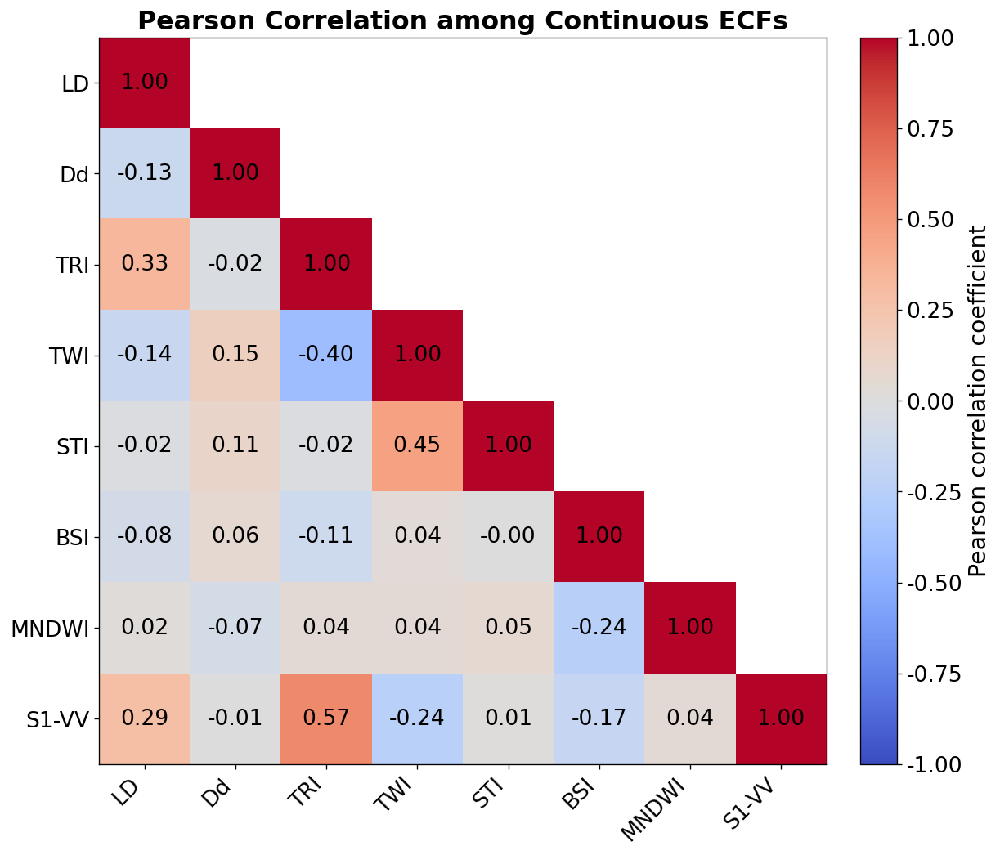

[DONE] DATA AND MULTICOLLINEARITY AUDIT | elapsed 0.14 min


In [11]:
stage('DATA AND MULTICOLLINEARITY AUDIT'); _t0=time.time(); data=pd.read_csv(FINAL_DATA_CSV)
summary=[]
for c in CONTINUOUS_ECFS+['RUSLE_A']:
    s=pd.to_numeric(data[c]); summary.append({'ECF_or_RUSLE':ecf_label(c) if c in ECF_LABELS else c,'Min':s.min(),'Mean':s.mean(),'Median':s.median(),'SD':s.std(),'Max':s.max(),'Missing':s.isna().sum()})
summary_df=pd.DataFrame(summary); summary_df.to_csv(DIRS['tables']/'Continuous_ECF_Descriptive_Statistics.csv',index=False); show_table(summary_df,'Continuous ECF and RUSLE statistics')
Xc=data[CONTINUOUS_ECFS].astype(float); vif=[]
for i,c in enumerate(CONTINUOUS_ECFS):
    v=float(variance_inflation_factor(Xc.values,i)); vif.append({'ECF':ecf_label(c),'VIF':v,'Tolerance':1/v if v>0 else np.nan})
vif_df=pd.DataFrame(vif); vif_df['VIF_gt5']=vif_df.VIF>5; vif_df['Tolerance_lt0.20']=vif_df.Tolerance<0.20
vif_df.to_csv(DIRS['tables']/'Continuous_VIF_Tolerance.csv',index=False); show_table(vif_df,'Continuous ECF VIF and tolerance')
parts=[Xc]; term_cols={}
for cat in CATEGORICAL_ECFS:
    d=pd.get_dummies(data[cat].astype(str),prefix=cat,drop_first=True,dtype=float); d=d.loc[:,d.std()>0]; term_cols[cat]=list(d.columns); parts.append(d)
Xd=pd.concat(parts,axis=1); R=np.corrcoef(Xd.to_numpy(float),rowvar=False)+np.eye(Xd.shape[1])*1e-10; cols=list(Xd.columns)
sf,ldf=np.linalg.slogdet(R); gv=[]
if sf<=0: raise RuntimeError('GVIF design correlation matrix is not positive definite')
for cat in CATEGORICAL_ECFS:
    it=[cols.index(c) for c in term_cols[cat]]; io=[i for i in range(len(cols)) if i not in it]
    st,ldt=np.linalg.slogdet(R[np.ix_(it,it)]); so,ldo=np.linalg.slogdet(R[np.ix_(io,io)])
    g=float(np.exp(ldt+ldo-ldf)); df=len(it); gv.append({'ECF':ecf_label(cat),'Df':df,'GVIF':g,'Adjusted_GVIF':g**(1/(2*df))})
gvif_df=pd.DataFrame(gv); gvif_df.to_csv(DIRS['tables']/'Categorical_Adjusted_GVIF.csv',index=False); show_table(gvif_df,'Categorical adjusted GVIF')
multi_cont=vif_df[['ECF','VIF','Tolerance']].copy()
multi_cont['Adjusted_GVIF']=np.nan
multi_cont['ECF_Type']='Continuous'
multi_cat=gvif_df[['ECF','Adjusted_GVIF']].copy()
multi_cat['VIF']=np.nan
multi_cat['Tolerance']=np.nan
multi_cat['ECF_Type']='Categorical'
multi_all=pd.concat([multi_cont,multi_cat],ignore_index=True)[['ECF','ECF_Type','VIF','Tolerance','Adjusted_GVIF']]
multi_all.to_csv(DIRS['tables']/'Multicollinearity_All_ECFs.csv',index=False)
multi_all.to_csv(DIRS['tables']/'Multicollinearity_VIF_Tolerance_AdjustedGVIF.csv',index=False)
show_table(multi_all,'Final multicollinearity summary for all 10 ECFs')

corr=Xc.corr(); corr.to_csv(DIRS['tables']/'Pearson_Correlation_Continuous_ECFs.csv')
fig,ax=plt.subplots(figsize=(10.5,9)); mask=np.triu(np.ones_like(corr,dtype=bool),k=1); im=ax.imshow(np.ma.array(corr.values,mask=mask),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(CONTINUOUS_ECFS))); ax.set_yticks(range(len(CONTINUOUS_ECFS)))
ax.set_xticklabels([ecf_label(x) for x in CONTINUOUS_ECFS],rotation=45,ha='right'); ax.set_yticklabels([ecf_label(x) for x in CONTINUOUS_ECFS])
for i in range(len(CONTINUOUS_ECFS)):
    for j in range(i+1): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=16)
cbar=fig.colorbar(im,ax=ax,fraction=.046,pad=.04); cbar.set_label('Pearson correlation coefficient',fontsize=FONT_LABEL); cbar.ax.tick_params(labelsize=FONT_TICK)
ax.set_title('Pearson Correlation among Continuous ECFs',fontweight='bold'); fig.tight_layout(); p=save_figure(fig,DIRS['figures']/'Figure_Pearson_LowerTriangle.png'); plt.show(); plt.close(fig)
finish('DATA AND MULTICOLLINEARITY AUDIT',_t0)


## 9. Publication ECF figures: 8 continuous maps and 2 categorical maps



FINAL ECF MAP FIGURES
Started: 2026-09-30 08:28:12
[SW SHAPEFILE] /content/drive/MyDrive/Mandakini_reu/Mandakini_23SW.shp
Feature count: 23
CRS: EPSG:4326
Geometry types: ['MultiPolygon', 'Polygon']


**Mandakini 23-SW shapefile audit**

,SWID,Area_km2
0,SW01,66.890
1,SW02,192.014
2,SW03,28.068
3,SW04,27.950
4,SW05,95.079
5,SW06,29.050
6,SW07,19.495
7,SW08,36.882
8,SW09,44.835
9,SW10,39.055


[PASS] All 23 SWs are present exactly once.
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Mandakini_23SW_Figure_Boundary_Audit.csv
Dissolved geometry type: Polygon
Interior rings detected: 520
Outer polygon part count: 1
SW summed area: 1643.766 km²
Dissolved basin area: 1643.739 km²
SW overlap/sliver area: 0.027267 km²
[PASS] ECF figures will use ONLY the exterior Mandakini basin boundary.


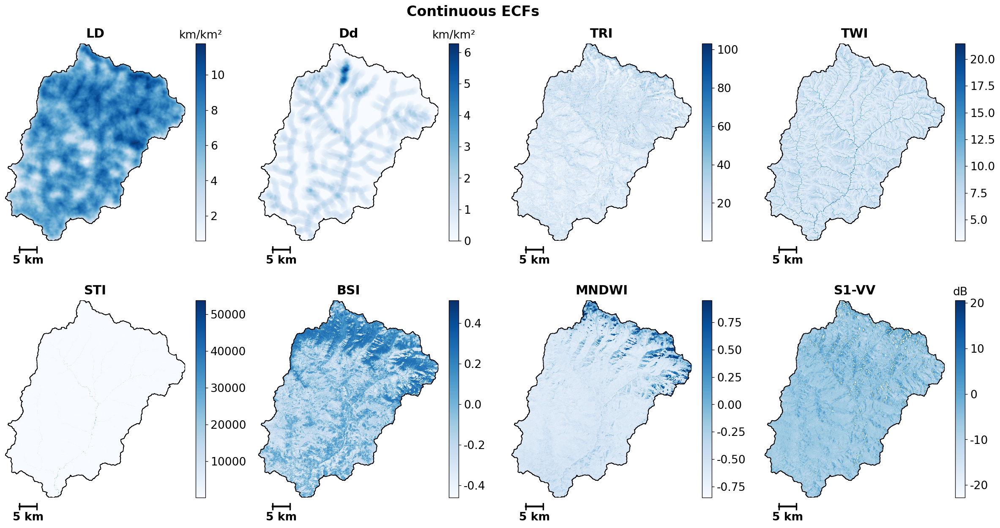

Lithology classes shown: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
LULC classes shown: [1, 2, 5, 7, 8, 9, 11]


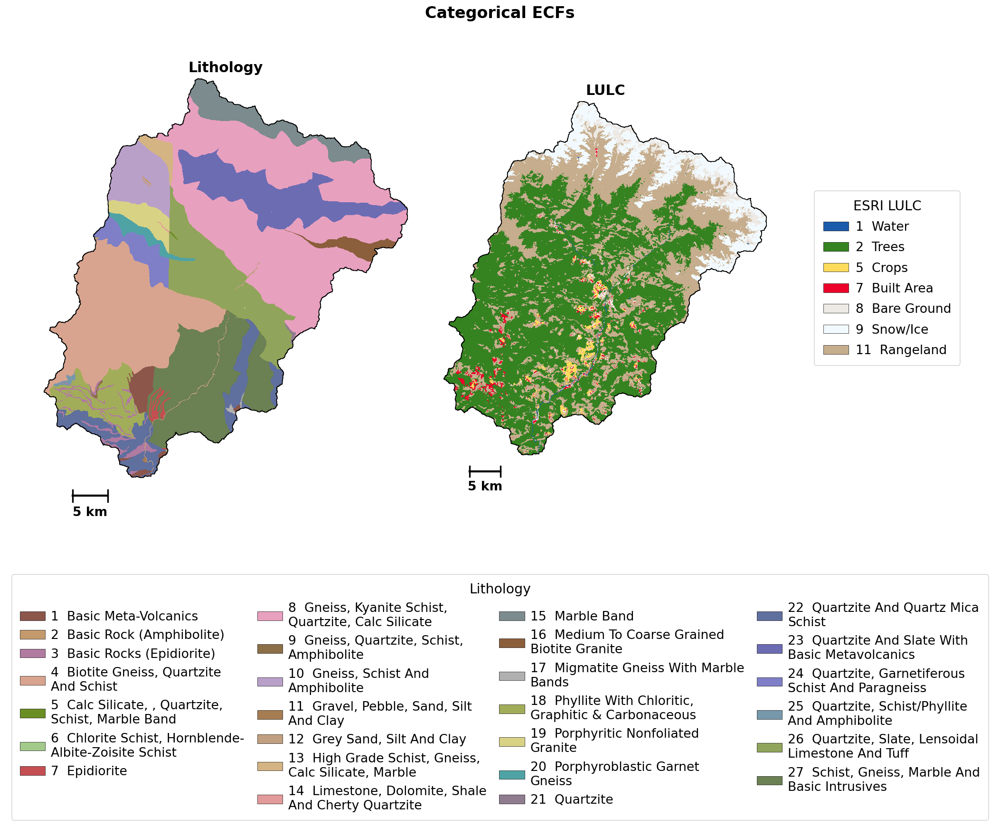

Saved: /content/drive/MyDrive/Mandakini_reu/07_Figures/Figure_Continuous_8_ECFs.png
Saved: /content/drive/MyDrive/Mandakini_reu/07_Figures/Figure_Categorical_Lithology_ESRI_LULC.png
[DONE] FINAL ECF MAP FIGURES | elapsed 1.00 min


In [22]:
stage("FINAL ECF MAP FIGURES")
_t0 = time.time()

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask
from shapely.geometry import Polygon, MultiPolygon, mapping
from shapely.ops import unary_union

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter


# =============================================================================
# 1. FIGURE-SPECIFIC SETTINGS
# =============================================================================

MAP_TITLE_FS = 18
FIG_TITLE_FS = 20
CBAR_TICK_FS = 16
CBAR_UNIT_FS = 16
LEGEND_FS = 16
LEGEND_TITLE_FS = 17

EXPECTED_SWIDS = [f"SW{i:02d}" for i in range(1, 24)]

SW_SHP = (
    Path(sw_shp)
    if "sw_shp" in globals()
    else PROJECT_ROOT / "Mandakini_23SW.shp"
)

if not SW_SHP.exists():
    raise FileNotFoundError(
        f"Mandakini 23-SW shapefile was not found:\n{SW_SHP}"
    )


# =============================================================================
# 2. STRICT AUDIT OF THE 23-SW SHAPEFILE
# =============================================================================

sw_fig = gpd.read_file(SW_SHP)

print("[SW SHAPEFILE]", SW_SHP)
print("Feature count:", len(sw_fig))
print("CRS:", sw_fig.crs)
print("Geometry types:", sorted(sw_fig.geom_type.astype(str).unique().tolist()))

if len(sw_fig) != 23:
    raise RuntimeError(
        f"Mandakini shapefile must contain exactly 23 SW features; "
        f"found {len(sw_fig)}."
    )

if sw_fig.crs is None:
    raise RuntimeError(
        "Mandakini 23-SW shapefile has no CRS."
    )

if sw_fig.geometry.isna().any():
    raise RuntimeError(
        f"{int(sw_fig.geometry.isna().sum())} SW feature(s) have null geometry."
    )

if sw_fig.geometry.is_empty.any():
    raise RuntimeError(
        f"{int(sw_fig.geometry.is_empty.sum())} SW feature(s) have empty geometry."
    )

if (~sw_fig.geometry.is_valid).any():

    bad_idx = sw_fig.index[
        ~sw_fig.geometry.is_valid
    ].tolist()

    raise RuntimeError(
        f"Invalid SW geometries detected at feature indices: {bad_idx}"
    )


# -----------------------------------------------------------------------------
# Resolve SW identity
# -----------------------------------------------------------------------------

sw_col_lookup = {
    str(c).strip().lower(): c
    for c in sw_fig.columns
}


def normalize_swid(value):

    text = str(value).strip().upper()

    if text.startswith("SW"):
        text = text[2:].strip()

    try:
        number = int(float(text))
        return f"SW{number:02d}"

    except Exception:
        return str(value).strip().upper()


if "swid" in sw_col_lookup:

    sw_fig["SWID_AUDIT"] = (
        sw_fig[
            sw_col_lookup["swid"]
        ]
        .astype(str)
        .map(normalize_swid)
    )

elif "objectid_num" in sw_col_lookup:

    nums = pd.to_numeric(
        sw_fig[
            sw_col_lookup["objectid_num"]
        ],
        errors="raise"
    ).astype(int)

    sw_fig["SWID_AUDIT"] = nums.map(
        lambda x: f"SW{x:02d}"
    )

elif "objectid" in sw_col_lookup:

    nums = pd.to_numeric(
        sw_fig[
            sw_col_lookup["objectid"]
        ],
        errors="raise"
    ).astype(int)

    sw_fig["SWID_AUDIT"] = nums.map(
        lambda x: f"SW{x:02d}"
    )

else:

    raise RuntimeError(
        "Could not resolve SW identity from the current Mandakini shapefile. "
        f"Columns found: {list(sw_fig.columns)}"
    )


observed_swids = sorted(
    sw_fig[
        "SWID_AUDIT"
    ].unique().tolist()
)

if len(observed_swids) != 23:

    raise RuntimeError(
        f"Expected 23 unique SW IDs; found {len(observed_swids)}: "
        f"{observed_swids}"
    )


missing_swids = sorted(
    set(EXPECTED_SWIDS)
    -
    set(observed_swids)
)

extra_swids = sorted(
    set(observed_swids)
    -
    set(EXPECTED_SWIDS)
)

if missing_swids or extra_swids:

    raise RuntimeError(
        "The 23-SW identity audit failed. "
        f"Missing={missing_swids}; Extra={extra_swids}"
    )


# -----------------------------------------------------------------------------
# Reproject and save audit
# -----------------------------------------------------------------------------

sw_fig = sw_fig.to_crs(CRS)

sw_fig[
    "Area_km2"
] = (
    sw_fig.geometry.area
    /
    1e6
)

sw_audit_table = (
    sw_fig[
        [
            "SWID_AUDIT",
            "Area_km2",
        ]
    ]
    .rename(
        columns={
            "SWID_AUDIT": "SWID"
        }
    )
    .sort_values("SWID")
    .reset_index(drop=True)
)

sw_audit_path = (
    DIRS["tables"]
    /
    "Mandakini_23SW_Figure_Boundary_Audit.csv"
)

sw_audit_table.to_csv(
    sw_audit_path,
    index=False
)

show_table(
    sw_audit_table,
    "Mandakini 23-SW shapefile audit",
    precision=3
)

print(
    "[PASS] All 23 SWs are present exactly once."
)

print(
    "[SAVE]",
    sw_audit_path
)


# =============================================================================
# 3. DISSOLVE ALL SWs AND REMOVE INTERIOR RINGS FOR ECF FIGURES
# =============================================================================
#
# .boundary.plot() draws:
# - exterior boundary
# - interior polygon rings
#
# Those interior rings can appear as unwanted triangular or enclosed shapes.
#
# For ECF figures we retain EXTERIORS ONLY.
# =============================================================================

dissolved_geom = unary_union(
    sw_fig.geometry.tolist()
)

if dissolved_geom.is_empty:

    raise RuntimeError(
        "Dissolved Mandakini basin geometry is empty."
    )

if dissolved_geom.geom_type not in {
    "Polygon",
    "MultiPolygon"
}:

    raise RuntimeError(
        "Dissolved Mandakini geometry must be Polygon or MultiPolygon; "
        f"found {dissolved_geom.geom_type}."
    )


def count_holes(
    geom
):

    if geom.geom_type == "Polygon":

        return len(
            geom.interiors
        )

    if geom.geom_type == "MultiPolygon":

        return sum(
            len(
                poly.interiors
            )
            for poly
            in geom.geoms
        )

    return 0


def remove_all_holes(
    geom
):

    if geom.geom_type == "Polygon":

        return Polygon(
            geom.exterior
        )

    if geom.geom_type == "MultiPolygon":

        parts = [
            Polygon(
                poly.exterior
            )
            for poly
            in geom.geoms
            if not poly.is_empty
        ]

        if len(parts) == 1:

            return parts[
                0
            ]

        return MultiPolygon(
            parts
        )

    raise TypeError(
        f"Unsupported basin geometry: {geom.geom_type}"
    )


hole_count = count_holes(
    dissolved_geom
)

outer_geom = remove_all_holes(
    dissolved_geom
)

if not outer_geom.is_valid:

    raise RuntimeError(
        "Outer-only Mandakini geometry is invalid after "
        "removing interior rings."
    )


if outer_geom.geom_type == "Polygon":

    outer_part_count = 1

else:

    outer_part_count = len(
        outer_geom.geoms
    )


print(
    "Dissolved geometry type:",
    dissolved_geom.geom_type
)

print(
    "Interior rings detected:",
    hole_count
)

print(
    "Outer polygon part count:",
    outer_part_count
)


# -----------------------------------------------------------------------------
# Area/topology audit
# -----------------------------------------------------------------------------

sum_sw_area_m2 = float(
    sw_fig.geometry.area.sum()
)

dissolved_area_m2 = float(
    dissolved_geom.area
)

overlap_area_m2 = max(
    0.0,
    sum_sw_area_m2
    -
    dissolved_area_m2
)

print(
    "SW summed area:",
    f"{sum_sw_area_m2 / 1e6:.3f} km²"
)

print(
    "Dissolved basin area:",
    f"{dissolved_area_m2 / 1e6:.3f} km²"
)

print(
    "SW overlap/sliver area:",
    f"{overlap_area_m2 / 1e6:.6f} km²"
)

print(
    "[PASS] ECF figures will use ONLY the exterior Mandakini basin boundary."
)


def plot_outer_boundary_only(
    ax,
    geom,
    linewidth=1.0
):

    polygons = (
        [geom]
        if geom.geom_type == "Polygon"
        else list(
            geom.geoms
        )
    )

    for poly in polygons:

        x, y = poly.exterior.xy

        ax.plot(
            x,
            y,
            color="black",
            linewidth=linewidth,
            zorder=20
        )


# =============================================================================
# 4. BUILD ONE OUTER-BASIN MASK FROM THE ALIGNED RASTER GRID
# =============================================================================

reference_ecf = CONTINUOUS_ECFS[
    0
]

with rasterio.open(
    ALIGNED_PATHS[
        reference_ecf
    ]
) as ref:

    ref_shape = (
        ref.height,
        ref.width
    )

    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_bounds = ref.bounds


if ref_crs is None:

    raise RuntimeError(
        f"Reference aligned ECF {reference_ecf} has no CRS."
    )


if str(
    ref_crs
) != str(
    CRS
):

    raise RuntimeError(
        f"Aligned ECF CRS mismatch. "
        f"Reference={ref_crs}; expected={CRS}"
    )


OUTER_BASIN_MASK = geometry_mask(
    [
        mapping(
            outer_geom
        )
    ],

    out_shape=
        ref_shape,

    transform=
        ref_transform,

    invert=
        True
)


minx = ref_bounds.left
maxx = ref_bounds.right
miny = ref_bounds.bottom
maxy = ref_bounds.top


def read_plot_ecf(
    ecf
):

    with rasterio.open(
        ALIGNED_PATHS[
            ecf
        ]
    ) as src:


        if (
            src.height,
            src.width
        ) != ref_shape:

            raise RuntimeError(
                f"{ecf_label(ecf)} aligned raster shape differs "
                "from the reference grid."
            )


        if src.crs != ref_crs:

            raise RuntimeError(
                f"{ecf_label(ecf)} aligned raster CRS differs "
                "from the reference grid."
            )


        if not src.transform.almost_equals(
            ref_transform
        ):

            raise RuntimeError(
                f"{ecf_label(ecf)} aligned raster transform differs "
                "from the reference grid."
            )


        arr = src.read(
            1
        ).astype(
            float
        )

        nodata = src.nodata


    invalid = ~np.isfinite(
        arr
    )


    if nodata is not None:

        if np.isnan(
            nodata
        ):

            invalid |= np.isnan(
                arr
            )

        else:

            invalid |= np.isclose(
                arr,
                nodata
            )


    arr[
        invalid
    ] = np.nan


    arr[
        ~OUTER_BASIN_MASK
    ] = np.nan


    return arr


# =============================================================================
# 5. CONTINUOUS ECF FIGURE
# =============================================================================

units = {
    "LD": "km/km²",
    "Dd": "km/km²",
    "TRI": "",
    "TWI": "",
    "STI": "",
    "BSI": "",
    "MNDWI": "",
    "S1_VV": "dB",
}


def sti_tick_formatter(
    value,
    position
):

    if abs(
        value
    ) >= 1000:

        return f"{value / 1000:.0f}K"

    if abs(
        value
    ) >= 1:

        return f"{value:.0f}"

    return f"{value:g}"


fig = plt.figure(
    figsize=(
        20.0,
        10.8
    )
)


outer_grid = fig.add_gridspec(
    2,
    4,
    left=0.035,
    right=0.985,
    bottom=0.075,
    top=0.905,
    wspace=0.24,
    hspace=0.30
)


for index, ecf in enumerate(
    CONTINUOUS_ECFS
):

    row = index // 4
    col = index % 4


    # Each map gets its own dedicated colorbar column.
    inner = outer_grid[
        row,
        col
    ].subgridspec(
        1,
        2,
        width_ratios=[
            22,
            1.15
        ],
        wspace=0.07
    )


    ax = fig.add_subplot(
        inner[
            0,
            0
        ]
    )


    cax = fig.add_subplot(
        inner[
            0,
            1
        ]
    )


    arr = read_plot_ecf(
        ecf
    )


    im = ax.imshow(
        np.ma.masked_invalid(
            arr
        ),
        extent=[
            minx,
            maxx,
            miny,
            maxy
        ],
        origin="upper",
        cmap="Blues",
        interpolation="nearest"
    )


    plot_outer_boundary_only(
        ax,
        outer_geom,
        linewidth=1.0
    )


    ax.set_title(
        ecf_label(
            ecf
        ),
        fontsize=MAP_TITLE_FS,
        fontweight="bold",
        pad=8
    )


    ax.set_axis_off()


    add_scale_bar_below(
        ax,
        maxx - minx,
        SCALE_BAR_M
    )


    cb = fig.colorbar(
        im,
        cax=cax
    )


    cb.ax.tick_params(
        labelsize=CBAR_TICK_FS
    )


    # Short horizontal unit title above the colorbar.
    if units[
        ecf
    ]:

        cb.ax.set_title(
            units[
                ecf
            ],
            fontsize=CBAR_UNIT_FS,
            pad=7
        )


    # Compact STI values, e.g. 20K and 40K.
    if ecf == "STI":

        cb.ax.yaxis.set_major_formatter(
            FuncFormatter(
                sti_tick_formatter
            )
        )

        cb.update_ticks()


fig.suptitle(
    "Continuous ECFs",
    fontsize=FIG_TITLE_FS,
    fontweight="bold",
    y=0.975
)


cont_fig = save_figure(
    fig,
    DIRS[
        "figures"
    ]
    /
    "Figure_Continuous_8_ECFs.png"
)


plt.show()

plt.close(
    fig
)

cleanup()


# =============================================================================
# 6. CURRENT LITHOLOGY LOOKUP AUDIT
# =============================================================================

lk = pd.read_csv(
    lith_lookup
)


lk_lookup = {
    str(c).strip().lower(): c
    for c in lk.columns
}


id_priority = [
    "lithology_id",
    "lithologyid",
    "id",
    "code",
    "unit_id",
]


name_priority = [
    "lithology_name",
    "lithologic",
    "lithology",
    "unit_name",
    "name",
    "class",
]


id_col = None


for key in id_priority:

    if key in lk_lookup:

        candidate = lk_lookup[
            key
        ]

        numeric = pd.to_numeric(
            lk[
                candidate
            ],
            errors="coerce"
        )

        if numeric.notna().sum() >= max(
            1,
            int(
                0.9
                *
                len(
                    lk
                )
            )
        ):

            id_col = candidate
            break


if id_col is None:

    numeric_candidates = []

    for c in lk.columns:

        numeric = pd.to_numeric(
            lk[
                c
            ],
            errors="coerce"
        )

        if numeric.notna().sum() >= max(
            1,
            int(
                0.9
                *
                len(
                    lk
                )
            )
        ):

            numeric_candidates.append(
                c
            )


    if len(
        numeric_candidates
    ) == 1:

        id_col = numeric_candidates[
            0
        ]


name_col = None


for key in name_priority:

    if (
        key in lk_lookup
        and
        lk_lookup[
            key
        ]
        !=
        id_col
    ):

        name_col = lk_lookup[
            key
        ]

        break


if name_col is None:

    text_candidates = [
        c
        for c in lk.columns
        if (
            c != id_col
            and
            not pd.api.types.is_numeric_dtype(
                lk[
                    c
                ]
            )
        )
    ]


    if len(
        text_candidates
    ) == 1:

        name_col = text_candidates[
            0
        ]


if (
    id_col is None
    or
    name_col is None
):

    raise RuntimeError(
        "Lithology lookup columns cannot be resolved unambiguously: "
        f"{list(lk.columns)}"
    )


ids = pd.to_numeric(
    lk[
        id_col
    ],
    errors="coerce"
)


lith_labels = {
    int(k):
        str(v).strip()

    for k, v
    in zip(
        ids,
        lk[
            name_col
        ]
    )

    if (
        pd.notna(
            k
        )
        and
        pd.notna(
            v
        )
        and
        str(
            v
        ).strip()
    )
}


# =============================================================================
# 7. READ CATEGORICAL ECFs USING THE SAME OUTER-BASIN MASK
# =============================================================================

lith = read_plot_ecf(
    "Lithology"
)

lulc = read_plot_ecf(
    "LULC"
)


lith_valid = (
    OUTER_BASIN_MASK
    &
    np.isfinite(
        lith
    )
)


lulc_valid = (
    OUTER_BASIN_MASK
    &
    np.isfinite(
        lulc
    )
)


lith_codes = sorted(
    int(
        v
    )
    for v
    in np.unique(
        lith[
            lith_valid
        ]
    )
)


lulc_codes = sorted(
    int(
        v
    )
    for v
    in np.unique(
        lulc[
            lulc_valid
        ]
    )
)


if not set(
    lith_codes
).issubset(
    set(
        lith_labels
    )
):

    raise RuntimeError(
        "Lithology raster codes are not fully represented in the "
        "current lookup. "
        f"Raster={lith_codes}; lookup={sorted(lith_labels)}"
    )


bad_codes = [
    code

    for code, label
    in lith_labels.items()

    if any(
        term
        in
        label.strip().lower()

        for term
        in [
            "unmapped",
            "unknown",
            "no data",
            "nodata",
        ]
    )
]


present_bad = sorted(
    set(
        lith_codes
    )
    .intersection(
        bad_codes
    )
)


if present_bad:

    raise RuntimeError(
        "Final Lithology raster still contains "
        f"unmapped/unknown codes: {present_bad}"
    )


unexpected_lulc = sorted(
    set(
        lulc_codes
    )
    -
    set(
        ESRI_LULC.keys()
    )
)


if unexpected_lulc:

    raise RuntimeError(
        "Unexpected ESRI native LULC codes: "
        f"{unexpected_lulc}"
    )


if 10 in lulc_codes:

    raise RuntimeError(
        "ESRI cloud code 10 occurs in the final LULC raster."
    )


print(
    "Lithology classes shown:",
    lith_codes
)

print(
    "LULC classes shown:",
    lulc_codes
)


# =============================================================================
# 8. LOCKED GEOLOGICAL COLORS
# =============================================================================

GEOLOGICAL_COLORS = [
    "#8C564B",
    "#C49A6C",
    "#B07AA1",
    "#D8A48F",
    "#6B8E23",
    "#A3C98B",
    "#C44E52",
    "#E8A0BF",
    "#8B6F47",
    "#B9A0C9",
    "#A67C52",
    "#C0A080",
    "#D4B483",
    "#E39A9A",
    "#7B8B8E",
    "#8B5E3C",
    "#B0B0B0",
    "#A2AD59",
    "#D8D285",
    "#4FA3A5",
    "#8F7C8F",
    "#5F6F9E",
    "#6C6CB3",
    "#7E7FC7",
    "#7798AB",
    "#91A45B",
    "#6B8053",
    "#B4C56A",
    "#D6D4A6",
]


if len(
    lith_codes
) > len(
    GEOLOGICAL_COLORS
):

    raise RuntimeError(
        f"Lithology contains {len(lith_codes)} classes but only "
        f"{len(GEOLOGICAL_COLORS)} locked colors."
    )


lith_color = {
    code:
        GEOLOGICAL_COLORS[
            index
        ]

    for index, code
    in enumerate(
        lith_codes
    )
}


def wrap_label(
    text,
    width=28
):

    cleaned = str(
        text
    ).replace(
        "_",
        " "
    ).title()


    return "\n".join(
        textwrap.wrap(
            cleaned,
            width=width
        )
    )


# =============================================================================
# 9. CATEGORICAL ECF FIGURE
# =============================================================================
#
# Figure height = 14.5 inches
#
# Map axes begin at y = 0.40
# Lithology legend ends at y = 0.26
#
# Gap:
# 0.14 × 14.5 ≈ 2.03 inches
#
# This deliberately pulls the Lithology legend about 2 inches below
# the maps so it cannot overlap them.
# =============================================================================

fig = plt.figure(
    figsize=(
        18.0,
        14.5
    )
)


# Lithology map.
ax_lith = fig.add_axes(
    [
        0.055,
        0.40,
        0.355,
        0.49,
    ]
)


# LULC map.
ax_lulc = fig.add_axes(
    [
        0.445,
        0.40,
        0.315,
        0.49,
    ]
)


# Dedicated LULC legend.
ax_lulc_legend = fig.add_axes(
    [
        0.775,
        0.49,
        0.205,
        0.31,
    ]
)


# Large Lithology legend, deliberately lower.
ax_lith_legend = fig.add_axes(
    [
        0.018,
        0.015,
        0.964,
        0.245,
    ]
)


ax_lulc_legend.axis(
    "off"
)

ax_lith_legend.axis(
    "off"
)


# -----------------------------------------------------------------------------
# Lithology
# -----------------------------------------------------------------------------

lith_display = np.full(
    lith.shape,
    np.nan,
    dtype=float
)


lith_handles = []


for index, code in enumerate(
    lith_codes
):

    lith_display[
        lith
        ==
        code
    ] = index


    color = lith_color[
        code
    ]


    lith_handles.append(
        mpatches.Patch(
            facecolor=color,
            edgecolor="black",
            linewidth=0.4,
            label=(
                f"{code}  "
                f"{wrap_label(lith_labels[code], 28)}"
            )
        )
    )


ax_lith.imshow(
    np.ma.masked_invalid(
        lith_display
    ),
    extent=[
        minx,
        maxx,
        miny,
        maxy
    ],
    origin="upper",
    interpolation="nearest",
    cmap=ListedColormap(
        [
            lith_color[
                code
            ]
            for code
            in lith_codes
        ]
    )
)


plot_outer_boundary_only(
    ax_lith,
    outer_geom,
    linewidth=1.0
)


ax_lith.set_title(
    "Lithology",
    fontsize=MAP_TITLE_FS,
    fontweight="bold",
    pad=8
)


ax_lith.set_axis_off()


add_scale_bar_below(
    ax_lith,
    maxx - minx,
    SCALE_BAR_M
)


# -----------------------------------------------------------------------------
# LULC
# -----------------------------------------------------------------------------

lulc_display = np.full(
    lulc.shape,
    np.nan,
    dtype=float
)


lulc_colors = []
lulc_handles = []


for index, code in enumerate(
    lulc_codes
):

    lulc_display[
        lulc
        ==
        code
    ] = index


    label, color = ESRI_LULC[
        code
    ]


    lulc_colors.append(
        color
    )


    lulc_handles.append(
        mpatches.Patch(
            facecolor=color,
            edgecolor="black",
            linewidth=0.4,
            label=f"{code}  {label}"
        )
    )


ax_lulc.imshow(
    np.ma.masked_invalid(
        lulc_display
    ),
    extent=[
        minx,
        maxx,
        miny,
        maxy
    ],
    origin="upper",
    interpolation="nearest",
    cmap=ListedColormap(
        lulc_colors
    )
)


plot_outer_boundary_only(
    ax_lulc,
    outer_geom,
    linewidth=1.0
)


ax_lulc.set_title(
    "LULC",
    fontsize=MAP_TITLE_FS,
    fontweight="bold",
    pad=8
)


ax_lulc.set_axis_off()


add_scale_bar_below(
    ax_lulc,
    maxx - minx,
    SCALE_BAR_M
)


# -----------------------------------------------------------------------------
# LULC legend
# -----------------------------------------------------------------------------

ax_lulc_legend.legend(
    handles=lulc_handles,
    loc="center",
    ncol=1,
    frameon=True,
    title="ESRI LULC",
    fontsize=LEGEND_FS,
    title_fontsize=LEGEND_TITLE_FS,
    handletextpad=0.55,
    borderpad=0.7,
    labelspacing=0.65
)


# -----------------------------------------------------------------------------
# Lithology legend
# -----------------------------------------------------------------------------

ax_lith_legend.legend(
    handles=lith_handles,
    loc="center",
    ncol=4,
    frameon=True,
    title="Lithology",
    columnspacing=1.0,
    handletextpad=0.45,
    fontsize=LEGEND_FS,
    title_fontsize=LEGEND_TITLE_FS,
    borderpad=0.65,
    labelspacing=0.50
)


fig.suptitle(
    "Categorical ECFs",
    fontsize=FIG_TITLE_FS,
    fontweight="bold",
    y=0.975
)


cat_fig = save_figure(
    fig,
    DIRS[
        "figures"
    ]
    /
    "Figure_Categorical_Lithology_ESRI_LULC.png"
)


plt.show()

plt.close(
    fig
)

cleanup()


# =============================================================================
# 10. FINISH
# =============================================================================

print(
    "Saved:",
    cont_fig
)

print(
    "Saved:",
    cat_fig
)

finish(
    "FINAL ECF MAP FIGURES",
    _t0
)

## 10. Spatial autocorrelation/range diagnostic for block-design context



SPATIAL RANGE DIAGNOSTIC
Started: 2026-09-30 07:59:51


**RUSLE spatial range diagnostic**

,Lag_m,Semivariance,Pair_Count
0,500.0000,26300.4921,15157
1,1500.0000,31024.7497,38383
2,2500.0000,32305.0091,57909
3,3500.0000,35532.0117,73680
4,4500.0000,36921.2533,87501
5,5500.0000,39328.5032,101010
6,6500.0000,41058.7487,112506
7,7500.0000,39584.5436,122415
8,8500.0000,36911.0218,130524
9,9500.0000,35565.2549,137613


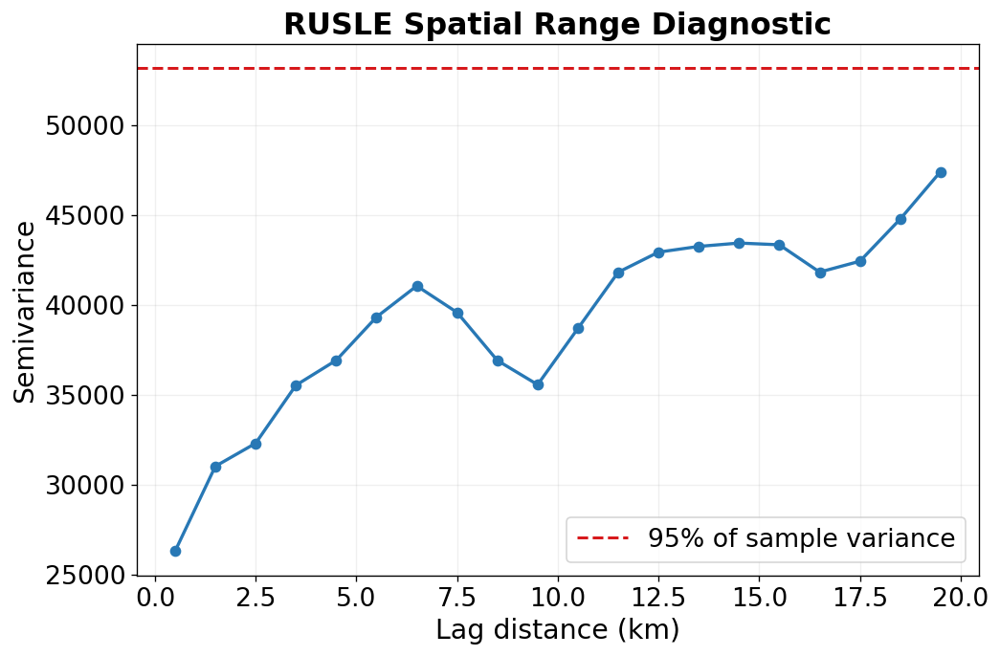

No exclusion buffer is imposed automatically. Empirical range is reported for transparent diagnosis.
[DONE] SPATIAL RANGE DIAGNOSTIC | elapsed 0.07 min


In [13]:
stage('SPATIAL RANGE DIAGNOSTIC'); _t0=time.time(); data=pd.read_csv(FINAL_DATA_CSV)
rng=np.random.default_rng(SEED); n=min(3000,len(data)); idx=np.sort(rng.choice(len(data),size=n,replace=False)); sub=data.iloc[idx]
coords_xy=sub[['X_UTM','Y_UTM']].to_numpy(float); vals=sub['RUSLE_A'].to_numpy(float)
dist=pdist(coords_xy); semi=.5*pdist(vals[:,None],metric='sqeuclidean')
maxlag=min(20000.,np.quantile(dist,.8)); edges=np.linspace(0,maxlag,21); centers=(edges[:-1]+edges[1:])/2; gamma=[]; counts=[]
for lo,hi in zip(edges[:-1],edges[1:]):
    m=(dist>=lo)&(dist<hi); counts.append(int(m.sum())); gamma.append(float(np.nanmean(semi[m])) if m.any() else np.nan)
vario=pd.DataFrame({'Lag_m':centers,'Semivariance':gamma,'Pair_Count':counts}); sill=float(np.nanvar(vals)); target=.95*sill
reach=vario.loc[vario.Semivariance>=target,'Lag_m']; empirical_range=float(reach.iloc[0]) if len(reach) else np.nan
vario.to_csv(DIRS['tables']/'RUSLE_Empirical_Semivariogram.csv',index=False); show_table(vario,'RUSLE spatial range diagnostic')
fig,ax=plt.subplots(figsize=(9,6)); ax.plot(vario.Lag_m/1000,vario.Semivariance,marker='o',color='#2878B5',lw=2); ax.axhline(target,color='#D7191C',ls='--',lw=1.8,label='95% of sample variance')
if np.isfinite(empirical_range): ax.axvline(empirical_range/1000,color='#555555',ls=':',lw=1.8,label=f'Empirical range ~{empirical_range/1000:.1f} km')
ax.set_xlabel('Lag distance (km)'); ax.set_ylabel('Semivariance'); ax.set_title('RUSLE Spatial Range Diagnostic',fontweight='bold'); ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); p=save_figure(fig,DIRS['figures']/'Figure_RUSLE_Spatial_Range_Diagnostic.png'); plt.show(); plt.close(fig)
print('No exclusion buffer is imposed automatically. Empirical range is reported for transparent diagnosis.')
finish('SPATIAL RANGE DIAGNOSTIC',_t0)


## 11. Whole-block 70/15/15 spatial split within every SW and five TRAIN folds


In [14]:
stage('SPATIAL TRAIN/CALIBRATION/TEST SPLIT'); _t0=time.time(); data=pd.read_csv(FINAL_DATA_CSV)
SPLIT_CSV=DIRS['splits']/'Mandakini_20700_Spatial_Split.csv'; SPLIT_META=DIRS['splits']/'Mandakini_20700_Spatial_Split.meta.json'
SPLIT_SIG=hash_payload({'data':sha256_file(FINAL_DATA_CSV),'seed':SEED,'ratios':[.70,.15,.15],'folds':5,'rule':'largest_feasible_block_per_SW'})
if valid_checkpoint(SPLIT_META,SPLIT_SIG) and SPLIT_CSV.exists():
    split_df=pd.read_csv(SPLIT_CSV); print('[RESTORE] spatial split')
else:
    candidate_sizes=[7680.,6000.,4800.,3840.,3000.,2400.,1920.,1500.,1200.,960.,750.,600.,480.,360.,300.]
    parts=[]
    for swid,grp0 in tqdm(data.groupby('SWID',sort=True),desc='Assign SW spatial blocks'):
        grp=grp0.copy(); chosen=None
        for bs in candidate_sizes:
            bx=np.floor((grp.X_UTM-minx)/bs).astype(int); by=np.floor((grp.Y_UTM-miny)/bs).astype(int); bid=bx.astype(str)+'_'+by.astype(str)
            if pd.Series(bid).nunique()>=7: chosen=bs; break
        if chosen is None: raise RuntimeError(f'{swid} cannot support 5 TRAIN folds + CAL + TEST with available candidate block sizes')
        grp['Block_Size_m']=chosen; grp['Block_ID']=(str(swid)+'_'+np.floor((grp.X_UTM-minx)/chosen).astype(int).astype(str)+'_'+np.floor((grp.Y_UTM-miny)/chosen).astype(int).astype(str))
        block_counts=grp.groupby('Block_ID').size().rename('n').reset_index()
        local_seed=SEED+int(re.sub(r'\D','',swid) or 0); block_counts=block_counts.sample(frac=1,random_state=local_seed).reset_index(drop=True)
        # Seed minimum block counts: TRAIN 5, CAL 1, TEST 1; then greedily fill point deficits.
        assignment={}; blocks=block_counts.Block_ID.tolist(); counts=dict(zip(block_counts.Block_ID,block_counts.n))
        for b in blocks[:5]: assignment[b]='TRAIN'
        assignment[blocks[5]]='CALIBRATION'; assignment[blocks[6]]='TEST'
        current={s:sum(counts[b] for b,a in assignment.items() if a==s) for s in ['TRAIN','CALIBRATION','TEST']}
        target={'TRAIN':.70*len(grp),'CALIBRATION':.15*len(grp),'TEST':.15*len(grp)}
        for b in blocks[7:]:
            deficits={s:target[s]-current[s] for s in target}; choice=max(deficits,key=deficits.get); assignment[b]=choice; current[choice]+=counts[b]
        grp['Split']=grp.Block_ID.map(assignment)
        # Five whole-block folds inside TRAIN only, each SW contributes to every fold.
        grp['CV_Fold']=0; train_blocks=grp.loc[grp.Split=='TRAIN'].groupby('Block_ID').size().rename('n').reset_index().sample(frac=1,random_state=local_seed+100)
        if len(train_blocks)<5: raise RuntimeError(f'{swid} has fewer than five TRAIN blocks')
        fold_assign={}; fold_counts={i:0 for i in range(1,6)}
        for i,b in enumerate(train_blocks.Block_ID.iloc[:5],start=1): fold_assign[b]=i; fold_counts[i]+=int(train_blocks.set_index('Block_ID').loc[b,'n'])
        for _,r in train_blocks.iloc[5:].iterrows():
            f=min(fold_counts,key=fold_counts.get); fold_assign[r.Block_ID]=f; fold_counts[f]+=int(r.n)
        m=grp.Split=='TRAIN'; grp.loc[m,'CV_Fold']=grp.loc[m,'Block_ID'].map(fold_assign).astype(int)
        parts.append(grp[['Point_ID','SWID','Block_Size_m','Block_ID','Split','CV_Fold']])
    split_df=pd.concat(parts,ignore_index=True).sort_values('Point_ID'); split_df.to_csv(SPLIT_CSV,index=False); save_json(SPLIT_META,{'status':'COMPLETE','signature':SPLIT_SIG})
data=data.merge(split_df,on=['Point_ID','SWID'],validate='one_to_one')
summary=data.groupby(['SWID','Split']).size().unstack(fill_value=0); summary['Total']=summary.sum(axis=1); summary.to_csv(DIRS['tables']/'Spatial_Split_Counts_By_SW.csv'); show_table(summary.reset_index(),'Spatial split counts by SW',precision=0)
fold_summary=data[data.Split=='TRAIN'].groupby(['SWID','CV_Fold']).size().unstack(fill_value=0); fold_summary.to_csv(DIRS['tables']/'Spatial_CV_Fold_Counts_By_SW.csv'); show_table(fold_summary.reset_index(),'TRAIN spatial fold counts by SW',precision=0)
# Hard leakage audits
if data.groupby('Block_ID').Split.nunique().max()!=1: raise RuntimeError('A spatial block was split across outer subsets')
if set(data.loc[data.Split=='TRAIN','CV_Fold'].unique())!={1,2,3,4,5}: raise RuntimeError('TRAIN does not contain all five spatial folds')
for swid,g in data.groupby('SWID'):
    if set(g.Split)!={'TRAIN','CALIBRATION','TEST'}: raise RuntimeError(f'{swid} missing an outer split')
    if set(g.loc[g.Split=='TRAIN','CV_Fold'])!={1,2,3,4,5}: raise RuntimeError(f'{swid} missing a TRAIN CV fold')
print('Whole-block leakage audit: PASS'); finish('SPATIAL TRAIN/CALIBRATION/TEST SPLIT',_t0)



SPATIAL TRAIN/CALIBRATION/TEST SPLIT
Started: 2026-09-30 07:59:55


Assign SW spatial blocks:   0%|          | 0/23 [00:00<?, ?it/s]

**Spatial split counts by SW**

Split,SWID,CALIBRATION,TEST,TRAIN,Total
0,SW01,50,304,546,900
1,SW02,67,180,653,900
2,SW03,48,99,753,900
3,SW04,151,153,596,900
4,SW05,118,59,723,900
5,SW06,242,12,646,900
6,SW07,43,157,700,900
7,SW08,51,15,834,900
8,SW09,96,171,633,900
9,SW10,189,29,682,900


**TRAIN spatial fold counts by SW**

CV_Fold,SWID,1,2,3,4,5
0,SW01,179,267,21,31,48
1,SW02,73,132,14,228,206
2,SW03,33,240,34,377,69
3,SW04,21,87,25,126,337
4,SW05,360,4,30,120,209
5,SW06,49,199,165,92,141
6,SW07,97,56,138,25,384
7,SW08,51,44,285,453,1
8,SW09,89,118,53,340,33
9,SW10,150,79,218,225,10


Whole-block leakage audit: PASS
[DONE] SPATIAL TRAIN/CALIBRATION/TEST SPLIT | elapsed 0.02 min


## 12. Spatial split map



SPATIAL TRAIN / CALIBRATION / TEST AUDIT
Started: 2026-09-30 08:26:49
[PASS] Shapefile contains exactly SW01-SW23.
[PASS] Modelling dataset contains exactly 23 SWs.
[PASS] TRAIN, CALIBRATION and TEST are all present.
[BLOCK FIELD] Block_ID
[PASS] Every spatial block belongs to one SW only.
[PASS] Every spatial block belongs to one split only.
[PASS] No whole-block leakage detected.


**Overall spatial split allocation by points**

,Split,Points,Observed_pct,Target_pct,Difference_pct_point
0,TRAIN,14486,69.981,70.000,-0.019
1,CALIBRATION,3063,14.797,15.000,-0.203
2,TEST,3151,15.222,15.000,0.222


**Overall spatial split allocation by whole blocks**

,Split,Blocks,Observed_pct,Target_pct,Difference_pct_point
0,TRAIN,122,68.927,70.000,-1.073
1,CALIBRATION,28,15.819,15.000,0.819
2,TEST,27,15.254,15.000,0.254


...

,SWID,Total_points,TRAIN_n,TRAIN_pct,CALIBRATION_n,CALIBRATION_pct,TEST_n,TEST_pct
SWID,,,,,,,,
SW01,SW01,900,546,60.67,50,5.56,304,33.78
SW02,SW02,900,653,72.56,67,7.44,180,20.00
SW03,SW03,900,753,83.67,48,5.33,99,11.00
SW04,SW04,900,596,66.22,151,16.78,153,17.00
SW05,SW05,900,723,80.33,118,13.11,59,6.56
SW06,SW06,900,646,71.78,242,26.89,12,1.33
SW07,SW07,900,700,77.78,43,4.78,157,17.44
SW08,SW08,900,834,92.67,51,5.67,15,1.67
SW09,SW09,900,633,70.33,96,10.67,171,19.00


[PASS] Every SW retains exactly 900 observations.


**Whole-block allocation within each SW**

,SWID,Total_blocks,TRAIN_blocks,CALIBRATION_blocks,TEST_blocks
SWID,,,,,
SW01,SW01,7,5,1,1
SW02,SW02,8,5,1,2
SW03,SW03,8,5,1,2
SW04,SW04,9,7,1,1
SW05,SW05,7,5,1,1
SW06,SW06,7,5,1,1
SW07,SW07,8,6,1,1
SW08,SW08,7,5,1,1
SW09,SW09,8,5,1,2


[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Spatial_Split_Overall_Point_Allocation_Audit.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Spatial_Split_Overall_Block_Allocation_Audit.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Spatial_Split_Per_SW_Point_Allocation_Audit.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Spatial_Split_Per_SW_Block_Allocation_Audit.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Spatial_Block_Assignment_Audit.csv

WHOLE-BLOCK SPATIAL SPLIT AUDIT
TRAIN       : 14,486 points (69.98%), target 70.00%
CALIBRATION : 3,063 points (14.80%), target 15.00%
TEST        : 3,151 points (15.22%), target 15.00%

Total points: 20,700
Total spatial blocks: 177
SWs in shapefile: 23
SWs in modelling data: 23
Blocks leaking between splits: 0


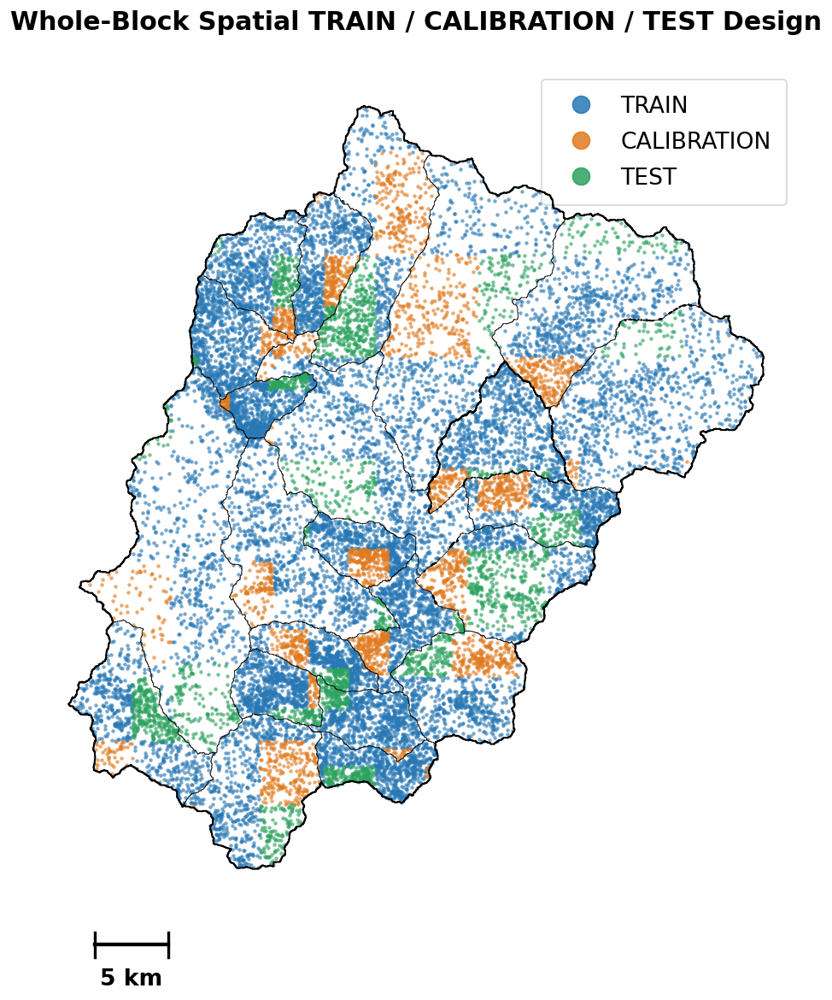


Saved: /content/drive/MyDrive/Mandakini_reu/07_Figures/Figure_Spatial_Train_Calibration_Test.png
[DONE] SPATIAL TRAIN / CALIBRATION / TEST AUDIT | elapsed 0.20 min


In [21]:
# =============================================================================
# SPATIAL TRAIN / CALIBRATION / TEST AUDIT + FIGURE
# =============================================================================

stage("SPATIAL TRAIN / CALIBRATION / TEST AUDIT")
_t0 = time.time()

from matplotlib.lines import Line2D

# =============================================================================
# 1. LOCKED DESIGN
# =============================================================================

EXPECTED_SWIDS = [
    f"SW{i:02d}"
    for i in range(1, 24)
]

EXPECTED_SPLITS = [
    "TRAIN",
    "CALIBRATION",
    "TEST",
]

TARGET_SPLIT_PCT = {
    "TRAIN": 70.0,
    "CALIBRATION": 15.0,
    "TEST": 15.0,
}

split_colors = {
    "TRAIN": "#2878B5",
    "CALIBRATION": "#E07A1F",
    "TEST": "#2CA25F",
}


# =============================================================================
# 2. RESOLVE SWID COLUMN IN SHAPEFILE
# =============================================================================

if "sw_gdf" not in globals():
    raise RuntimeError(
        "sw_gdf is not available. "
        "Run the spatial-split preparation cell first."
    )

if len(sw_gdf) != 23:
    raise RuntimeError(
        f"Expected exactly 23 SW polygons; found {len(sw_gdf)}."
    )

if sw_gdf.crs is None:
    raise RuntimeError(
        "SW shapefile has no CRS."
    )

sw_col_lookup = {
    str(c).strip().lower(): c
    for c in sw_gdf.columns
}


def normalize_swid(value):
    text = str(value).strip().upper()

    if text.startswith("SW"):
        text = text[2:].strip()

    try:
        number = int(float(text))
        return f"SW{number:02d}"
    except Exception:
        return str(value).strip().upper()


if "swid" in sw_col_lookup:

    sw_shape_ids = (
        sw_gdf[
            sw_col_lookup["swid"]
        ]
        .map(normalize_swid)
    )

elif "objectid_num" in sw_col_lookup:

    sw_shape_ids = (
        pd.to_numeric(
            sw_gdf[
                sw_col_lookup["objectid_num"]
            ],
            errors="raise"
        )
        .astype(int)
        .map(
            lambda x: f"SW{x:02d}"
        )
    )

elif "objectid" in sw_col_lookup:

    sw_shape_ids = (
        pd.to_numeric(
            sw_gdf[
                sw_col_lookup["objectid"]
            ],
            errors="raise"
        )
        .astype(int)
        .map(
            lambda x: f"SW{x:02d}"
        )
    )

else:

    raise RuntimeError(
        "Could not identify SWID in the 23-SW shapefile. "
        f"Columns found: {list(sw_gdf.columns)}"
    )


shape_swids = sorted(
    sw_shape_ids.unique().tolist()
)

missing_shape_swids = sorted(
    set(EXPECTED_SWIDS)
    -
    set(shape_swids)
)

extra_shape_swids = sorted(
    set(shape_swids)
    -
    set(EXPECTED_SWIDS)
)


if missing_shape_swids or extra_shape_swids:

    raise RuntimeError(
        "23-SW shapefile audit failed. "
        f"Missing={missing_shape_swids}; "
        f"Extra={extra_shape_swids}"
    )


if sw_shape_ids.duplicated().any():

    duplicated = sorted(
        sw_shape_ids[
            sw_shape_ids.duplicated(
                keep=False
            )
        ]
        .unique()
        .tolist()
    )

    raise RuntimeError(
        f"Duplicate SW polygons detected: {duplicated}"
    )


print(
    "[PASS] Shapefile contains exactly SW01-SW23."
)


# =============================================================================
# 3. AUDIT MODELLING DATA SWIDs
# =============================================================================

required_columns = {
    "SWID",
    "Split",
    "X_UTM",
    "Y_UTM",
}

missing_columns = sorted(
    required_columns
    -
    set(data.columns)
)

if missing_columns:

    raise RuntimeError(
        "Spatial split dataset is missing required columns: "
        f"{missing_columns}"
    )


data["SWID"] = (
    data[
        "SWID"
    ]
    .map(normalize_swid)
)


data["Split"] = (
    data[
        "Split"
    ]
    .astype(str)
    .str.strip()
    .str.upper()
)


data_swids = sorted(
    data[
        "SWID"
    ]
    .unique()
    .tolist()
)


missing_data_swids = sorted(
    set(EXPECTED_SWIDS)
    -
    set(data_swids)
)


extra_data_swids = sorted(
    set(data_swids)
    -
    set(EXPECTED_SWIDS)
)


if missing_data_swids or extra_data_swids:

    raise RuntimeError(
        "Spatial split data do not contain exactly SW01-SW23. "
        f"Missing={missing_data_swids}; "
        f"Extra={extra_data_swids}"
    )


print(
    "[PASS] Modelling dataset contains exactly 23 SWs."
)


# =============================================================================
# 4. AUDIT SPLIT LABELS
# =============================================================================

observed_splits = sorted(
    data[
        "Split"
    ]
    .unique()
    .tolist()
)


unexpected_splits = sorted(
    set(observed_splits)
    -
    set(EXPECTED_SPLITS)
)


missing_splits = sorted(
    set(EXPECTED_SPLITS)
    -
    set(observed_splits)
)


if unexpected_splits or missing_splits:

    raise RuntimeError(
        "Split-label audit failed. "
        f"Missing={missing_splits}; "
        f"Unexpected={unexpected_splits}"
    )


print(
    "[PASS] TRAIN, CALIBRATION and TEST are all present."
)


# =============================================================================
# 5. RESOLVE THE ACTUAL SPATIAL BLOCK COLUMN
# =============================================================================
#
# No guessing from arbitrary columns.
# These are the accepted block-field names only.
# =============================================================================

BLOCK_COLUMN_CANDIDATES = [
    "Block_ID",
    "BlockID",
    "Spatial_Block",
    "Spatial_Block_ID",
    "Block",
    "BLOCK_ID",
]


block_matches = [
    c
    for c in BLOCK_COLUMN_CANDIDATES
    if c in data.columns
]


if len(block_matches) == 0:

    raise RuntimeError(
        "No spatial block column was found in the split dataset.\n"
        "Cannot verify the whole-block contract.\n"
        f"Dataset columns: {list(data.columns)}"
    )


if len(block_matches) > 1:

    raise RuntimeError(
        "More than one possible spatial-block field exists. "
        "No field will be guessed: "
        f"{block_matches}"
    )


BLOCK_COL = block_matches[
    0
]


print(
    "[BLOCK FIELD]",
    BLOCK_COL
)


# =============================================================================
# 6. WHOLE-BLOCK LEAKAGE AUDIT
# =============================================================================
#
# Each block must belong to:
# 1. one SW only
# 2. one Split only
# =============================================================================

block_swid_n = (
    data
    .groupby(
        BLOCK_COL
    )[
        "SWID"
    ]
    .nunique()
)


bad_sw_blocks = block_swid_n[
    block_swid_n != 1
]


if len(
    bad_sw_blocks
) > 0:

    raise RuntimeError(
        f"{len(bad_sw_blocks)} spatial block(s) occur in "
        "more than one SW."
    )


block_split_n = (
    data
    .groupby(
        BLOCK_COL
    )[
        "Split"
    ]
    .nunique()
)


leaking_blocks = block_split_n[
    block_split_n != 1
]


if len(
    leaking_blocks
) > 0:

    leak_preview = (
        data[
            data[
                BLOCK_COL
            ].isin(
                leaking_blocks.index
            )
        ]
        [
            [
                BLOCK_COL,
                "SWID",
                "Split",
            ]
        ]
        .drop_duplicates()
        .sort_values(
            [
                BLOCK_COL,
                "Split",
            ]
        )
    )

    display(
        leak_preview.head(
            50
        )
    )

    raise RuntimeError(
        f"{len(leaking_blocks)} spatial block(s) are split "
        "between TRAIN/CALIBRATION/TEST."
    )


print(
    "[PASS] Every spatial block belongs to one SW only."
)

print(
    "[PASS] Every spatial block belongs to one split only."
)

print(
    "[PASS] No whole-block leakage detected."
)


# =============================================================================
# 7. OVERALL POINT-ALLOCATION AUDIT
# =============================================================================

overall_point_audit = (
    data[
        "Split"
    ]
    .value_counts()
    .reindex(
        EXPECTED_SPLITS,
        fill_value=0
    )
    .rename(
        "Points"
    )
    .reset_index()
    .rename(
        columns={
            "index":
                "Split"
        }
    )
)


overall_point_audit[
    "Observed_pct"
] = (
    overall_point_audit[
        "Points"
    ]
    /
    len(
        data
    )
    *
    100.0
)


overall_point_audit[
    "Target_pct"
] = overall_point_audit[
    "Split"
].map(
    TARGET_SPLIT_PCT
)


overall_point_audit[
    "Difference_pct_point"
] = (
    overall_point_audit[
        "Observed_pct"
    ]
    -
    overall_point_audit[
        "Target_pct"
    ]
)


show_table(
    overall_point_audit,
    "Overall spatial split allocation by points",
    precision=3
)


# =============================================================================
# 8. OVERALL WHOLE-BLOCK ALLOCATION AUDIT
# =============================================================================

block_inventory = (
    data[
        [
            BLOCK_COL,
            "SWID",
            "Split",
        ]
    ]
    .drop_duplicates()
)


total_blocks = len(
    block_inventory
)


overall_block_audit = (
    block_inventory[
        "Split"
    ]
    .value_counts()
    .reindex(
        EXPECTED_SPLITS,
        fill_value=0
    )
    .rename(
        "Blocks"
    )
    .reset_index()
    .rename(
        columns={
            "index":
                "Split"
        }
    )
)


overall_block_audit[
    "Observed_pct"
] = (
    overall_block_audit[
        "Blocks"
    ]
    /
    total_blocks
    *
    100.0
)


overall_block_audit[
    "Target_pct"
] = overall_block_audit[
    "Split"
].map(
    TARGET_SPLIT_PCT
)


overall_block_audit[
    "Difference_pct_point"
] = (
    overall_block_audit[
        "Observed_pct"
    ]
    -
    overall_block_audit[
        "Target_pct"
    ]
)


show_table(
    overall_block_audit,
    "Overall spatial split allocation by whole blocks",
    precision=3
)


# =============================================================================
# 9. PER-SW POINT ALLOCATION AUDIT
# =============================================================================

sw_point_counts = (
    data
    .groupby(
        [
            "SWID",
            "Split",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        EXPECTED_SWIDS
    )
)


for split in EXPECTED_SPLITS:

    if split not in sw_point_counts.columns:

        sw_point_counts[
            split
        ] = 0


sw_point_counts = sw_point_counts[
    EXPECTED_SPLITS
]


sw_point_pct = (
    sw_point_counts
    .div(
        sw_point_counts.sum(
            axis=1
        ),
        axis=0
    )
    *
    100.0
)


sw_point_audit = pd.DataFrame(
    {
        "SWID":
            sw_point_counts.index,

        "Total_points":
            sw_point_counts.sum(
                axis=1
            ).astype(
                int
            ),

        "TRAIN_n":
            sw_point_counts[
                "TRAIN"
            ].astype(
                int
            ),

        "TRAIN_pct":
            sw_point_pct[
                "TRAIN"
            ],

        "CALIBRATION_n":
            sw_point_counts[
                "CALIBRATION"
            ].astype(
                int
            ),

        "CALIBRATION_pct":
            sw_point_pct[
                "CALIBRATION"
            ],

        "TEST_n":
            sw_point_counts[
                "TEST"
            ].astype(
                int
            ),

        "TEST_pct":
            sw_point_pct[
                "TEST"
            ],
    }
)


show_table(
    sw_point_audit,
    "Spatial split allocation within each SW",
    precision=2
)


if not (
    sw_point_audit[
        "Total_points"
    ]
    ==
    EXPECTED_POINTS_PER_SW
).all():

    raise RuntimeError(
        "At least one SW no longer contains exactly 900 points."
    )


print(
    "[PASS] Every SW retains exactly 900 observations."
)


# =============================================================================
# 10. PER-SW BLOCK AUDIT
# =============================================================================

sw_block_counts = (
    block_inventory
    .groupby(
        [
            "SWID",
            "Split",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        EXPECTED_SWIDS
    )
)


for split in EXPECTED_SPLITS:

    if split not in sw_block_counts.columns:

        sw_block_counts[
            split
        ] = 0


sw_block_counts = sw_block_counts[
    EXPECTED_SPLITS
]


sw_block_audit = pd.DataFrame(
    {
        "SWID":
            sw_block_counts.index,

        "Total_blocks":
            sw_block_counts.sum(
                axis=1
            ).astype(
                int
            ),

        "TRAIN_blocks":
            sw_block_counts[
                "TRAIN"
            ].astype(
                int
            ),

        "CALIBRATION_blocks":
            sw_block_counts[
                "CALIBRATION"
            ].astype(
                int
            ),

        "TEST_blocks":
            sw_block_counts[
                "TEST"
            ].astype(
                int
            ),
    }
)


show_table(
    sw_block_audit,
    "Whole-block allocation within each SW",
    precision=0
)


# =============================================================================
# 11. SAVE AUDIT TABLES
# =============================================================================

overall_point_path = (
    DIRS[
        "tables"
    ]
    /
    "Spatial_Split_Overall_Point_Allocation_Audit.csv"
)


overall_block_path = (
    DIRS[
        "tables"
    ]
    /
    "Spatial_Split_Overall_Block_Allocation_Audit.csv"
)


sw_point_path = (
    DIRS[
        "tables"
    ]
    /
    "Spatial_Split_Per_SW_Point_Allocation_Audit.csv"
)


sw_block_path = (
    DIRS[
        "tables"
    ]
    /
    "Spatial_Split_Per_SW_Block_Allocation_Audit.csv"
)


block_inventory_path = (
    DIRS[
        "tables"
    ]
    /
    "Spatial_Block_Assignment_Audit.csv"
)


overall_point_audit.to_csv(
    overall_point_path,
    index=False
)


overall_block_audit.to_csv(
    overall_block_path,
    index=False
)


sw_point_audit.to_csv(
    sw_point_path,
    index=False
)


sw_block_audit.to_csv(
    sw_block_path,
    index=False
)


block_inventory.to_csv(
    block_inventory_path,
    index=False
)


print(
    "[SAVE]",
    overall_point_path
)

print(
    "[SAVE]",
    overall_block_path
)

print(
    "[SAVE]",
    sw_point_path
)

print(
    "[SAVE]",
    sw_block_path
)

print(
    "[SAVE]",
    block_inventory_path
)


# =============================================================================
# 12. PRINT THE ACTUAL 70:15:15 RESULT
# =============================================================================

print(
    "\n"
    +
    "=" * 80
)

print(
    "WHOLE-BLOCK SPATIAL SPLIT AUDIT"
)

print(
    "=" * 80
)


for _, row in overall_point_audit.iterrows():

    print(
        f"{row['Split']:12s}: "
        f"{int(row['Points']):,} points "
        f"({row['Observed_pct']:.2f}%), "
        f"target {row['Target_pct']:.2f}%"
    )


print(
    "\nTotal points:",
    f"{len(data):,}"
)

print(
    "Total spatial blocks:",
    f"{total_blocks:,}"
)

print(
    "SWs in shapefile:",
    len(
        shape_swids
    )
)

print(
    "SWs in modelling data:",
    data[
        "SWID"
    ].nunique()
)

print(
    "Blocks leaking between splits:",
    len(
        leaking_blocks
    )
)


# =============================================================================
# 13. PUBLICATION FIGURE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(
        10,
        10
    )
)


# -----------------------------------------------------------------------------
# Plot points
# -----------------------------------------------------------------------------

for split in EXPECTED_SPLITS:

    subset = data[
        data[
            "Split"
        ]
        ==
        split
    ]


    ax.scatter(
        subset[
            "X_UTM"
        ],

        subset[
            "Y_UTM"
        ],

        s=7,

        c=split_colors[
            split
        ],

        alpha=0.65,

        linewidths=0,

        rasterized=True,

        zorder=3
    )


# -----------------------------------------------------------------------------
# Internal 23-SW boundaries
# -----------------------------------------------------------------------------

sw_gdf.boundary.plot(
    ax=ax,
    color="black",
    lw=0.45,
    alpha=0.70,
    zorder=5
)


# -----------------------------------------------------------------------------
# Outer Mandakini boundary
# -----------------------------------------------------------------------------

outer.boundary.plot(
    ax=ax,
    color="black",
    lw=1.20,
    zorder=6
)


# -----------------------------------------------------------------------------
# Large, publication-visible custom legend symbols
# -----------------------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        markersize=12,
        markerfacecolor=split_colors[
            split
        ],
        markeredgecolor=split_colors[
            split
        ],
        alpha=0.85,
        label=split
    )

    for split
    in EXPECTED_SPLITS
]


ax.legend(
    handles=legend_handles,
    loc="upper right",
    fontsize=16,
    frameon=True,
    markerscale=1.0,
    handletextpad=0.75,
    borderpad=0.70,
    labelspacing=0.60
)


ax.set_title(
    "Whole-Block Spatial TRAIN / CALIBRATION / TEST Design",
    fontsize=18,
    fontweight="bold",
    pad=12
)


ax.set_axis_off()


add_scale_bar_below(
    ax,
    maxx - minx,
    SCALE_BAR_M
)


fig.tight_layout()


p = save_figure(
    fig,
    DIRS[
        "figures"
    ]
    /
    "Figure_Spatial_Train_Calibration_Test.png"
)


plt.show()

plt.close(
    fig
)


print(
    "\nSaved:",
    p
)


finish(
    "SPATIAL TRAIN / CALIBRATION / TEST AUDIT",
    _t0
)

## 13. Ordered process-informed targets, calibration metrics, and model utilities


In [16]:
from copy import deepcopy

def target_from_A(A):
    A=np.asarray(A,float); return np.select([A<50,A<75],[0,1],default=2).astype(int)
def ordinal_binary_targets(A):
    A=np.asarray(A,float); return (A>=50).astype(int),(A>=75).astype(int)
def process_weights(A,y,threshold,lmbda):
    A=np.asarray(A,float); y=np.asarray(y,int)
    base=compute_sample_weight(class_weight='balanced',y=y).astype(float)
    d=np.abs(A-threshold); q95=float(np.quantile(d,.95)); margin=np.minimum(d/max(q95,1e-12),1.0)
    return base*(1.0+lmbda*margin)
def project_ordered(q1,q2):
    q1=np.asarray(q1,float).copy(); q2=np.asarray(q2,float).copy(); violation=q2>q1
    avg=.5*(q1[violation]+q2[violation]); q1[violation]=avg; q2[violation]=avg
    return np.clip(q1,0,1),np.clip(q2,0,1),violation
def class_probs_from_q(q1,q2):
    q1p,q2p,violation=project_ordered(q1,q2)
    p=np.column_stack([1-q1p,q1p-q2p,q2p]); p=np.clip(p,1e-9,1); p=p/p.sum(axis=1,keepdims=True)
    return p,violation

def susceptibility_score(probs):
    probs=np.asarray(probs,float); return probs[:,2]+0.5*probs[:,1]
def multiclass_brier(y,p):
    Y=np.eye(3)[np.asarray(y,int)]; return float(np.mean(np.sum((Y-p)**2,axis=1)))
def ece_toplabel(y,p,n_bins=15):
    y=np.asarray(y,int); p=np.asarray(p,float); conf=p.max(axis=1); pred=p.argmax(axis=1); acc=(pred==y).astype(float)
    edges=np.linspace(0,1,n_bins+1); ece=0.0
    for lo,hi in zip(edges[:-1],edges[1:]):
        m=(conf>=lo)&((conf<hi) if hi<1 else (conf<=hi))
        if m.any(): ece+=m.mean()*abs(acc[m].mean()-conf[m].mean())
    return float(ece)
def metric_dict(y,p):
    y=np.asarray(y,int); pred=np.argmax(p,axis=1); Y=label_binarize(y,classes=[0,1,2])
    macro_auc=roc_auc_score(y,p,multi_class='ovr',average='macro'); micro_auc=roc_auc_score(Y,p,average='micro')
    return {'Accuracy':accuracy_score(y,pred),'Macro_Precision':precision_score(y,pred,average='macro',zero_division=0),
            'Macro_Recall':recall_score(y,pred,average='macro',zero_division=0),'Macro_F1':f1_score(y,pred,average='macro',zero_division=0),
            'Kappa':cohen_kappa_score(y,pred),'MCC':matthews_corrcoef(y,pred),'Macro_AUC':macro_auc,'Micro_AUC':micro_auc,
            'Brier':multiclass_brier(y,p),'NLL':log_loss(y,p,labels=[0,1,2]),'ECE':ece_toplabel(y,p)}

class DirichletCalibrator:
    # Multinomial logistic calibration on log class probabilities.
    def __init__(self,C=1.0): self.C=C; self.model=None
    def fit(self,p,y):
        x=np.log(np.clip(np.asarray(p,float),1e-9,1)); self.model=LogisticRegression(C=self.C,max_iter=3000,solver='lbfgs',random_state=SEED); self.model.fit(x,np.asarray(y,int)); return self
    def transform(self,p):
        x=np.log(np.clip(np.asarray(p,float),1e-9,1)); out=self.model.predict_proba(x)
        # sklearn class order is explicit; force 0,1,2 order.
        full=np.zeros((len(out),3),float)
        for j,c in enumerate(self.model.classes_.astype(int)): full[:,c]=out[:,j]
        full=np.clip(full,1e-9,1); return full/full.sum(axis=1,keepdims=True)

print('Process-informed and calibration utilities loaded.')


Process-informed and calibration utilities loaded.


## 14. Reproducible ECF encoders and binary model wrappers


In [17]:
def make_ohe():
    try: return OneHotEncoder(handle_unknown='ignore',sparse_output=False)
    except TypeError: return OneHotEncoder(handle_unknown='ignore',sparse=False)
def make_sklearn_preprocessor(scale=True):
    return ColumnTransformer([('num',StandardScaler() if scale else 'passthrough',CONTINUOUS_ECFS),('cat',make_ohe(),CATEGORICAL_ECFS)],remainder='drop')

class TabularEncoder:
    def __init__(self): self.scaler=StandardScaler(); self.maps={}; self.cat_dims=[]
    def fit(self,X):
        self.scaler.fit(X[CONTINUOUS_ECFS].astype(float))
        self.maps={}; self.cat_dims=[]
        for c in CATEGORICAL_ECFS:
            vals=sorted(pd.Series(X[c]).dropna().unique().tolist()); self.maps[c]={v:i for i,v in enumerate(vals)}; self.cat_dims.append(len(vals)+1)
        return self
    def transform(self,X):
        num=self.scaler.transform(X[CONTINUOUS_ECFS].astype(float)).astype(np.float32); cats=[]
        for c in CATEGORICAL_ECFS:
            mp=self.maps[c]; unk=len(mp); cats.append(X[c].map(lambda v:mp.get(v,unk)).to_numpy(np.float32)[:,None])
        return np.hstack([num]+cats).astype(np.float32)
    @property
    def cat_idxs(self): return list(range(len(CONTINUOUS_ECFS),len(CONTINUOUS_ECFS)+len(CATEGORICAL_ECFS)))

class TorchNet(nn.Module):
    def __init__(self,n_in,hidden,dropout):
        super().__init__(); layers=[]; d=n_in
        for h in hidden: layers.extend([nn.Linear(d,h),nn.ReLU(),nn.Dropout(dropout)]); d=h
        layers.append(nn.Linear(d,1)); self.net=nn.Sequential(*layers)
    def forward(self,x): return self.net(x).squeeze(1)

@dataclass
class BinaryBundle:
    family:str; model:object; preprocessor:object=None; config:dict=None
    def predict_proba1(self,X):
        if self.family=='CatBoost':
            z=X[ECFS].copy()
            for c in CATEGORICAL_ECFS: z[c]=z[c].astype(str)
            return self.model.predict_proba(z)[:,1]
        if self.family=='ExtraTrees': return self.model.predict_proba(X[ECFS])[:,1]
        if self.family=='MLP_ANN':
            z=self.preprocessor.transform(X[ECFS]).astype(np.float32); self.model=self.model.to(DEVICE); self.model.eval(); out=[]
            with torch.no_grad():
                for i in range(0,len(z),8192): out.append(torch.sigmoid(self.model(torch.tensor(z[i:i+8192],device=DEVICE))).cpu().numpy())
            return np.concatenate(out)
        if self.family=='TabNet':
            z=self.preprocessor.transform(X[ECFS])
            if hasattr(self.model,'network') and self.model.network is not None:
                self.model.network.to(DEVICE); self.model.device=DEVICE
            return self.model.predict_proba(z)[:,1]
        raise ValueError(self.family)

@dataclass
class OrdinalBundle:
    family:str; model50:BinaryBundle; model75:BinaryBundle; config:dict; lmbda:float
    def predict_uncalibrated(self,X):
        q1=self.model50.predict_proba1(X); q2=self.model75.predict_proba1(X); p,v=class_probs_from_q(q1,q2); return p,q1,q2,v

def fit_torch_binary(Xtr,ytr,wtr,config,Xval=None,yval=None,fixed_epochs=None,seed=SEED):
    prep=make_sklearn_preprocessor(scale=True); Z=prep.fit_transform(Xtr[ECFS]).astype(np.float32)
    Zv=prep.transform(Xval[ECFS]).astype(np.float32) if Xval is not None else None
    torch.manual_seed(seed); model=TorchNet(Z.shape[1],tuple(config['hidden']),config['dropout']).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay']); loss_fn=nn.BCEWithLogitsLoss(reduction='none')
    ds=TensorDataset(torch.tensor(Z),torch.tensor(ytr.astype(np.float32)),torch.tensor(wtr.astype(np.float32)))
    loader=DataLoader(ds,batch_size=config.get('batch_size',256),shuffle=True,generator=torch.Generator().manual_seed(seed))
    max_epochs=int(fixed_epochs or config['max_epochs']); best_state=None; best_loss=np.inf; best_epoch=max_epochs; patience=config.get('patience',25); stale=0
    for epoch in range(1,max_epochs+1):
        model.train()
        for xb,yb,wb in loader:
            xb=xb.to(DEVICE); yb=yb.to(DEVICE); wb=wb.to(DEVICE); opt.zero_grad(); lv=loss_fn(model(xb),yb); loss=(lv*wb).sum()/wb.sum(); loss.backward(); opt.step()
        if Zv is not None and fixed_epochs is None:
            model.eval()
            with torch.no_grad():
                zv=torch.tensor(Zv,device=DEVICE); yv=torch.tensor(yval.astype(np.float32),device=DEVICE); vl=nn.functional.binary_cross_entropy_with_logits(model(zv),yv).item()
            if vl<best_loss-1e-5: best_loss=vl; best_epoch=epoch; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0
            else: stale+=1
            if stale>=patience: break
    if best_state is not None: model.load_state_dict(best_state)
    return BinaryBundle('MLP_ANN',model,prep,config),best_epoch

def fit_binary(family,Xtr,ytr,wtr,config,Xval=None,yval=None,fixed_steps=None,seed=SEED):
    if family=='CatBoost':
        z=Xtr[ECFS].copy(); zv=Xval[ECFS].copy() if Xval is not None else None
        for c in CATEGORICAL_ECFS:
            z[c]=z[c].astype(str)
            if zv is not None: zv[c]=zv[c].astype(str)
        iterations=int(fixed_steps or config['iterations'])
        model=CatBoostClassifier(iterations=iterations,depth=config['depth'],learning_rate=config['lr'],l2_leaf_reg=config['l2'],
            loss_function='Logloss',random_seed=seed,verbose=False,thread_count=-1,allow_writing_files=False)
        kwargs={'cat_features':[ECFS.index(c) for c in CATEGORICAL_ECFS],'sample_weight':wtr}
        if zv is not None and fixed_steps is None: kwargs.update({'eval_set':(zv,yval),'early_stopping_rounds':config.get('patience',80),'use_best_model':True})
        model.fit(z,ytr,**kwargs); best=model.get_best_iteration(); steps=(best+1) if best is not None and best>=0 else iterations
        return BinaryBundle('CatBoost',model,None,config),steps
    if family=='ExtraTrees':
        prep=make_sklearn_preprocessor(scale=False); model=ExtraTreesClassifier(n_estimators=int(config['n_estimators']),max_depth=config['max_depth'],
            min_samples_leaf=config['min_samples_leaf'],max_features=config['max_features'],random_state=seed,n_jobs=-1,class_weight=None)
        pipe=Pipeline([('prep',prep),('model',model)]); pipe.fit(Xtr[ECFS],ytr,model__sample_weight=wtr)
        return BinaryBundle('ExtraTrees',pipe,None,config),int(config['n_estimators'])
    if family=='MLP_ANN': return fit_torch_binary(Xtr,ytr,wtr,config,Xval,yval,fixed_steps,seed)
    if family=='TabNet':
        enc=TabularEncoder().fit(Xtr[ECFS]); Z=enc.transform(Xtr[ECFS]); Zv=enc.transform(Xval[ECFS]) if Xval is not None else None
        max_epochs=int(fixed_steps or config['max_epochs'])
        model=TabNetClassifier(n_d=config['n_d'],n_a=config['n_a'],n_steps=config['n_steps'],gamma=config['gamma'],lambda_sparse=config['lambda_sparse'],
            cat_idxs=enc.cat_idxs,cat_dims=enc.cat_dims,cat_emb_dim=2,optimizer_fn=torch.optim.Adam,optimizer_params={'lr':config['lr']},
            scheduler_fn=torch.optim.lr_scheduler.StepLR,scheduler_params={'step_size':30,'gamma':.85},mask_type='entmax',seed=seed,verbose=0)
        fit_kwargs={'max_epochs':max_epochs,'batch_size':config.get('batch_size',1024),'virtual_batch_size':config.get('virtual_batch_size',128),
                    'num_workers':0,'drop_last':False,'weights':wtr}
        if Zv is not None and fixed_steps is None:
            fit_kwargs.update({'eval_set':[(Zv,yval)],'eval_name':['val'],'eval_metric':['auc'],'patience':config.get('patience',30)})
        else: fit_kwargs.update({'patience':0})
        model.fit(Z,ytr,**fit_kwargs)
        steps=int(getattr(model,'best_epoch',max_epochs) or max_epochs); steps=max(1,steps)
        return BinaryBundle('TabNet',model,enc,config),steps
    raise ValueError(family)

def fit_ordinal(family,Xtr,Atr,lmbda,config,Xval=None,Aval=None,fixed_steps=None,seed=SEED):
    y50,y75=ordinal_binary_targets(Atr); w50=process_weights(Atr,y50,50,lmbda); w75=process_weights(Atr,y75,75,lmbda)
    yv50,yv75=(ordinal_binary_targets(Aval) if Aval is not None else (None,None))
    fs50=fs75=None
    if isinstance(fixed_steps,dict): fs50=fixed_steps.get('q50'); fs75=fixed_steps.get('q75')
    m50,s50=fit_binary(family,Xtr,y50,w50,config,Xval,yv50,fs50,seed)
    m75,s75=fit_binary(family,Xtr,y75,w75,config,Xval,yv75,fs75,seed+1000)
    return OrdinalBundle(family,m50,m75,config,lmbda),{'q50':int(s50),'q75':int(s75)}
print('Model wrappers loaded.')


Model wrappers loaded.


## 15. Frozen architecture search spaces and complexity order


In [18]:
ARCHITECTURES={
'CatBoost':[
 {'id':'CB1','depth':5,'lr':.03,'l2':5,'iterations':800,'patience':80},
 {'id':'CB2','depth':6,'lr':.03,'l2':5,'iterations':1000,'patience':80},
 {'id':'CB3','depth':6,'lr':.02,'l2':7,'iterations':1200,'patience':100},
 {'id':'CB4','depth':7,'lr':.03,'l2':7,'iterations':1200,'patience':100}],
'ExtraTrees':[
 {'id':'ET1','n_estimators':600,'max_depth':18,'min_samples_leaf':4,'max_features':'sqrt'},
 {'id':'ET2','n_estimators':700,'max_depth':24,'min_samples_leaf':2,'max_features':'sqrt'},
 {'id':'ET3','n_estimators':800,'max_depth':None,'min_samples_leaf':2,'max_features':'sqrt'},
 {'id':'ET4','n_estimators':800,'max_depth':None,'min_samples_leaf':1,'max_features':.7}],
'MLP_ANN':[
 {'id':'MLP1','hidden':[64,32],'dropout':.15,'lr':1e-3,'weight_decay':5e-4,'max_epochs':220,'patience':25,'batch_size':256},
 {'id':'MLP2','hidden':[96,48,24],'dropout':.15,'lr':1e-3,'weight_decay':5e-4,'max_epochs':260,'patience':30,'batch_size':256},
 {'id':'MLP3','hidden':[128,64,32],'dropout':.20,'lr':8e-4,'weight_decay':5e-4,'max_epochs':300,'patience':30,'batch_size':256},
 {'id':'MLP4','hidden':[160,80,40],'dropout':.20,'lr':6e-4,'weight_decay':1e-4,'max_epochs':320,'patience':35,'batch_size':256}],
'TabNet':[
 {'id':'TN1','n_d':16,'n_a':16,'n_steps':3,'gamma':1.3,'lambda_sparse':1e-4,'lr':.02,'max_epochs':140,'patience':25,'batch_size':1024,'virtual_batch_size':128},
 {'id':'TN2','n_d':24,'n_a':24,'n_steps':4,'gamma':1.4,'lambda_sparse':1e-4,'lr':.02,'max_epochs':170,'patience':30,'batch_size':1024,'virtual_batch_size':128},
 {'id':'TN3','n_d':32,'n_a':32,'n_steps':5,'gamma':1.5,'lambda_sparse':1e-4,'lr':.015,'max_epochs':200,'patience':30,'batch_size':1024,'virtual_batch_size':128},
 {'id':'TN4','n_d':40,'n_a':40,'n_steps':5,'gamma':1.5,'lambda_sparse':5e-5,'lr':.01,'max_epochs':220,'patience':35,'batch_size':1024,'virtual_batch_size':128}]}
for fam,configs in ARCHITECTURES.items():
    print(fam,[c['id'] for c in configs])
print('Search spaces are intentionally small, ordered from lower to higher complexity.')


CatBoost ['CB1', 'CB2', 'CB3', 'CB4']
ExtraTrees ['ET1', 'ET2', 'ET3', 'ET4']
MLP_ANN ['MLP1', 'MLP2', 'MLP3', 'MLP4']
TabNet ['TN1', 'TN2', 'TN3', 'TN4']
Search spaces are intentionally small, ordered from lower to higher complexity.


## 16. Spatial-CV architecture evaluation engine


In [19]:
def evaluate_config_cv(family,config,lmbda=.5,use_early_stop=True,fixed_steps=None):
    train=data[data.Split=='TRAIN'].copy(); rows=[]
    for outer in range(1,6):
        eval_df=train[train.CV_Fold==outer].copy(); pool=train[train.CV_Fold!=outer].copy()
        if use_early_stop and family in {'CatBoost','MLP_ANN','TabNet'}:
            inner=outer%5+1
            fit_df=pool[pool.CV_Fold!=inner].copy(); es_df=pool[pool.CV_Fold==inner].copy()
            bundle,steps=fit_ordinal(family,fit_df,fit_df.RUSLE_A.to_numpy(),lmbda,config,es_df,es_df.RUSLE_A.to_numpy(),None,SEED+outer)
        else:
            fit_df=pool; bundle,steps=fit_ordinal(family,fit_df,fit_df.RUSLE_A.to_numpy(),lmbda,config,None,None,fixed_steps,SEED+outer)
        pe,_,_,viol=bundle.predict_uncalibrated(eval_df); pt,_,_,_=bundle.predict_uncalibrated(fit_df)
        me=metric_dict(eval_df.Target.to_numpy(),pe); mt=metric_dict(fit_df.Target.to_numpy(),pt)
        me.update({'Family':family,'Config_ID':config['id'],'Lambda':lmbda,'Fold':outer,'Violation_Rate':float(np.mean(viol)),
                   'Train_MCC':mt['MCC'],'MCC_Gap':mt['MCC']-me['MCC'],'BestSteps50':steps['q50'],'BestSteps75':steps['q75']})
        rows.append(me); print(f"  {family} {config['id']} fold {outer}: MCC={me['MCC']:.4f}, gap={me['MCC_Gap']:.4f}, violation={me['Violation_Rate']:.4f}")
        del bundle; cleanup()
    return pd.DataFrame(rows)

def select_one_se_architecture(fold_df,config_order):
    s=fold_df.groupby('Config_ID').agg(MCC_Mean=('MCC','mean'),MCC_SD=('MCC','std'),MCC_Gap=('MCC_Gap','mean'),
        Steps50=('BestSteps50','median'),Steps75=('BestSteps75','median')).reset_index(); s['SE']=s.MCC_SD/np.sqrt(5)
    best=s.loc[s.MCC_Mean.idxmax()]; cutoff=best.MCC_Mean-best.SE; eligible=s[s.MCC_Mean>=cutoff].copy(); order={cid:i for i,cid in enumerate(config_order)}
    eligible['Complexity_Order']=eligible.Config_ID.map(order); chosen=eligible.sort_values(['Complexity_Order','MCC_Gap']).iloc[0]
    return s,chosen.to_dict()
print('CV engine ready.')


CV engine ready.


## 17. Heavy stage: architecture search on the conventional lambda=0 baseline with visible progress and restart checkpoints


In [23]:
stage('ARCHITECTURE SEARCH: SPATIAL CV, LAMBDA=0 CONTROL'); _t0=time.time()
data=pd.read_csv(FINAL_DATA_CSV).merge(
    pd.read_csv(SPLIT_CSV),
    on=['Point_ID','SWID'],
    validate='one_to_one'
)

ARCH_SELECTED={}
ARCH_SUMMARIES=[]

for family in MODEL_FAMILIES:
    print('\n'+'-'*80)
    print('MODEL:',model_label(family))
    print('-'*80)

    fold_path=DIRS['checkpoints']/f'{family}_Architecture_Folds.csv'
    sel_path=DIRS['checkpoints']/f'{family}_Architecture_Selected.json'
    meta_path=DIRS['checkpoints']/f'{family}_Architecture.meta.json'

    arch_sig=hash_payload({
        'data':sha256_file(FINAL_DATA_CSV),
        'split':sha256_file(SPLIT_CSV),
        'family':family,
        'architectures':ARCHITECTURES[family],
        'lambda':0.0,
        'seed':SEED,
    })

    resume_ok=checkpoint_signature_matches(meta_path,arch_sig)

    if resume_ok and fold_path.exists() and not FORCE_RECOMPUTE:
        completed=pd.read_csv(fold_path)
        print('[RESUME/RESTORE] validated architecture checkpoint:',family)
    else:
        completed=pd.DataFrame()
        if fold_path.exists() and not FORCE_RECOMPUTE:
            print('[IGNORE stale checkpoint]',fold_path.name)

    pieces=[completed] if len(completed) else []
    done=set(completed.Config_ID.unique()) if len(completed) else set()

    save_json(meta_path,{
        'status':'RUNNING',
        'signature':arch_sig,
        'completed_configs':sorted(done),
    })

    for config in tqdm(
        ARCHITECTURES[family],
        desc=f'{model_label(family)} architectures'
    ):
        if config['id'] in done:
            print('[RESTORE CONFIG]',config['id'])
            continue

        out=evaluate_config_cv(
            family,
            config,
            lmbda=0.0,
            use_early_stop=True
        )
        pieces.append(out)
        merged=pd.concat(pieces,ignore_index=True)
        merged.to_csv(fold_path,index=False)

        done.add(config['id'])
        save_json(meta_path,{
            'status':'RUNNING',
            'signature':arch_sig,
            'completed_configs':sorted(done),
        })

    if not pieces:
        raise RuntimeError(f'No architecture results are available for {family}.')

    folds=pd.concat(pieces,ignore_index=True)
    summary,chosen=select_one_se_architecture(
        folds,
        [c['id'] for c in ARCHITECTURES[family]]
    )

    chosen_config=deepcopy(
        next(c for c in ARCHITECTURES[family] if c['id']==chosen['Config_ID'])
    )
    chosen_config['fixed_steps']={
        'q50':int(round(chosen['Steps50'])),
        'q75':int(round(chosen['Steps75']))
    }

    ARCH_SELECTED[family]=chosen_config

    save_json(sel_path,{
        'status':'COMPLETE',
        'signature':arch_sig,
        'chosen':chosen_config,
        'selection':chosen,
    })
    save_json(meta_path,{
        'status':'COMPLETE',
        'signature':arch_sig,
        'completed_configs':sorted(done),
        'chosen_config':chosen_config,
    })

    summary.insert(0,'Family',family)
    ARCH_SUMMARIES.append(summary)
    show_table(summary,f'{model_label(family)} architecture spatial-CV summary')

arch_summary=pd.concat(ARCH_SUMMARIES,ignore_index=True)
arch_summary.to_csv(DIRS['tables']/'Architecture_Search_Summary.csv',index=False)

print('\nSelected architectures:')
display(pd.DataFrame([
    {'Model':model_label(k),**v}
    for k,v in ARCH_SELECTED.items()
]))

finish('ARCHITECTURE SEARCH: SPATIAL CV, LAMBDA=0 CONTROL',_t0)



ARCHITECTURE SEARCH: SPATIAL CV, LAMBDA=0 CONTROL
Started: 2026-09-30 08:30:39

--------------------------------------------------------------------------------
MODEL: CatBoost
--------------------------------------------------------------------------------
[RESUME/RESTORE] validated architecture checkpoint: CatBoost


CatBoost architectures:   0%|          | 0/4 [00:00<?, ?it/s]

[RESTORE CONFIG] CB1
[RESTORE CONFIG] CB2
[RESTORE CONFIG] CB3
[RESTORE CONFIG] CB4


**CatBoost architecture spatial-CV summary**

,Family,Config_ID,MCC_Mean,MCC_SD,MCC_Gap,Steps50,Steps75,SE
0,CatBoost,CB1,0.8255,0.0141,0.0923,800.0000,800.0000,0.0063
1,CatBoost,CB2,0.8287,0.0177,0.1273,999.0000,1000.0000,0.0079
2,CatBoost,CB3,0.8275,0.0162,0.1104,1199.0000,1198.0000,0.0072
3,CatBoost,CB4,0.8306,0.0155,0.1472,1195.0000,1191.0000,0.0069


...

**TabNet architecture spatial-CV summary**

,Family,Config_ID,MCC_Mean,MCC_SD,MCC_Gap,Steps50,Steps75,SE
0,TabNet,TN1,0.7601,0.0279,0.0420,26.0000,74.0000,0.0125
1,TabNet,TN2,0.7248,0.0194,0.0558,45.0000,40.0000,0.0087
2,TabNet,TN3,0.7859,0.0289,0.0388,67.0000,83.0000,0.0129
3,TabNet,TN4,0.7429,0.0282,0.0495,63.0000,97.0000,0.0126



Selected architectures:


,Model,id,depth,lr,l2,iterations,patience,fixed_steps,n_estimators,max_depth,...,dropout,weight_decay,max_epochs,batch_size,n_d,n_a,n_steps,gamma,lambda_sparse,virtual_batch_size
0,CatBoost,CB1,5.0,0.030,5.0,800.0,80.0,"{'q50': 800, 'q75': 800}",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Extra-Trees,ET4,NaN,NaN,NaN,NaN,NaN,"{'q50': 800, 'q75': 800}",800.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MLP-ANN,MLP1,NaN,0.001,NaN,NaN,25.0,"{'q50': 57, 'q75': 77}",NaN,NaN,...,0.15,0.0005,220.0,256.0,NaN,NaN,NaN,NaN,NaN,NaN
3,TabNet,TN3,NaN,0.015,NaN,NaN,30.0,"{'q50': 67, 'q75': 83}",NaN,NaN,...,NaN,NaN,200.0,1024.0,32.0,32.0,5.0,1.5,0.0001,128.0


[DONE] ARCHITECTURE SEARCH: SPATIAL CV, LAMBDA=0 CONTROL | elapsed 83.66 min


## 18. Heavy stage: lambda sensitivity, conventional lambda=0 baseline, and final process-weight selection


In [24]:
stage('PROCESS-WEIGHT LAMBDA SENSITIVITY'); _t0=time.time()

LAMBDA_SELECTED={}
lambda_all=[]

for family in MODEL_FAMILIES:
    print('\nMODEL:',model_label(family))

    config=deepcopy(ARCH_SELECTED[family])
    fixed=config.pop('fixed_steps')

    path=DIRS['checkpoints']/f'{family}_Lambda_Folds.csv'
    meta_path=DIRS['checkpoints']/f'{family}_Lambda.meta.json'

    lambda_sig=hash_payload({
        'data':sha256_file(FINAL_DATA_CSV),
        'split':sha256_file(SPLIT_CSV),
        'family':family,
        'architecture':ARCH_SELECTED[family],
        'lambda_grid':LAMBDA_GRID,
        'seed':SEED,
    })

    resume_ok=checkpoint_signature_matches(meta_path,lambda_sig)

    if resume_ok and path.exists() and not FORCE_RECOMPUTE:
        completed=pd.read_csv(path)
        print('[RESUME/RESTORE] validated lambda checkpoint:',family)
    else:
        completed=pd.DataFrame()
        if path.exists() and not FORCE_RECOMPUTE:
            print('[IGNORE stale checkpoint]',path.name)

    pieces=[completed] if len(completed) else []
    done=set(np.round(completed.Lambda.unique(),4)) if len(completed) else set()

    save_json(meta_path,{
        'status':'RUNNING',
        'signature':lambda_sig,
        'completed_lambda':sorted(float(x) for x in done),
    })

    for lmbda in tqdm(
        LAMBDA_GRID,
        desc=f'{model_label(family)} lambda'
    ):
        if round(lmbda,4) in done:
            print('[RESTORE LAMBDA]',lmbda)
            continue

        out=evaluate_config_cv(
            family,
            config,
            lmbda=lmbda,
            use_early_stop=False,
            fixed_steps=fixed
        )
        pieces.append(out)
        pd.concat(pieces,ignore_index=True).to_csv(path,index=False)

        done.add(round(lmbda,4))
        save_json(meta_path,{
            'status':'RUNNING',
            'signature':lambda_sig,
            'completed_lambda':sorted(float(x) for x in done),
        })

    if not pieces:
        raise RuntimeError(f'No lambda results are available for {family}.')

    folds=pd.concat(pieces,ignore_index=True)

    summ=folds.groupby('Lambda').agg(
        MCC_Mean=('MCC','mean'),
        MCC_SD=('MCC','std'),
        Violation_Rate=('Violation_Rate','mean'),
        MCC_Gap=('MCC_Gap','mean')
    ).reset_index()
    summ['SE']=summ.MCC_SD/np.sqrt(5)

    best=summ.loc[summ.MCC_Mean.idxmax()]
    cutoff=best.MCC_Mean-best.SE
    eligible=summ[
        summ.MCC_Mean>=cutoff
    ].sort_values(['Lambda','Violation_Rate'])
    chosen=eligible.iloc[0]

    LAMBDA_SELECTED[family]=float(chosen.Lambda)

    save_json(meta_path,{
        'status':'COMPLETE',
        'signature':lambda_sig,
        'completed_lambda':sorted(float(x) for x in done),
        'selected_lambda':float(chosen.Lambda),
    })

    summ.insert(0,'Family',family)
    lambda_all.append(summ)
    show_table(summ,f'{model_label(family)} lambda sensitivity')

lambda_summary=pd.concat(lambda_all,ignore_index=True)
lambda_summary.to_csv(DIRS['tables']/'Lambda_Sensitivity_All_Models.csv',index=False)

print(
    'Selected lambda values:',
    {model_label(k):v for k,v in LAMBDA_SELECTED.items()}
)

finish('PROCESS-WEIGHT LAMBDA SENSITIVITY',_t0)



PROCESS-WEIGHT LAMBDA SENSITIVITY
Started: 2026-09-30 09:54:19

MODEL: CatBoost


CatBoost lambda:   0%|          | 0/4 [00:00<?, ?it/s]

  CatBoost CB1 fold 1: MCC=0.8429, gap=0.0595, violation=0.0780
  CatBoost CB1 fold 2: MCC=0.8555, gap=0.0437, violation=0.0613
  CatBoost CB1 fold 3: MCC=0.8128, gap=0.0896, violation=0.0863
  CatBoost CB1 fold 4: MCC=0.8216, gap=0.0873, violation=0.0559
  CatBoost CB1 fold 5: MCC=0.8262, gap=0.0766, violation=0.0894
  CatBoost CB1 fold 1: MCC=0.8393, gap=0.0623, violation=0.0690
  CatBoost CB1 fold 2: MCC=0.8564, gap=0.0433, violation=0.0628
  CatBoost CB1 fold 3: MCC=0.8084, gap=0.0938, violation=0.0859
  CatBoost CB1 fold 4: MCC=0.8217, gap=0.0873, violation=0.0594
  CatBoost CB1 fold 5: MCC=0.8269, gap=0.0744, violation=0.0754
  CatBoost CB1 fold 1: MCC=0.8398, gap=0.0597, violation=0.0601
  CatBoost CB1 fold 2: MCC=0.8510, gap=0.0459, violation=0.0700
  CatBoost CB1 fold 3: MCC=0.8046, gap=0.0969, violation=0.0819
  CatBoost CB1 fold 4: MCC=0.8230, gap=0.0838, violation=0.0898
  CatBoost CB1 fold 5: MCC=0.8248, gap=0.0776, violation=0.0932
  CatBoost CB1 fold 1: MCC=0.8408, gap=0

**CatBoost lambda sensitivity**

,Family,Lambda,MCC_Mean,MCC_SD,Violation_Rate,MCC_Gap,SE
0,CatBoost,0.0000,0.8318,0.0172,0.0742,0.0713,0.0077
1,CatBoost,0.2500,0.8306,0.0182,0.0705,0.0722,0.0081
2,CatBoost,0.5000,0.8287,0.0177,0.0790,0.0728,0.0079
3,CatBoost,1.0000,0.8302,0.0202,0.0620,0.0684,0.0090


...

TabNet lambda:   0%|          | 0/4 [00:00<?, ?it/s]

  TabNet TN3 fold 1: MCC=0.6331, gap=0.0012, violation=0.3891
  TabNet TN3 fold 2: MCC=0.6352, gap=0.0164, violation=0.2031
  TabNet TN3 fold 3: MCC=0.5875, gap=0.0161, violation=0.3142
  TabNet TN3 fold 4: MCC=0.5985, gap=0.0445, violation=0.0824
  TabNet TN3 fold 5: MCC=0.6474, gap=0.0313, violation=0.3249
  TabNet TN3 fold 1: MCC=0.6201, gap=0.0098, violation=0.3657
  TabNet TN3 fold 2: MCC=0.7711, gap=0.0379, violation=0.2356
  TabNet TN3 fold 3: MCC=0.6107, gap=-0.0012, violation=0.6132
  TabNet TN3 fold 4: MCC=0.6138, gap=0.0362, violation=0.1204
  TabNet TN3 fold 5: MCC=0.5581, gap=0.0412, violation=0.6531
  TabNet TN3 fold 1: MCC=0.6396, gap=-0.0091, violation=0.3122
  TabNet TN3 fold 2: MCC=0.7357, gap=0.0080, violation=0.1349
  TabNet TN3 fold 3: MCC=0.5976, gap=0.0076, violation=0.4366
  TabNet TN3 fold 4: MCC=0.6500, gap=0.0528, violation=0.2454
  TabNet TN3 fold 5: MCC=0.7344, gap=0.0559, violation=0.2097
  TabNet TN3 fold 1: MCC=0.6136, gap=-0.0030, violation=0.5330
  Tab

**TabNet lambda sensitivity**

,Family,Lambda,MCC_Mean,MCC_SD,Violation_Rate,MCC_Gap,SE
0,TabNet,0.0000,0.6203,0.0259,0.2627,0.0219,0.0116
1,TabNet,0.2500,0.6348,0.0801,0.3976,0.0248,0.0358
2,TabNet,0.5000,0.6715,0.0613,0.2678,0.0230,0.0274
3,TabNet,1.0000,0.6934,0.0643,0.2732,0.0362,0.0288


Selected lambda values: {'CatBoost': 0.0, 'Extra-Trees': 0.0, 'MLP-ANN': 0.0, 'TabNet': 0.5}
[DONE] PROCESS-WEIGHT LAMBDA SENSITIVITY | elapsed 113.40 min


## 19. TRAIN spatial-OOF predictions, cross-fitted Dirichlet calibration, and development diagnostics


In [25]:
stage('TRAIN OOF + CROSS-FITTED DIRICHLET CALIBRATION'); _t0=time.time()

data=pd.read_csv(FINAL_DATA_CSV).merge(
    pd.read_csv(SPLIT_CSV),
    on=['Point_ID','SWID'],
    validate='one_to_one'
)

OOF_TABLES={}
FINAL_CALIBRATORS={}
DEV_FOLD_ROWS=[]
DEV_GLOBAL_ROWS=[]

for family in MODEL_FAMILIES:
    print('\n'+'='*80)
    print('OOF MODEL:',model_label(family))
    print('='*80)

    oof_path=DIRS['checkpoints']/f'{family}_TRAIN_OOF.csv'
    cal_path=DIRS['models']/f'{family}_DirichletCalibrator.joblib'
    meta_path=DIRS['metadata']/f'{family}_OOF_Calibration.meta.json'

    oof_sig=hash_payload({
        'data':sha256_file(FINAL_DATA_CSV),
        'split':sha256_file(SPLIT_CSV),
        'family':family,
        'architecture':ARCH_SELECTED[family],
        'lambda':LAMBDA_SELECTED[family],
        'seed':SEED,
        'calibration':'Dirichlet cross-fitted OOF + full OOF fit',
    })

    if (
        valid_checkpoint(meta_path,oof_sig)
        and oof_path.exists()
        and cal_path.exists()
    ):
        oof=pd.read_csv(oof_path)
        calibrator=joblib.load(cal_path)
        print('[RESTORE validated]',oof_path.name)
    else:
        train=data[data.Split=='TRAIN'].copy()
        config=deepcopy(ARCH_SELECTED[family])
        fixed=config.pop('fixed_steps')
        lmbda=LAMBDA_SELECTED[family]

        pieces=[]

        for fold in tqdm(
            range(1,6),
            desc=f'{model_label(family)} OOF folds'
        ):
            fit_df=train[train.CV_Fold!=fold].copy()
            eval_df=train[train.CV_Fold==fold].copy()

            bundle,_=fit_ordinal(
                family,
                fit_df,
                fit_df.RUSLE_A.to_numpy(),
                lmbda,
                config,
                None,
                None,
                fixed,
                SEED+6000+fold
            )

            p,q1,q2,viol=bundle.predict_uncalibrated(eval_df)

            tmp=eval_df[
                ['Point_ID','SWID','CV_Fold','RUSLE_A','Target','X_UTM','Y_UTM']
            ].copy()
            tmp['q1_raw']=q1
            tmp['q2_raw']=q2
            tmp['Ordinal_Violation']=viol.astype(int)

            for j in range(3):
                tmp[f'P{j}_Uncal']=p[:,j]

            pieces.append(tmp)
            del bundle
            cleanup()

        oof=pd.concat(
            pieces,
            ignore_index=True
        ).sort_values('Point_ID').reset_index(drop=True)

        Punc=oof[
            [f'P{j}_Uncal' for j in range(3)]
        ].to_numpy(float)
        y=oof.Target.to_numpy(int)

        Pcf=np.zeros_like(Punc)

        for fold in range(1,6):
            tr=oof.CV_Fold.to_numpy()!=fold
            va=~tr
            cf=DirichletCalibrator().fit(Punc[tr],y[tr])
            Pcf[va]=cf.transform(Punc[va])

        for j in range(3):
            oof[f'P{j}_Cal_CrossFit']=Pcf[:,j]

        calibrator=DirichletCalibrator().fit(Punc,y)
        joblib.dump(calibrator,cal_path)
        oof.to_csv(oof_path,index=False)

        save_json(meta_path,{
            'status':'COMPLETE',
            'signature':oof_sig,
            'oof_rows':len(oof),
        })

        print('[SAVE]',oof_path)
        print('[SAVE]',cal_path)

    OOF_TABLES[family]=oof
    FINAL_CALIBRATORS[family]=calibrator

    y=oof.Target.to_numpy(int)
    Pcf=oof[
        [f'P{j}_Cal_CrossFit' for j in range(3)]
    ].to_numpy(float)

    for fold in range(1,6):
        m=oof.CV_Fold.to_numpy()==fold
        met=metric_dict(y[m],Pcf[m])
        met.update({'Family':family,'CV_Fold':fold})
        DEV_FOLD_ROWS.append(met)

    global_met=metric_dict(y,Pcf)
    rho=float(
        stats.spearmanr(
            oof.RUSLE_A.to_numpy(float),
            susceptibility_score(Pcf),
            nan_policy='omit'
        ).statistic
    )
    viol=float(oof.Ordinal_Violation.mean())
    global_met.update({
        'Family':family,
        'Spearman_RUSLE_S':rho,
        'Ordinal_Violation_Rate':viol
    })
    DEV_GLOBAL_ROWS.append(global_met)

    show_table(
        pd.DataFrame([global_met]),
        f'{model_label(family)} cross-fitted development diagnostics'
    )

DEV_FOLDS=pd.DataFrame(DEV_FOLD_ROWS)
DEV_GLOBAL=pd.DataFrame(DEV_GLOBAL_ROWS)

DEV_FOLDS.to_csv(
    DIRS['tables']/'Development_SpatialCV_Fold_Metrics.csv',
    index=False
)
DEV_GLOBAL.to_csv(
    DIRS['tables']/'Development_CrossFitted_Global_Metrics.csv',
    index=False
)

show_table(DEV_FOLDS,'Development spatial-CV fold metrics')
show_table(DEV_GLOBAL,'Development cross-fitted global diagnostics')

finish('TRAIN OOF + CROSS-FITTED DIRICHLET CALIBRATION',_t0)



TRAIN OOF + CROSS-FITTED DIRICHLET CALIBRATION
Started: 2026-09-30 11:47:43

OOF MODEL: CatBoost


CatBoost OOF folds:   0%|          | 0/5 [00:00<?, ?it/s]

[SAVE] /content/drive/MyDrive/Mandakini_reu/09_Logs/Checkpoints/CatBoost_TRAIN_OOF.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/CatBoost_DirichletCalibrator.joblib


**CatBoost cross-fitted development diagnostics**

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Kappa,MCC,Macro_AUC,Micro_AUC,Brier,NLL,ECE,Family,Spearman_RUSLE_S,Ordinal_Violation_Rate
0,0.8976,0.9009,0.8978,0.8986,0.8465,0.8472,0.9769,0.9811,0.1496,0.2615,0.0049,CatBoost,0.9605,0.0659


...

**Development spatial-CV fold metrics**

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Kappa,MCC,Macro_AUC,Micro_AUC,Brier,NLL,ECE,Family,CV_Fold
0,0.8984,0.8985,0.8975,0.8970,0.8475,0.8485,0.9784,0.9827,0.1454,0.2467,0.0055,CatBoost,1
1,0.9111,0.9142,0.9134,0.9124,0.8660,0.8674,0.9820,0.9846,0.1336,0.2349,0.0199,CatBoost,2
2,0.8909,0.8883,0.8885,0.8877,0.8347,0.8355,0.9729,0.9778,0.1624,0.3023,0.0181,CatBoost,3
3,0.8893,0.8963,0.8904,0.8922,0.8331,0.8343,0.9754,0.9798,0.1569,0.2674,0.0128,CatBoost,4
4,0.8975,0.8995,0.8988,0.8990,0.8461,0.8462,0.9756,0.9802,0.1524,0.2617,0.0082,CatBoost,5
5,0.8712,0.8702,0.8691,0.8691,0.8067,0.8072,0.9653,0.9709,0.1885,0.3276,0.0122,ExtraTrees,1
6,0.8660,0.8741,0.8668,0.8683,0.7978,0.7997,0.9649,0.9693,0.1937,0.3339,0.0149,ExtraTrees,2
7,0.8617,0.8563,0.8597,0.8575,0.7908,0.7912,0.9622,0.9669,0.2007,0.3571,0.0090,ExtraTrees,3
8,0.8555,0.8633,0.8571,0.8591,0.7822,0.7833,0.9604,0.9650,0.2083,0.3557,0.0141,ExtraTrees,4
9,0.8605,0.8645,0.8621,0.8629,0.7905,0.7909,0.9642,0.9693,0.1963,0.3294,0.0210,ExtraTrees,5


**Development cross-fitted global diagnostics**

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Kappa,MCC,Macro_AUC,Micro_AUC,Brier,NLL,ECE,Family,Spearman_RUSLE_S,Ordinal_Violation_Rate
0,0.8976,0.9009,0.8978,0.8986,0.8465,0.8472,0.9769,0.9811,0.1496,0.2615,0.0049,CatBoost,0.9605,0.0659
1,0.8630,0.8666,0.8629,0.8641,0.7944,0.7950,0.9629,0.9681,0.1978,0.3414,0.0078,ExtraTrees,0.9400,0.0373
2,0.8543,0.8592,0.8543,0.8559,0.7814,0.7822,0.9567,0.9636,0.2108,0.3664,0.0059,MLP_ANN,0.9378,0.0811
3,0.8209,0.8248,0.8206,0.8223,0.7312,0.7315,0.9410,0.9497,0.2515,0.4275,0.0113,TabNet,0.9140,0.3253


[DONE] TRAIN OOF + CROSS-FITTED DIRICHLET CALIBRATION | elapsed 28.21 min


## 20. Development-only four-domain Borda model selection


In [26]:
stage('FOUR-DOMAIN BORDA MODEL SELECTION'); _t0=time.time()
metric_direction={
 'Accuracy':True,'Macro_Precision':True,'Macro_Recall':True,'Macro_F1':True,'Kappa':True,'MCC':True,'Macro_AUC':True,'Micro_AUC':True,
 'Brier':False,'NLL':False,'ECE':False,'Spearman_RUSLE_S':True,'Ordinal_Violation_Rate':False,'CV_MCC_Mean':True,'CV_MCC_SD':False}
base=DEV_GLOBAL.set_index('Family').copy(); cvagg=DEV_FOLDS.groupby('Family').MCC.agg(['mean','std']).rename(columns={'mean':'CV_MCC_Mean','std':'CV_MCC_SD'})
base=base.join(cvagg)
domains={
 'Predictive':['Accuracy','Macro_Precision','Macro_Recall','Macro_F1','Kappa','MCC','Macro_AUC','Micro_AUC'],
 'Reliability':['Brier','NLL','ECE'],
 'Process':['Spearman_RUSLE_S','Ordinal_Violation_Rate'],
 'Spatial_Robustness':['CV_MCC_Mean','CV_MCC_SD']}
rows=[]; domain_rank_tables={}
for domain,metrics in domains.items():
    r=pd.DataFrame(index=MODEL_FAMILIES)
    for m in metrics: r[m+'_Rank']=base[m].rank(ascending=not metric_direction[m],method='average')
    r['Mean_Metric_Rank']=r.mean(axis=1); r['Domain_Rank']=r.Mean_Metric_Rank.rank(ascending=True,method='min')
    r['Borda_Points']=5-r.Domain_Rank; domain_rank_tables[domain]=r
    for fam in MODEL_FAMILIES: rows.append({'Family':fam,'Domain':domain,'Mean_Metric_Rank':r.loc[fam,'Mean_Metric_Rank'],'Domain_Rank':r.loc[fam,'Domain_Rank'],'Borda_Points':r.loc[fam,'Borda_Points']})
borda_long=pd.DataFrame(rows); borda=borda_long.pivot(index='Family',columns='Domain',values='Borda_Points').reset_index(); borda['Total_Borda']=borda[[c for c in borda.columns if c!='Family']].sum(axis=1)
# Deterministic tie-breaking: predictive rank, reliability rank, then model name.
pred_rank=domain_rank_tables['Predictive']['Domain_Rank']; rel_rank=domain_rank_tables['Reliability']['Domain_Rank']
borda['Predictive_Domain_Rank']=borda.Family.map(pred_rank); borda['Reliability_Domain_Rank']=borda.Family.map(rel_rank)
borda=borda.sort_values(['Total_Borda','Predictive_Domain_Rank','Reliability_Domain_Rank','Family'],ascending=[False,True,True,True]).reset_index(drop=True)
borda.insert(0,'Overall_Rank',np.arange(1,len(borda)+1)); SELECTED_MODEL=str(borda.loc[0,'Family'])
borda_long.to_csv(DIRS['tables']/'Borda_Domain_Details.csv',index=False); borda.to_csv(DIRS['tables']/'Borda_Model_Selection.csv',index=False)
save_json(DIRS['metadata']/'Selected_Model.json',{'Selected_Model':SELECTED_MODEL,'Rule':'Development-only four-domain Borda; TEST and conformal outputs excluded','Borda':borda.to_dict('records')})
show_table(borda_long,'Borda domain details'); show_table(borda,'Final Borda model selection')
print('\nSELECTED MODEL:',SELECTED_MODEL); finish('FOUR-DOMAIN BORDA MODEL SELECTION',_t0)



FOUR-DOMAIN BORDA MODEL SELECTION
Started: 2026-09-30 12:15:56


**Borda domain details**

,Family,Domain,Mean_Metric_Rank,Domain_Rank,Borda_Points
0,CatBoost,Predictive,1.0000,1.0000,4.0000
1,ExtraTrees,Predictive,2.0000,2.0000,3.0000
2,MLP_ANN,Predictive,3.0000,3.0000,2.0000
3,TabNet,Predictive,4.0000,4.0000,1.0000
4,CatBoost,Reliability,1.0000,1.0000,4.0000
5,ExtraTrees,Reliability,2.3333,2.0000,3.0000
6,MLP_ANN,Reliability,2.6667,3.0000,2.0000
7,TabNet,Reliability,4.0000,4.0000,1.0000
8,CatBoost,Process,1.5000,1.0000,4.0000
9,ExtraTrees,Process,1.5000,1.0000,4.0000


**Final Borda model selection**

Domain,Overall_Rank,Family,Predictive,Process,Reliability,Spatial_Robustness,Total_Borda,Predictive_Domain_Rank,Reliability_Domain_Rank
0,1,CatBoost,4.0000,4.0000,4.0000,3.0000,15.0000,1.0000,1.0000
1,2,ExtraTrees,3.0000,4.0000,3.0000,4.0000,14.0000,2.0000,2.0000
2,3,MLP_ANN,2.0000,2.0000,2.0000,2.0000,8.0000,3.0000,3.0000
3,4,TabNet,1.0000,1.0000,1.0000,1.0000,4.0000,4.0000,4.0000



SELECTED MODEL: CatBoost
[DONE] FOUR-DOMAIN BORDA MODEL SELECTION | elapsed 0.00 min


## 21. Fit frozen final models on full TRAIN and predict CALIBRATION and locked TEST


In [27]:
stage('FINAL TRAIN FIT + CALIBRATION/TEST PREDICTIONS'); _t0=time.time()

FINAL_BUNDLES={}
CAL_PRED={}
TEST_PRED={}

train=data[data.Split=='TRAIN'].copy()
cal=data[data.Split=='CALIBRATION'].copy()
test=data[data.Split=='TEST'].copy()

for family in MODEL_FAMILIES:
    print('\nFINAL FIT:',model_label(family))

    model_path=DIRS['models']/f'{family}_Final_OrdinalBundle.joblib'
    cal_csv=DIRS['predictions']/f'{family}_Calibration_Predictions.csv'
    test_csv=DIRS['predictions']/f'{family}_LockedTest_Predictions.csv'
    meta_path=DIRS['metadata']/f'{family}_Final_Fit.meta.json'
    calibrator_path=DIRS['models']/f'{family}_DirichletCalibrator.joblib'

    fit_sig=hash_payload({
        'data':sha256_file(FINAL_DATA_CSV),
        'split':sha256_file(SPLIT_CSV),
        'family':family,
        'architecture':ARCH_SELECTED[family],
        'lambda':LAMBDA_SELECTED[family],
        'calibrator':sha256_file(calibrator_path),
        'seed':SEED,
    })

    if (
        valid_checkpoint(meta_path,fit_sig)
        and model_path.exists()
        and cal_csv.exists()
        and test_csv.exists()
    ):
        bundle=joblib.load(model_path)
        cdf=pd.read_csv(cal_csv)
        tdf=pd.read_csv(test_csv)
        print('[RESTORE validated]',model_path.name)
    else:
        config=deepcopy(ARCH_SELECTED[family])
        fixed=config.pop('fixed_steps')

        bundle,_=fit_ordinal(
            family,
            train,
            train.RUSLE_A.to_numpy(),
            LAMBDA_SELECTED[family],
            config,
            None,
            None,
            fixed,
            SEED+9000
        )

        # Persist neural models from CPU for portable restoration.
        if family=='MLP_ANN':
            bundle.model50.model.to('cpu')
            bundle.model75.model.to('cpu')

        if family=='TabNet':
            for bb in [bundle.model50,bundle.model75]:
                if hasattr(bb.model,'network') and bb.model.network is not None:
                    bb.model.network.to(torch.device('cpu'))
                    bb.model.device=torch.device('cpu')

        joblib.dump(bundle,model_path)

        def pred_frame(df):
            pu,q1,q2,viol=bundle.predict_uncalibrated(df)
            pc=FINAL_CALIBRATORS[family].transform(pu)

            out=df[
                ['Point_ID','SWID','RUSLE_A','Target','X_UTM','Y_UTM']
            ].copy()
            out['q1_raw']=q1
            out['q2_raw']=q2
            out['Ordinal_Violation']=viol.astype(int)

            for j in range(3):
                out[f'P{j}_Uncal']=pu[:,j]
                out[f'P{j}_Cal']=pc[:,j]

            out['S_Cal']=susceptibility_score(pc)
            return out

        cdf=pred_frame(cal)
        tdf=pred_frame(test)

        cdf.to_csv(cal_csv,index=False)
        tdf.to_csv(test_csv,index=False)

        save_json(meta_path,{
            'status':'COMPLETE',
            'signature':fit_sig,
            'model_file':model_path.name,
            'calibration_rows':len(cdf),
            'test_rows':len(tdf),
        })

        print('[SAVE]',model_path)

    FINAL_BUNDLES[family]=bundle
    CAL_PRED[family]=cdf
    TEST_PRED[family]=tdf

    show_table(
        tdf.head(15),
        f'{model_label(family)} locked-TEST prediction preview'
    )

finish('FINAL TRAIN FIT + CALIBRATION/TEST PREDICTIONS',_t0)



FINAL TRAIN FIT + CALIBRATION/TEST PREDICTIONS
Started: 2026-09-30 12:15:56

FINAL FIT: CatBoost
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/CatBoost_Final_OrdinalBundle.joblib


**CatBoost locked-TEST prediction preview**

,Point_ID,SWID,RUSLE_A,Target,X_UTM,Y_UTM,q1_raw,q2_raw,Ordinal_Violation,P0_Uncal,P0_Cal,P1_Uncal,P1_Cal,P2_Uncal,P2_Cal,S_Cal
0,1,SW01,7.2102,0,297105.0000,3362445.0000,0.0069,0.0005,0,0.9931,0.9980,0.0064,0.0020,0.0005,0.0000,0.0010
7,8,SW01,3.1081,0,297105.0000,3365985.0000,0.0000,0.0000,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,9,SW01,11.3364,0,295875.0000,3365835.0000,0.0206,0.0001,0,0.9794,0.9985,0.0206,0.0015,0.0001,0.0000,0.0007
14,15,SW01,22.8800,0,295545.0000,3366195.0000,0.1087,0.0009,0,0.8913,0.9700,0.1078,0.0300,0.0009,0.0000,0.0150
15,16,SW01,3.0804,0,295425.0000,3363435.0000,0.0002,0.0001,0,0.9998,1.0000,0.0001,0.0000,0.0001,0.0000,0.0000
24,25,SW01,26.6226,0,296895.0000,3364365.0000,0.2321,0.0020,0,0.7679,0.9020,0.2301,0.0980,0.0020,0.0000,0.0490
25,26,SW01,0.2923,0,297135.0000,3365865.0000,0.0000,0.0000,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
31,32,SW01,13.9695,0,295215.0000,3365955.0000,0.0085,0.0001,0,0.9915,0.9990,0.0084,0.0010,0.0001,0.0000,0.0005
50,51,SW01,4.2531,0,295665.0000,3367035.0000,0.0007,0.0000,0,0.9993,1.0000,0.0007,0.0000,0.0000,0.0000,0.0000
68,69,SW01,17.8104,0,295995.0000,3365145.0000,0.1722,0.0017,0,0.8278,0.9339,0.1705,0.0661,0.0017,0.0000,0.0331



FINAL FIT: Extra-Trees
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/ExtraTrees_Final_OrdinalBundle.joblib


**Extra-Trees locked-TEST prediction preview**

...

,Point_ID,SWID,RUSLE_A,Target,X_UTM,Y_UTM,q1_raw,q2_raw,Ordinal_Violation,P0_Uncal,P0_Cal,P1_Uncal,P1_Cal,P2_Uncal,P2_Cal,S_Cal
0,1,SW01,7.2102,0,297105.0000,3362445.0000,0.0003,0.0000,0,0.9997,0.9991,0.0002,0.0009,0.0000,0.0000,0.0005
7,8,SW01,3.1081,0,297105.0000,3365985.0000,0.0000,0.0000,0,1.0000,0.9999,0.0000,0.0001,0.0000,0.0000,0.0001
8,9,SW01,11.3364,0,295875.0000,3365835.0000,0.0048,0.0005,0,0.9952,0.9841,0.0043,0.0158,0.0005,0.0002,0.0081
14,15,SW01,22.8800,0,295545.0000,3366195.0000,0.0262,0.0028,0,0.9738,0.9147,0.0234,0.0841,0.0028,0.0012,0.0433
15,16,SW01,3.0804,0,295425.0000,3363435.0000,0.0002,0.0000,0,0.9998,0.9994,0.0001,0.0006,0.0000,0.0000,0.0003
24,25,SW01,26.6226,0,296895.0000,3364365.0000,0.9258,0.0955,0,0.0742,0.0523,0.8303,0.8688,0.0955,0.0789,0.5133
25,26,SW01,0.2923,0,297135.0000,3365865.0000,0.0000,0.0000,0,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
31,32,SW01,13.9695,0,295215.0000,3365955.0000,0.0089,0.0011,0,0.9911,0.9693,0.0079,0.0303,0.0011,0.0004,0.0155
50,51,SW01,4.2531,0,295665.0000,3367035.0000,0.0002,0.0000,0,0.9998,0.9994,0.0002,0.0006,0.0000,0.0000,0.0003
68,69,SW01,17.8104,0,295995.0000,3365145.0000,0.0228,0.0020,0,0.9772,0.9308,0.0208,0.0684,0.0020,0.0008,0.0350



FINAL FIT: TabNet
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/TabNet_Final_OrdinalBundle.joblib


**TabNet locked-TEST prediction preview**

,Point_ID,SWID,RUSLE_A,Target,X_UTM,Y_UTM,q1_raw,q2_raw,Ordinal_Violation,P0_Uncal,P0_Cal,P1_Uncal,P1_Cal,P2_Uncal,P2_Cal,S_Cal
0,1,SW01,7.2102,0,297105.0000,3362445.0000,0.0004,0.0007,1,0.9995,0.9912,0.0000,0.0088,0.0005,0.0000,0.0044
7,8,SW01,3.1081,0,297105.0000,3365985.0000,0.0001,0.0028,1,0.9986,0.9832,0.0000,0.0168,0.0014,0.0000,0.0084
8,9,SW01,11.3364,0,295875.0000,3365835.0000,0.0247,0.0027,0,0.9753,0.8906,0.0219,0.1094,0.0027,0.0000,0.0547
14,15,SW01,22.8800,0,295545.0000,3366195.0000,0.1741,0.0148,0,0.8259,0.6646,0.1593,0.3350,0.0148,0.0004,0.1679
15,16,SW01,3.0804,0,295425.0000,3363435.0000,0.0007,0.0000,0,0.9993,0.9967,0.0007,0.0033,0.0000,0.0000,0.0016
24,25,SW01,26.6226,0,296895.0000,3364365.0000,0.8911,0.9998,1,0.0545,0.0711,0.0000,0.5317,0.9455,0.3973,0.6631
25,26,SW01,0.2923,0,297135.0000,3365865.0000,0.0000,0.0001,1,1.0000,0.9987,0.0000,0.0013,0.0000,0.0000,0.0007
31,32,SW01,13.9695,0,295215.0000,3365955.0000,0.0316,0.0037,0,0.9684,0.8661,0.0279,0.1338,0.0037,0.0000,0.0670
50,51,SW01,4.2531,0,295665.0000,3367035.0000,0.0010,0.0001,0,0.9990,0.9911,0.0009,0.0089,0.0001,0.0000,0.0045
68,69,SW01,17.8104,0,295995.0000,3365145.0000,0.3025,0.0050,0,0.6975,0.7779,0.2975,0.2220,0.0050,0.0001,0.1111


[DONE] FINAL TRAIN FIT + CALIBRATION/TEST PREDICTIONS | elapsed 7.38 min


## 22. Locked-TEST performance, calibration diagnostics, and combined ROC figure



LOCKED TEST PERFORMANCE
Started: 2026-09-30 12:23:18


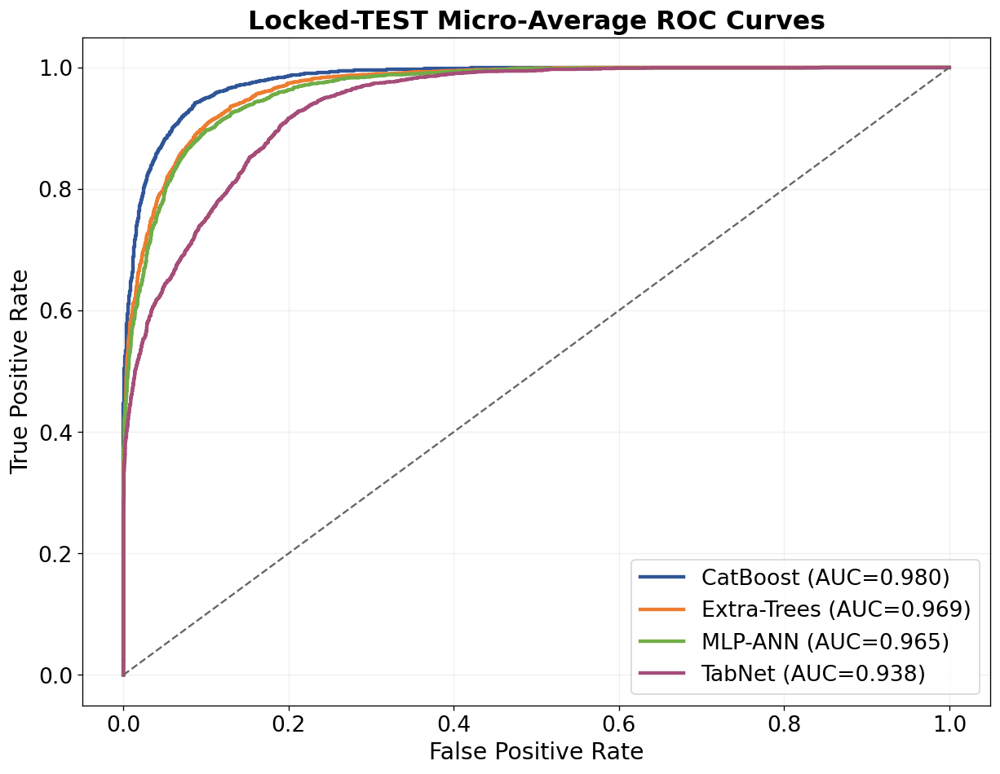

**Locked TEST metrics**

,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Kappa,MCC,Macro_AUC,Micro_AUC,Brier,NLL,ECE,Family,Dataset
0,0.8896,0.8922,0.8896,0.8905,0.8343,0.8347,0.9762,0.9803,0.1565,0.2596,0.0097,CatBoost,Locked TEST
1,0.8600,0.8633,0.8603,0.8613,0.7901,0.7905,0.9637,0.9687,0.1993,0.3302,0.0146,ExtraTrees,Locked TEST
2,0.8550,0.8612,0.8552,0.8570,0.7825,0.7835,0.9588,0.9646,0.2107,0.3560,0.0111,MLP_ANN,Locked TEST
3,0.7756,0.7940,0.7779,0.7722,0.6642,0.6780,0.9377,0.9376,0.2880,0.4603,0.0395,TabNet,Locked TEST


**Development and locked-TEST performance**

,Family,Dataset,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Kappa,MCC,Macro_AUC,Micro_AUC
0,CatBoost,Spatial CV mean ± SD,0.8974 ± 0.0086,0.8994 ± 0.0094,0.8977 ± 0.0098,0.8977 ± 0.0093,0.8455 ± 0.0132,0.8464 ± 0.0133,0.9769 ± 0.0035,0.9810 ± 0.0026
1,CatBoost,Locked TEST,0.8896,0.8922,0.8896,0.8905,0.8343,0.8347,0.9762,0.9803
2,ExtraTrees,Spatial CV mean ± SD,0.8630 ± 0.0059,0.8657 ± 0.0068,0.8630 ± 0.0050,0.8634 ± 0.0053,0.7936 ± 0.0092,0.7945 ± 0.0092,0.9634 ± 0.0020,0.9683 ± 0.0023
3,ExtraTrees,Locked TEST,0.8600,0.8633,0.8603,0.8613,0.7901,0.7905,0.9637,0.9687
4,MLP_ANN,Spatial CV mean ± SD,0.8550 ± 0.0081,0.8593 ± 0.0042,0.8554 ± 0.0073,0.8561 ± 0.0057,0.7817 ± 0.0120,0.7829 ± 0.0115,0.9574 ± 0.0030,0.9638 ± 0.0028
5,MLP_ANN,Locked TEST,0.8550,0.8612,0.8552,0.8570,0.7825,0.7835,0.9588,0.9646
6,TabNet,Spatial CV mean ± SD,0.8215 ± 0.0187,0.8297 ± 0.0281,0.8214 ± 0.0202,0.8205 ± 0.0246,0.7311 ± 0.0285,0.7359 ± 0.0285,0.9464 ± 0.0090,0.9509 ± 0.0066
7,TabNet,Locked TEST,0.7756,0.7940,0.7779,0.7722,0.6642,0.6780,0.9377,0.9376


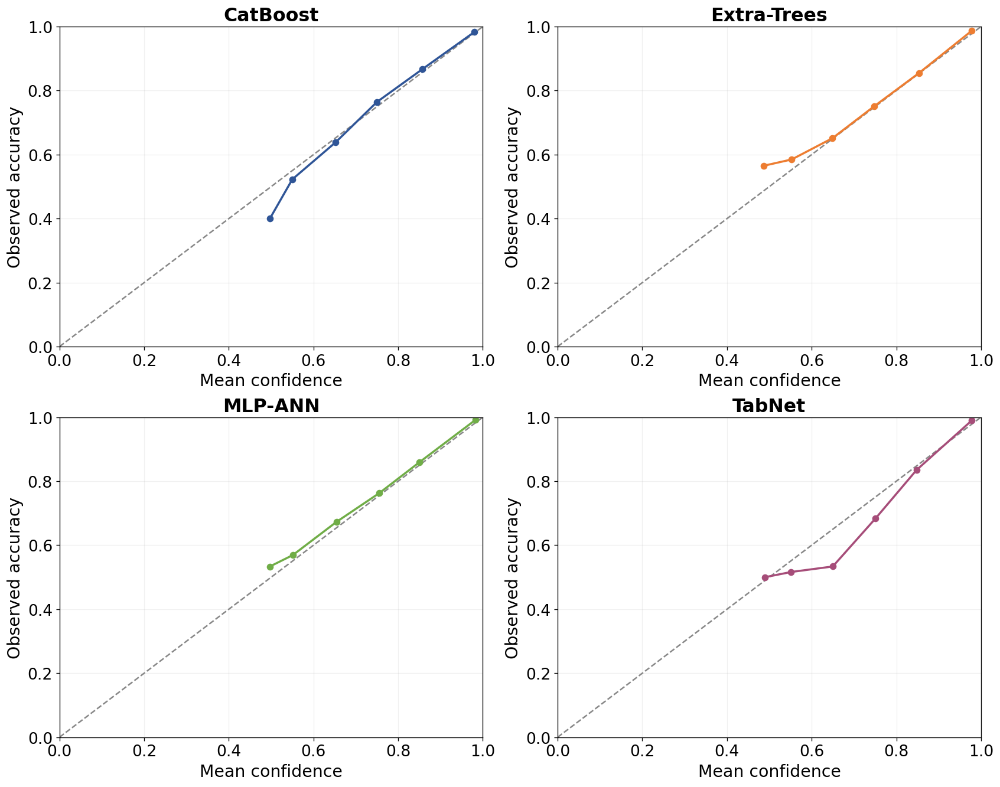

[DONE] LOCKED TEST PERFORMANCE | elapsed 0.23 min


In [28]:
stage('LOCKED TEST PERFORMANCE'); _t0=time.time(); test_rows=[]
fig,ax=plt.subplots(figsize=(10.5,8.2))
MODEL_COLORS={'CatBoost':'#2F5597','ExtraTrees':'#ED7D31','MLP_ANN':'#70AD47','TabNet':'#A64D79'}
for family in MODEL_FAMILIES:
    df=TEST_PRED[family]; y=df.Target.to_numpy(int); p=df[[f'P{j}_Cal' for j in range(3)]].to_numpy(float); met=metric_dict(y,p); met.update({'Family':family,'Dataset':'Locked TEST'}); test_rows.append(met)
    Y=label_binarize(y,classes=[0,1,2]); fpr,tpr,_=roc_curve(Y.ravel(),p.ravel()); auc=met['Micro_AUC']; ax.plot(fpr,tpr,lw=2.6,label=f'{model_label(family)} (AUC={auc:.3f})',color=MODEL_COLORS[family])
ax.plot([0,1],[0,1],'--',color='#666666',lw=1.4); ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.set_title('Locked-TEST Micro-Average ROC Curves',fontweight='bold'); ax.legend(loc='lower right',frameon=True); ax.grid(alpha=.18); fig.tight_layout(); save_figure(fig,DIRS['figures']/'Figure_Locked_TEST_ROC_All_Models.png'); plt.show(); plt.close(fig)
TEST_METRICS=pd.DataFrame(test_rows); TEST_METRICS.to_csv(DIRS['tables']/'Locked_TEST_Metrics_All_Models.csv',index=False); show_table(TEST_METRICS,'Locked TEST metrics')
# Development mean ± SD alongside final test values.
metric_cols=['Accuracy','Macro_Precision','Macro_Recall','Macro_F1','Kappa','MCC','Macro_AUC','Micro_AUC']
dev_summary=DEV_FOLDS.groupby('Family')[metric_cols].agg(['mean','std'])
comparison=[]
for fam in MODEL_FAMILIES:
    r={'Family':fam,'Dataset':'Spatial CV mean ± SD'}
    for m in metric_cols: r[m]=f"{dev_summary.loc[fam,(m,'mean')]:.4f} ± {dev_summary.loc[fam,(m,'std')]:.4f}"
    comparison.append(r); tr=TEST_METRICS[TEST_METRICS.Family==fam].iloc[0]; comparison.append({'Family':fam,'Dataset':'Locked TEST',**{m:f'{tr[m]:.4f}' for m in metric_cols}})
PERF_TABLE=pd.DataFrame(comparison); PERF_TABLE.to_csv(DIRS['tables']/'Development_and_LockedTEST_Performance.csv',index=False); show_table(PERF_TABLE,'Development and locked-TEST performance')
# Compact reliability curves based on confidence bins.
fig,axes=plt.subplots(2,2,figsize=(14,11),constrained_layout=True)
for ax,fam in zip(axes.ravel(),MODEL_FAMILIES):
    df=TEST_PRED[fam]; y=df.Target.to_numpy(int); p=df[[f'P{j}_Cal' for j in range(3)]].to_numpy(float); conf=p.max(1); acc=(p.argmax(1)==y).astype(float); bins=np.linspace(0,1,11); xs=[]; ys=[]
    for lo,hi in zip(bins[:-1],bins[1:]):
        m=(conf>=lo)&((conf<hi) if hi<1 else conf<=hi)
        if m.any(): xs.append(conf[m].mean()); ys.append(acc[m].mean())
    ax.plot([0,1],[0,1],'--',color='#888888'); ax.plot(xs,ys,'o-',lw=2.1,color=MODEL_COLORS[fam]); ax.set_title(model_label(fam),fontweight='bold'); ax.set_xlabel('Mean confidence'); ax.set_ylabel('Observed accuracy'); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.grid(alpha=.18)
save_figure(fig,DIRS['figures']/'Figure_Locked_TEST_Reliability_All_Models.png'); plt.show(); plt.close(fig)
finish('LOCKED TEST PERFORMANCE',_t0)


## 23. Ordinary class-conditional conformal prediction and GeoConformal Prediction



ORDINARY CP + GEOCONFORMAL PREDICTION
Started: 2026-09-30 12:23:32

Nominal coverage: 90%


GeoCP local quantiles h=1 km:   0%|          | 0/6 [00:00<?, ?it/s]

GeoCP local quantiles h=2 km:   0%|          | 0/6 [00:00<?, ?it/s]

GeoCP local quantiles h=3 km:   0%|          | 0/6 [00:00<?, ?it/s]

GeoCP local quantiles h=5 km:   0%|          | 0/6 [00:00<?, ?it/s]

...

**Ordinary CP versus GeoCP on locked TEST**

,Method,Alpha,Bandwidth_m,Coverage,Mean_Set_Size,Singleton_Rate,Empty_Rate,MultiLabel_Rate
0,Ordinary class-conditional CP,0.1000,—,0.8772,0.9784,0.9746,0.0235,0.0019
1,GeoCP Gaussian,0.1000,5000.0000,0.8692,0.9838,0.9426,0.0368,0.0206
2,Ordinary class-conditional CP,0.0500,—,0.9353,1.1139,0.8861,0.0000,0.1139
3,GeoCP Gaussian,0.0500,15000.0000,0.9295,1.1066,0.8934,0.0000,0.1066


GeoCP local quantiles h=5 km:   0%|          | 0/30 [00:00<?, ?it/s]

**SW reliability from exact 20,700 points, 90%**

,SWID,Ordinary_Singleton_Rate,Ordinary_Mean_Set_Size,GeoCP_Singleton_Rate,GeoCP_Mean_Set_Size
0,SW01,98.4444,0.9867,87.0000,1.0300
1,SW02,98.0000,0.9822,91.0000,0.9478
2,SW03,98.5556,0.9922,97.5556,0.9800
3,SW04,97.7778,0.9844,96.0000,0.9622
4,SW05,99.0000,0.9967,96.5556,0.9656
5,SW06,99.0000,0.9900,97.0000,0.9700
6,SW07,98.4444,0.9911,91.8889,0.9189
7,SW08,97.5556,0.9778,94.3333,0.9433
8,SW09,97.1111,0.9756,96.6667,0.9667
9,SW10,97.4444,0.9744,97.3333,0.9733


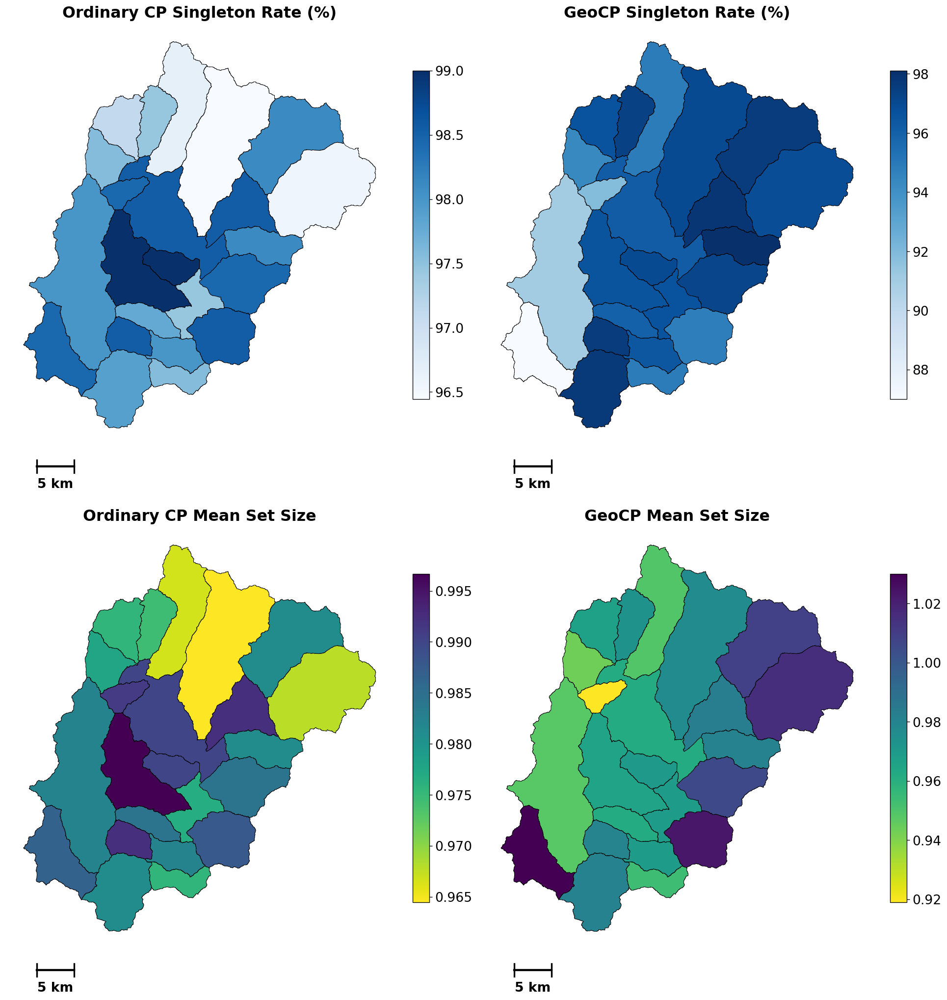

[DONE] ORDINARY CP + GEOCONFORMAL PREDICTION | elapsed 0.97 min


In [29]:
stage('ORDINARY CP + GEOCONFORMAL PREDICTION'); _t0=time.time()
SELECTED_CAL=CAL_PRED[SELECTED_MODEL].copy(); SELECTED_TEST=TEST_PRED[SELECTED_MODEL].copy()
H_CANDIDATES_M=np.array([1000,2000,3000,5000,7500,10000,15000],dtype=float)

def conformal_scores(df):
    p=df[[f'P{j}_Cal' for j in range(3)]].to_numpy(float); y=df.Target.to_numpy(int); return 1.0-p[np.arange(len(df)),y]

def quantile_higher(values,q):
    values=np.asarray(values,float); q=float(np.clip(q,0,1))
    try: return float(np.quantile(values,q,method='higher'))
    except TypeError: return float(np.quantile(values,q,interpolation='higher'))

def ordinary_thresholds(cal_df,alpha):
    scores=conformal_scores(cal_df); y=cal_df.Target.to_numpy(int); out={}
    for c in range(3):
        v=scores[y==c]; n=len(v); q=min(1.0,math.ceil((n+1)*(1-alpha))/max(n,1)); out[c]=quantile_higher(v,q)
    return out

def weighted_quantile(values,weights,q,fallback):
    v=np.asarray(values,float); w=np.asarray(weights,float); good=np.isfinite(v)&np.isfinite(w)&(w>0)
    if good.sum()==0 or w[good].sum()<=0: return float(fallback)
    v=v[good]; w=w[good]; order=np.argsort(v); v=v[order]; w=w[order]; cw=np.cumsum(w)/w.sum(); return float(v[min(np.searchsorted(cw,q,side='left'),len(v)-1)])

def geo_threshold_matrix(query_xy,cal_df,h,alpha,exclude_query_cal_index=None,chunk=512):
    cal_xy=cal_df[['X_UTM','Y_UTM']].to_numpy(float); y=cal_df.Target.to_numpy(int); scores=conformal_scores(cal_df); ordinary=ordinary_thresholds(cal_df,alpha)
    Q=np.zeros((len(query_xy),3),float)
    for start in tqdm(range(0,len(query_xy),chunk),desc=f'GeoCP local quantiles h={h/1000:g} km',leave=False):
        stop=min(start+chunk,len(query_xy)); d=cdist(np.asarray(query_xy[start:stop],float),cal_xy); W=np.exp(-0.5*(d/float(h))**2)
        for ii in range(stop-start):
            global_i=start+ii
            for c in range(3):
                m=(y==c); wc=W[ii,m].copy(); vc=scores[m]
                if exclude_query_cal_index is not None:
                    excluded=int(exclude_query_cal_index[global_i]); class_indices=np.where(m)[0]; hit=np.where(class_indices==excluded)[0]
                    if len(hit): wc[hit[0]]=0.0
                Q[global_i,c]=weighted_quantile(vc,wc,1-alpha,ordinary[c])
    return Q

def prediction_sets_from_thresholds(p,thresholds):
    scores=1.0-np.asarray(p,float)
    if isinstance(thresholds,dict): q=np.array([thresholds[c] for c in range(3)])[None,:]
    else: q=np.asarray(thresholds,float)
    return scores<=q

def cp_metrics(y,sets):
    y=np.asarray(y,int); covered=sets[np.arange(len(y)),y]; sizes=sets.sum(1)
    return {'Coverage':float(covered.mean()),'Mean_Set_Size':float(sizes.mean()),'Singleton_Rate':float((sizes==1).mean()),'Empty_Rate':float((sizes==0).mean()),'MultiLabel_Rate':float((sizes>1).mean())}

def tune_geocp(cal_df,alpha):
    xy=cal_df[['X_UTM','Y_UTM']].to_numpy(float); p=cal_df[[f'P{j}_Cal' for j in range(3)]].to_numpy(float); y=cal_df.Target.to_numpy(int); rows=[]
    exclusion=np.arange(len(cal_df),dtype=int)
    for h in H_CANDIDATES_M:
        Q=geo_threshold_matrix(xy,cal_df,h,alpha,exclude_query_cal_index=exclusion); sets=prediction_sets_from_thresholds(p,Q); met=cp_metrics(y,sets); rows.append({'Bandwidth_m':h,**met})
    tab=pd.DataFrame(rows); valid=tab[tab.Coverage>=1-alpha-1e-12]
    if len(valid): chosen=valid.sort_values(['Mean_Set_Size','Bandwidth_m']).iloc[0]
    else: chosen=tab.sort_values(['Coverage','Mean_Set_Size','Bandwidth_m'],ascending=[False,True,True]).iloc[0]
    return tab,float(chosen.Bandwidth_m)

CP_RESULTS=[]; GEOPARAMS={}
for alpha in [0.10,0.05]:
    print(f'\nNominal coverage: {(1-alpha)*100:.0f}%')
    ordinary=ordinary_thresholds(SELECTED_CAL,alpha); test_p=SELECTED_TEST[[f'P{j}_Cal' for j in range(3)]].to_numpy(float); test_y=SELECTED_TEST.Target.to_numpy(int)
    oset=prediction_sets_from_thresholds(test_p,ordinary); om=cp_metrics(test_y,oset); CP_RESULTS.append({'Method':'Ordinary class-conditional CP','Alpha':alpha,'Bandwidth_m':np.nan,**om})
    tune,h=tune_geocp(SELECTED_CAL,alpha); tune.to_csv(DIRS['tables']/f'GeoCP_Bandwidth_Tuning_{int((1-alpha)*100)}pct.csv',index=False); show_table(tune,f'GeoCP calibration LOO bandwidth audit, {(1-alpha)*100:.0f}%')
    Qtest=geo_threshold_matrix(SELECTED_TEST[['X_UTM','Y_UTM']].to_numpy(float),SELECTED_CAL,h,alpha); gset=prediction_sets_from_thresholds(test_p,Qtest); gm=cp_metrics(test_y,gset); CP_RESULTS.append({'Method':'GeoCP Gaussian','Alpha':alpha,'Bandwidth_m':h,**gm}); GEOPARAMS[alpha]={'ordinary':ordinary,'h':h}
CP_TABLE=pd.DataFrame(CP_RESULTS); CP_TABLE.to_csv(DIRS['tables']/'Conformal_TEST_Performance.csv',index=False); show_table(CP_TABLE,'Ordinary CP versus GeoCP on locked TEST')
save_json(DIRS['metadata']/'GeoCP_Selected_Bandwidths.json',{str(k):v for k,v in GEOPARAMS.items()})

# Apply 90% sets to all exact 20,700 study points for SW reliability aggregation.
all_df=data.copy(); bundle=FINAL_BUNDLES[SELECTED_MODEL]; cali=FINAL_CALIBRATORS[SELECTED_MODEL]
pu,_,_,_=bundle.predict_uncalibrated(all_df); pall=cali.transform(pu); ordinary90=GEOPARAMS[0.10]['ordinary']; h90=GEOPARAMS[0.10]['h']
oset=prediction_sets_from_thresholds(pall,ordinary90); Qall=geo_threshold_matrix(all_df[['X_UTM','Y_UTM']].to_numpy(float),SELECTED_CAL,h90,.10,chunk=700); gset=prediction_sets_from_thresholds(pall,Qall)
rel=all_df[['Point_ID','SWID']].copy(); rel['Ordinary_Set_Size']=oset.sum(1); rel['GeoCP_Set_Size']=gset.sum(1); rel['Ordinary_Singleton']=(rel.Ordinary_Set_Size==1).astype(int); rel['GeoCP_Singleton']=(rel.GeoCP_Set_Size==1).astype(int)
SW_RELIABILITY=rel.groupby('SWID').agg(Ordinary_Singleton_Rate=('Ordinary_Singleton','mean'),Ordinary_Mean_Set_Size=('Ordinary_Set_Size','mean'),GeoCP_Singleton_Rate=('GeoCP_Singleton','mean'),GeoCP_Mean_Set_Size=('GeoCP_Set_Size','mean')).reset_index()
for c in ['Ordinary_Singleton_Rate','GeoCP_Singleton_Rate']: SW_RELIABILITY[c]*=100
SW_RELIABILITY.to_csv(DIRS['tables']/'SW_OrdinaryCP_GeoCP_Reliability_90pct.csv',index=False); show_table(SW_RELIABILITY,'SW reliability from exact 20,700 points, 90%')

# Reliability figure: internal SW boundaries are meaningful here.
sw_plot=ensure_swid_column(gpd.read_file(sw_shp).to_crs(CRS)); sw_plot=sw_plot.merge(SW_RELIABILITY,on='SWID',how='left')
fig,axes=plt.subplots(2,2,figsize=(16,17),constrained_layout=True)
for ax,col,title,cmap in [
 (axes[0,0],'Ordinary_Singleton_Rate','Ordinary CP Singleton Rate (%)','Blues'),(axes[0,1],'GeoCP_Singleton_Rate','GeoCP Singleton Rate (%)','Blues'),
 (axes[1,0],'Ordinary_Mean_Set_Size','Ordinary CP Mean Set Size','viridis_r'),(axes[1,1],'GeoCP_Mean_Set_Size','GeoCP Mean Set Size','viridis_r')]:
    sw_plot.plot(column=col,ax=ax,cmap=cmap,edgecolor='black',linewidth=.55,legend=True,legend_kwds={'shrink':.72}); ax.set_title(title,fontweight='bold'); ax.set_axis_off(); add_scale_bar_below(ax,maxx-minx,SCALE_BAR_M)
save_figure(fig,DIRS['figures']/'Figure_OrdinaryCP_vs_GeoCP_SW_Reliability_90pct.png'); plt.show(); plt.close(fig)
del pu,pall,Qall; finish('ORDINARY CP + GEOCONFORMAL PREDICTION',_t0); cleanup()


In [49]:
# =============================================================================
# FINAL CONFORMAL RELIABILITY DIAGNOSTICS
# USES THE ACTUAL RETAINED 90% ORDINARY CP AND GEOCP SETS
# =============================================================================

stage('FINAL CONFORMAL SW RELIABILITY DIAGNOSTICS')
_t0 = time.time()

import numpy as np
import pandas as pd


# =============================================================================
# 1. VERIFY REQUIRED RETAINED OBJECTS
# =============================================================================

required_objects = [
    'data',
    'oset',
    'gset',
    'SW_RELIABILITY'
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        'Required retained conformal objects are missing: '
        f'{missing_objects}'
    )


# =============================================================================
# 2. STRICT DATA AUDIT
# =============================================================================

if len(data) != 20700:
    raise RuntimeError(
        f'Expected 20,700 modelling observations; found {len(data):,}.'
    )

required_columns = [
    'SWID',
    'Target',
    'Split'
]

missing_columns = [
    c
    for c in required_columns
    if c not in data.columns
]

if missing_columns:
    raise RuntimeError(
        f'Required columns missing from data: {missing_columns}'
    )


# =============================================================================
# 3. VALIDATE ACTUAL ORDINARY CP AND GEOCP SET ARRAYS
# =============================================================================

oset_arr = np.asarray(oset)
gset_arr = np.asarray(gset)

expected_shape = (
    len(data),
    3
)

if oset_arr.shape != expected_shape:
    raise RuntimeError(
        f'Ordinary CP set array shape is {oset_arr.shape}; '
        f'expected {expected_shape}.'
    )

if gset_arr.shape != expected_shape:
    raise RuntimeError(
        f'GeoCP set array shape is {gset_arr.shape}; '
        f'expected {expected_shape}.'
    )


def validate_set_matrix(arr, label):

    try:
        numeric = arr.astype(float)
    except Exception as exc:
        raise RuntimeError(
            f'{label} cannot be converted to a numeric '
            f'prediction-set membership matrix: {exc}'
        )

    if not np.isfinite(numeric).all():
        raise RuntimeError(
            f'{label} contains non-finite values.'
        )

    unique_values = set(
        np.unique(numeric).tolist()
    )

    if not unique_values.issubset(
        {
            0.0,
            1.0
        }
    ):
        raise RuntimeError(
            f'{label} is not a binary 0/1 membership matrix. '
            f'Values found: {sorted(unique_values)}'
        )

    return numeric.astype(bool)


oset_bool = validate_set_matrix(
    oset_arr,
    'Ordinary CP sets'
)

gset_bool = validate_set_matrix(
    gset_arr,
    'GeoCP sets'
)


print(
    'Ordinary CP retained sets:',
    oset_bool.shape
)

print(
    'GeoCP retained sets     :',
    gset_bool.shape
)


# =============================================================================
# 4. CALCULATE ACTUAL SET SIZES FOR ALL 20,700 OBSERVATIONS
# =============================================================================

ordinary_size_all = oset_bool.sum(
    axis=1
).astype(int)

geocp_size_all = gset_bool.sum(
    axis=1
).astype(int)


for name, values in [
    (
        'Ordinary CP',
        ordinary_size_all
    ),
    (
        'GeoCP',
        geocp_size_all
    )
]:

    observed_sizes = sorted(
        np.unique(values).tolist()
    )

    if not set(observed_sizes).issubset(
        {
            0,
            1,
            2,
            3
        }
    ):
        raise RuntimeError(
            f'{name} contains invalid prediction-set sizes: '
            f'{observed_sizes}'
        )

    print(
        f'{name:12s} set sizes present:',
        observed_sizes
    )


# =============================================================================
# 5. REPRODUCE THE EXISTING SW_RELIABILITY TABLE
# =============================================================================
#
# IMPORTANT:
# This is the validation step.
#
# We do NOT assume oset/gset generated the existing reliability maps.
# We calculate singleton rate and mean set size from them and compare
# directly against the already-created SW_RELIABILITY object.
# =============================================================================

verification_rows = []

swids = sorted(
    data[
        'SWID'
    ]
    .astype(str)
    .unique()
)


if len(swids) != 23:
    raise RuntimeError(
        f'Expected 23 SWs; found {len(swids)}.'
    )


for swid in swids:

    sw_mask = (
        data[
            'SWID'
        ]
        .astype(str)
        .to_numpy()
        ==
        swid
    )

    n_sw = int(
        sw_mask.sum()
    )

    o_size = ordinary_size_all[
        sw_mask
    ]

    g_size = geocp_size_all[
        sw_mask
    ]

    verification_rows.append(
        {
            'SWID':
                swid,

            'N_All':
                n_sw,

            'Ordinary_Singleton_Rate_Calc':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        ==
                        1
                    )
                ),

            'Ordinary_Mean_Set_Size_Calc':
                float(
                    np.mean(
                        o_size
                    )
                ),

            'GeoCP_Singleton_Rate_Calc':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        ==
                        1
                    )
                ),

            'GeoCP_Mean_Set_Size_Calc':
                float(
                    np.mean(
                        g_size
                    )
                )
        }
    )


verification = pd.DataFrame(
    verification_rows
)


verification = verification.merge(
    SW_RELIABILITY,
    on='SWID',
    how='left',
    validate='one_to_one'
)


comparison_pairs = [
    (
        'Ordinary_Singleton_Rate_Calc',
        'Ordinary_Singleton_Rate'
    ),
    (
        'Ordinary_Mean_Set_Size_Calc',
        'Ordinary_Mean_Set_Size'
    ),
    (
        'GeoCP_Singleton_Rate_Calc',
        'GeoCP_Singleton_Rate'
    ),
    (
        'GeoCP_Mean_Set_Size_Calc',
        'GeoCP_Mean_Set_Size'
    )
]


for calc_col, existing_col in comparison_pairs:

    verification[
        f'Diff_{existing_col}'
    ] = (
        verification[
            calc_col
        ]
        -
        verification[
            existing_col
        ]
    )


max_abs_diff = max(
    float(
        np.nanmax(
            np.abs(
                verification[
                    f'Diff_{existing_col}'
                ]
            )
        )
    )
    for _, existing_col
    in comparison_pairs
)


print(
    '\nMaximum absolute difference against '
    'existing SW_RELIABILITY:',
    f'{max_abs_diff:.12f}'
)


if max_abs_diff > 1e-8:

    show_table(
        verification,
        'FAILED verification of retained conformal sets',
        max_rows=30
    )

    raise RuntimeError(
        'The retained oset/gset arrays do not exactly reproduce '
        'the existing SW_RELIABILITY table. '
        'Stop rather than mixing inconsistent conformal outputs.'
    )


print(
    '[PASS] oset and gset exactly reproduce '
    'the existing 23-SW reliability calculations.'
)


# =============================================================================
# 6. LOCK TEST PARTITION
# =============================================================================

test_mask = (
    data[
        'Split'
    ]
    .astype(str)
    .str.strip()
    .str.upper()
    .to_numpy()
    ==
    'TEST'
)


n_test = int(
    test_mask.sum()
)


if n_test != 3151:
    raise RuntimeError(
        f'Expected locked TEST size of 3,151; found {n_test:,}.'
    )


test_data = (
    data.loc[
        test_mask,
        [
            'SWID',
            'Target'
        ]
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


if 'Point_ID' in data.columns:

    test_data.insert(
        0,
        'Point_ID',
        data.loc[
            test_mask,
            'Point_ID'
        ].to_numpy()
    )


y_test = (
    test_data[
        'Target'
    ]
    .to_numpy(
        dtype=int
    )
)


if not np.isin(
    y_test,
    [
        0,
        1,
        2
    ]
).all():

    raise RuntimeError(
        'TEST Target contains values outside classes 0, 1 and 2.'
    )


ordinary_test_sets = oset_bool[
    test_mask
]

geocp_test_sets = gset_bool[
    test_mask
]


ordinary_test_size = ordinary_size_all[
    test_mask
]

geocp_test_size = geocp_size_all[
    test_mask
]


# =============================================================================
# 7. TRUE EMPIRICAL COVERAGE ON LOCKED TEST ONLY
# =============================================================================

row_index = np.arange(
    n_test
)


ordinary_test_covered = ordinary_test_sets[
    row_index,
    y_test
]


geocp_test_covered = geocp_test_sets[
    row_index,
    y_test
]


test_data[
    'Ordinary_Covered'
] = ordinary_test_covered.astype(
    bool
)


test_data[
    'Ordinary_Set_Size'
] = ordinary_test_size


test_data[
    'GeoCP_Covered'
] = geocp_test_covered.astype(
    bool
)


test_data[
    'GeoCP_Set_Size'
] = geocp_test_size


# =============================================================================
# 8. OVERALL LOCKED-TEST CONFORMAL PERFORMANCE
# =============================================================================

CONFORMAL_TEST_DIAGNOSTICS = pd.DataFrame(
    [
        {
            'Method':
                'Ordinary CP',

            'N_Test':
                n_test,

            'Coverage_pct':
                float(
                    100.0
                    *
                    ordinary_test_covered.mean()
                ),

            'Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        ordinary_test_size
                        ==
                        1
                    )
                ),

            'Mean_Set_Size':
                float(
                    ordinary_test_size.mean()
                ),

            'Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        ordinary_test_size
                        ==
                        0
                    )
                ),

            'MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        ordinary_test_size
                        >
                        1
                    )
                ),

            'Two_Class_pct':
                float(
                    100.0
                    *
                    np.mean(
                        ordinary_test_size
                        ==
                        2
                    )
                ),

            'Three_Class_pct':
                float(
                    100.0
                    *
                    np.mean(
                        ordinary_test_size
                        ==
                        3
                    )
                )
        },

        {
            'Method':
                'GeoCP',

            'N_Test':
                n_test,

            'Coverage_pct':
                float(
                    100.0
                    *
                    geocp_test_covered.mean()
                ),

            'Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        geocp_test_size
                        ==
                        1
                    )
                ),

            'Mean_Set_Size':
                float(
                    geocp_test_size.mean()
                ),

            'Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        geocp_test_size
                        ==
                        0
                    )
                ),

            'MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        geocp_test_size
                        >
                        1
                    )
                ),

            'Two_Class_pct':
                float(
                    100.0
                    *
                    np.mean(
                        geocp_test_size
                        ==
                        2
                    )
                ),

            'Three_Class_pct':
                float(
                    100.0
                    *
                    np.mean(
                        geocp_test_size
                        ==
                        3
                    )
                )
        }
    ]
)


# =============================================================================
# 9. CLASS-SPECIFIC TEST COVERAGE
# =============================================================================

class_rows = []


for cls in [
    0,
    1,
    2
]:

    cls_mask = (
        y_test
        ==
        cls
    )

    n_cls = int(
        cls_mask.sum()
    )

    if n_cls == 0:
        raise RuntimeError(
            f'TEST contains no observations for Target {cls}.'
        )

    class_rows.append(
        {
            'Target':
                cls,

            'N_Test':
                n_cls,

            'Ordinary_Coverage_pct':
                float(
                    100.0
                    *
                    ordinary_test_covered[
                        cls_mask
                    ].mean()
                ),

            'GeoCP_Coverage_pct':
                float(
                    100.0
                    *
                    geocp_test_covered[
                        cls_mask
                    ].mean()
                ),

            'Ordinary_Mean_Set_Size':
                float(
                    ordinary_test_size[
                        cls_mask
                    ].mean()
                ),

            'GeoCP_Mean_Set_Size':
                float(
                    geocp_test_size[
                        cls_mask
                    ].mean()
                )
        }
    )


CONFORMAL_CLASS_DIAGNOSTICS = pd.DataFrame(
    class_rows
)


# =============================================================================
# 10. LOCKED TEST DIAGNOSTICS BY SW
# =============================================================================
#
# This table is appropriate for empirical coverage assessment because
# it uses ONLY the untouched TEST observations.
# =============================================================================

sw_test_rows = []


for swid, q_idx in (
    test_data
    .groupby(
        'SWID',
        sort=True
    )
    .groups
    .items()
):

    idx = np.asarray(
        list(
            q_idx
        ),
        dtype=int
    )

    o_size = ordinary_test_size[
        idx
    ]

    g_size = geocp_test_size[
        idx
    ]

    o_cov = ordinary_test_covered[
        idx
    ]

    g_cov = geocp_test_covered[
        idx
    ]


    sw_test_rows.append(
        {
            'SWID':
                str(
                    swid
                ),

            'SW_Name':
                SW_NAMES.get(
                    str(
                        swid
                    ),
                    str(
                        swid
                    )
                ),

            'N_Test':
                int(
                    len(
                        idx
                    )
                ),

            # ---------------------------------------------------------
            # Empirical coverage
            # ---------------------------------------------------------

            'Ordinary_Coverage_pct':
                float(
                    100.0
                    *
                    o_cov.mean()
                ),

            'GeoCP_Coverage_pct':
                float(
                    100.0
                    *
                    g_cov.mean()
                ),

            # ---------------------------------------------------------
            # Singleton rate
            # ---------------------------------------------------------

            'Ordinary_Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        ==
                        1
                    )
                ),

            'GeoCP_Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        ==
                        1
                    )
                ),

            # ---------------------------------------------------------
            # Mean prediction-set size
            # ---------------------------------------------------------

            'Ordinary_Mean_Set_Size':
                float(
                    o_size.mean()
                ),

            'GeoCP_Mean_Set_Size':
                float(
                    g_size.mean()
                ),

            # ---------------------------------------------------------
            # Empty sets
            # ---------------------------------------------------------

            'Ordinary_Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        ==
                        0
                    )
                ),

            'GeoCP_Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        ==
                        0
                    )
                ),

            # ---------------------------------------------------------
            # Multi-label / ambiguous sets
            # ---------------------------------------------------------

            'Ordinary_MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        >
                        1
                    )
                ),

            'GeoCP_MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        >
                        1
                    )
                )
        }
    )


CONFORMAL_SW_TEST_DIAGNOSTICS = pd.DataFrame(
    sw_test_rows
)


if len(
    CONFORMAL_SW_TEST_DIAGNOSTICS
) != 23:

    raise RuntimeError(
        'Locked TEST reliability table does not contain all 23 SWs.'
    )


if int(
    CONFORMAL_SW_TEST_DIAGNOSTICS[
        'N_Test'
    ].sum()
) != n_test:

    raise RuntimeError(
        'SW TEST counts do not sum to the locked 3,151 observations.'
    )


# =============================================================================
# 11. FULL 20,700-POINT SPATIAL RELIABILITY TABLE
# =============================================================================
#
# This corresponds to the spatial reliability maps.
#
# It is deliberately kept separate from locked TEST empirical coverage.
# =============================================================================

full_rows = []


target_all = (
    data[
        'Target'
    ]
    .to_numpy(
        dtype=int
    )
)


row_all = np.arange(
    len(
        data
    )
)


ordinary_covered_all = oset_bool[
    row_all,
    target_all
]


geocp_covered_all = gset_bool[
    row_all,
    target_all
]


swid_all = (
    data[
        'SWID'
    ]
    .astype(str)
    .to_numpy()
)


for swid in swids:

    m = (
        swid_all
        ==
        swid
    )

    o_size = ordinary_size_all[
        m
    ]

    g_size = geocp_size_all[
        m
    ]


    full_rows.append(
        {
            'SWID':
                swid,

            'SW_Name':
                SW_NAMES.get(
                    swid,
                    swid
                ),

            'N_All':
                int(
                    m.sum()
                ),

            'Ordinary_Coverage_pct':
                float(
                    100.0
                    *
                    ordinary_covered_all[
                        m
                    ].mean()
                ),

            'GeoCP_Coverage_pct':
                float(
                    100.0
                    *
                    geocp_covered_all[
                        m
                    ].mean()
                ),

            'Ordinary_Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        ==
                        1
                    )
                ),

            'GeoCP_Singleton_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        ==
                        1
                    )
                ),

            'Ordinary_Mean_Set_Size':
                float(
                    o_size.mean()
                ),

            'GeoCP_Mean_Set_Size':
                float(
                    g_size.mean()
                ),

            'Ordinary_Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        ==
                        0
                    )
                ),

            'GeoCP_Empty_Set_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        ==
                        0
                    )
                ),

            'Ordinary_MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        o_size
                        >
                        1
                    )
                ),

            'GeoCP_MultiLabel_pct':
                float(
                    100.0
                    *
                    np.mean(
                        g_size
                        >
                        1
                    )
                )
        }
    )


CONFORMAL_SW_SPATIAL_DIAGNOSTICS = pd.DataFrame(
    full_rows
)


# =============================================================================
# 12. STRICTLY CONFIRM 900 OBSERVATIONS PER SW FOR SPATIAL TABLE
# =============================================================================

if not (
    CONFORMAL_SW_SPATIAL_DIAGNOSTICS[
        'N_All'
    ]
    ==
    900
).all():

    raise RuntimeError(
        'Full spatial reliability table does not contain '
        'exactly 900 observations in every SW.'
    )


print(
    '[PASS] Full spatial reliability diagnostics contain '
    '900 observations for each of the 23 SWs.'
)


# =============================================================================
# 13. SECOND VERIFICATION AGAINST THE EXISTING MAP-SOURCE TABLE
# =============================================================================

check = (
    CONFORMAL_SW_SPATIAL_DIAGNOSTICS[
        [
            'SWID',
            'Ordinary_Singleton_pct',
            'Ordinary_Mean_Set_Size',
            'GeoCP_Singleton_pct',
            'GeoCP_Mean_Set_Size'
        ]
    ]
    .merge(
        SW_RELIABILITY,
        on='SWID',
        how='left',
        validate='one_to_one'
    )
)


audit_differences = {
    'Ordinary singleton':
        np.max(
            np.abs(
                check[
                    'Ordinary_Singleton_pct'
                ]
                -
                check[
                    'Ordinary_Singleton_Rate'
                ]
            )
        ),

    'Ordinary mean set size':
        np.max(
            np.abs(
                check[
                    'Ordinary_Mean_Set_Size_x'
                ]
                -
                check[
                    'Ordinary_Mean_Set_Size_y'
                ]
            )
        ),

    'GeoCP singleton':
        np.max(
            np.abs(
                check[
                    'GeoCP_Singleton_pct'
                ]
                -
                check[
                    'GeoCP_Singleton_Rate'
                ]
            )
        ),

    'GeoCP mean set size':
        np.max(
            np.abs(
                check[
                    'GeoCP_Mean_Set_Size_x'
                ]
                -
                check[
                    'GeoCP_Mean_Set_Size_y'
                ]
            )
        )
}


for metric, diff in audit_differences.items():

    print(
        f'{metric:28s}: max difference = {diff:.12f}'
    )


if max(
    audit_differences.values()
) > 1e-8:

    raise RuntimeError(
        'Spatial reliability diagnostics do not reproduce '
        'the existing SW_RELIABILITY values.'
    )


print(
    '[PASS] New diagnostics reproduce the existing '
    'Ordinary CP and GeoCP reliability maps exactly.'
)


# =============================================================================
# 14. SAVE OUTPUT TABLES
# =============================================================================

overall_path = (
    DIRS[
        'tables'
    ]
    /
    'Conformal_TEST_Diagnostics_90pct.csv'
)


class_path = (
    DIRS[
        'tables'
    ]
    /
    'Conformal_TEST_Class_Specific_Diagnostics_90pct.csv'
)


sw_test_path = (
    DIRS[
        'tables'
    ]
    /
    'Conformal_TEST_23SW_Diagnostics_90pct.csv'
)


sw_spatial_path = (
    DIRS[
        'tables'
    ]
    /
    'Conformal_Spatial_23SW_Diagnostics_90pct.csv'
)


point_test_path = (
    DIRS[
        'tables'
    ]
    /
    'Conformal_TEST_Point_Level_Diagnostics_90pct.csv'
)


CONFORMAL_TEST_DIAGNOSTICS.to_csv(
    overall_path,
    index=False
)


CONFORMAL_CLASS_DIAGNOSTICS.to_csv(
    class_path,
    index=False
)


CONFORMAL_SW_TEST_DIAGNOSTICS.to_csv(
    sw_test_path,
    index=False
)


CONFORMAL_SW_SPATIAL_DIAGNOSTICS.to_csv(
    sw_spatial_path,
    index=False
)


test_data.to_csv(
    point_test_path,
    index=False
)


print(
    '\n[SAVE]',
    overall_path
)

print(
    '[SAVE]',
    class_path
)

print(
    '[SAVE]',
    sw_test_path
)

print(
    '[SAVE]',
    sw_spatial_path
)

print(
    '[SAVE]',
    point_test_path
)


# =============================================================================
# 15. DISPLAY OVERALL TEST RESULTS
# =============================================================================

show_table(
    CONFORMAL_TEST_DIAGNOSTICS,
    'Locked TEST Ordinary CP vs GeoCP diagnostics at 90% coverage',
    precision=4,
    max_rows=10
)


# =============================================================================
# 16. DISPLAY CLASS-SPECIFIC TEST RESULTS
# =============================================================================

show_table(
    CONFORMAL_CLASS_DIAGNOSTICS,
    'Locked TEST class-specific conformal coverage',
    precision=4,
    max_rows=10
)


# =============================================================================
# 17. DISPLAY REQUESTED 23-SW TEST TABLE
# =============================================================================

requested_columns = [
    'SWID',
    'SW_Name',
    'N_Test',

    'Ordinary_Coverage_pct',
    'GeoCP_Coverage_pct',

    'Ordinary_Singleton_pct',
    'GeoCP_Singleton_pct',

    'Ordinary_Mean_Set_Size',
    'GeoCP_Mean_Set_Size',

    'Ordinary_Empty_Set_pct',
    'GeoCP_Empty_Set_pct',

    'Ordinary_MultiLabel_pct',
    'GeoCP_MultiLabel_pct'
]


show_table(
    CONFORMAL_SW_TEST_DIAGNOSTICS[
        requested_columns
    ],
    'Locked TEST conformal reliability across all 23 SWs',
    precision=3,
    max_rows=30
)


# =============================================================================
# 18. DISPLAY SPATIAL RELIABILITY TABLE USED BY THE MAPS
# =============================================================================

show_table(
    CONFORMAL_SW_SPATIAL_DIAGNOSTICS,
    'Full 20,700-point spatial reliability diagnostics for all 23 SWs',
    precision=3,
    max_rows=30
)


# =============================================================================
# 19. PRINT OVERALL INTERPRETATION NUMBERS
# =============================================================================

print(
    '\n'
    +
    '=' * 100
)

print(
    'FINAL CONFORMAL RELIABILITY AUDIT'
)

print(
    '=' * 100
)


for _, r in CONFORMAL_TEST_DIAGNOSTICS.iterrows():

    print(
        f"{r['Method']:12s} | "
        f"TEST coverage = {r['Coverage_pct']:.2f}% | "
        f"Singleton = {r['Singleton_pct']:.2f}% | "
        f"Mean set size = {r['Mean_Set_Size']:.4f} | "
        f"Empty = {r['Empty_Set_pct']:.2f}% | "
        f"Multi-label = {r['MultiLabel_pct']:.2f}%"
    )


print(
    '\nIMPORTANT DISTINCTION'
)

print(
    '1. Coverage statistics above are evaluated on the '
    'locked 3,151 TEST observations.'
)

print(
    '2. The spatial reliability maps use the complete '
    '20,700-point prediction-set inventory, 900 points per SW.'
)

print(
    '3. Ordinary CP and GeoCP prediction sets were NOT regenerated.'
)

print(
    '4. Empty-set and multi-label percentages were calculated '
    'directly from the retained oset/gset matrices.'
)

print(
    '5. Existing SW reliability-map values were reproduced '
    'before the new diagnostics were accepted.'
)


# =============================================================================
# 20. FINISH
# =============================================================================

finish(
    'FINAL CONFORMAL SW RELIABILITY DIAGNOSTICS',
    _t0
)

cleanup()


FINAL CONFORMAL SW RELIABILITY DIAGNOSTICS
Started: 2026-09-30 17:12:42
Ordinary CP retained sets: (20700, 3)
GeoCP retained sets     : (20700, 3)
Ordinary CP  set sizes present: [0, 1, 2]
GeoCP        set sizes present: [0, 1, 2]

Maximum absolute difference against existing SW_RELIABILITY: 0.000000000000
[PASS] oset and gset exactly reproduce the existing 23-SW reliability calculations.
[PASS] Full spatial reliability diagnostics contain 900 observations for each of the 23 SWs.
Ordinary singleton          : max difference = 0.000000000000
Ordinary mean set size      : max difference = 0.000000000000
GeoCP singleton             : max difference = 0.000000000000
GeoCP mean set size         : max difference = 0.000000000000
[PASS] New diagnostics reproduce the existing Ordinary CP and GeoCP reliability maps exactly.

[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Conformal_TEST_Diagnostics_90pct.csv
[SAVE] /content/drive/MyDrive/Mandakini_reu/06_Tables/Conformal_TEST_Class_Speci

**Locked TEST Ordinary CP vs GeoCP diagnostics at 90% coverage**

,Method,N_Test,Coverage_pct,Singleton_pct,Mean_Set_Size,Empty_Set_pct,MultiLabel_pct,Two_Class_pct,Three_Class_pct
0,Ordinary CP,3151,87.7182,97.4611,0.9784,2.3485,0.1904,0.1904,0.0000
1,GeoCP,3151,86.9248,94.2558,0.9838,3.6814,2.0628,2.0628,0.0000


**Locked TEST class-specific conformal coverage**

,Target,N_Test,Ordinary_Coverage_pct,GeoCP_Coverage_pct,Ordinary_Mean_Set_Size,GeoCP_Mean_Set_Size
0,0,1059,88.3853,85.2691,0.9566,0.9273
1,1,1067,84.6298,84.6298,0.9766,1.0047
2,2,1025,90.2439,91.0244,1.0029,1.0205


**Locked TEST conformal reliability across all 23 SWs**

,SWID,SW_Name,N_Test,Ordinary_Coverage_pct,GeoCP_Coverage_pct,Ordinary_Singleton_pct,GeoCP_Singleton_pct,Ordinary_Mean_Set_Size,GeoCP_Mean_Set_Size,Ordinary_Empty_Set_pct,GeoCP_Empty_Set_pct,Ordinary_MultiLabel_pct,GeoCP_MultiLabel_pct
0,SW01,Hilayun Gad,304,87.171,90.132,98.355,82.566,0.990,1.089,1.316,4.276,0.329,13.158
1,SW02,Laster Gad,180,91.667,91.111,96.667,90.556,0.967,0.983,3.333,5.556,0.000,3.889
2,SW03,Chak Gad,99,90.909,87.879,95.960,96.970,1.020,0.970,1.010,3.030,3.030,0.000
3,SW04,Badhani Gad,153,80.392,79.085,98.693,99.346,1.000,0.993,0.654,0.654,0.654,0.000
4,SW05,Damar Gad,59,93.220,89.831,98.305,96.610,0.983,0.966,1.695,3.390,0.000,0.000
5,SW06,Rawan Gad,12,91.667,91.667,100.000,100.000,1.000,1.000,0.000,0.000,0.000,0.000
6,SW07,Pati Gad,157,89.809,86.624,99.363,96.178,0.994,0.962,0.637,3.822,0.000,0.000
7,SW08,Triyungi Narayan Gad,15,86.667,80.000,100.000,93.333,1.000,0.933,0.000,6.667,0.000,0.000
8,SW09,Sina Gad,171,82.456,83.626,94.152,95.322,0.942,0.953,5.848,4.678,0.000,0.000
9,SW10,Vasuki Ganga,29,89.655,86.207,96.552,93.103,0.966,0.931,3.448,6.897,0.000,0.000


**Full 20,700-point spatial reliability diagnostics for all 23 SWs**

,SWID,SW_Name,N_All,Ordinary_Coverage_pct,GeoCP_Coverage_pct,Ordinary_Singleton_pct,GeoCP_Singleton_pct,Ordinary_Mean_Set_Size,GeoCP_Mean_Set_Size,Ordinary_Empty_Set_pct,GeoCP_Empty_Set_pct,Ordinary_MultiLabel_pct,GeoCP_MultiLabel_pct
0,SW01,Hilayun Gad,900,90.667,91.000,98.444,87.000,0.987,1.030,1.444,5.000,0.111,8.000
1,SW02,Laster Gad,900,91.556,89.000,98.000,91.000,0.982,0.948,1.889,7.111,0.111,1.889
2,SW03,Chak Gad,900,90.778,89.778,98.556,97.556,0.992,0.980,1.111,2.222,0.333,0.222
3,SW04,Badhani Gad,900,88.222,86.111,97.778,96.000,0.984,0.962,1.889,3.889,0.333,0.111
4,SW05,Damar Gad,900,91.333,88.556,99.000,96.556,0.997,0.966,0.667,3.444,0.333,0.000
5,SW06,Rawan Gad,900,95.111,93.444,99.000,97.000,0.990,0.970,1.000,3.000,0.000,0.000
6,SW07,Pati Gad,900,90.889,86.667,98.444,91.889,0.991,0.919,1.222,8.111,0.333,0.000
7,SW08,Triyungi Narayan Gad,900,91.333,88.333,97.556,94.333,0.978,0.943,2.333,5.667,0.111,0.000
8,SW09,Sina Gad,900,91.556,90.556,97.111,96.667,0.976,0.967,2.667,3.333,0.222,0.000
9,SW10,Vasuki Ganga,900,93.222,92.889,97.444,97.333,0.974,0.973,2.556,2.667,0.000,0.000



FINAL CONFORMAL RELIABILITY AUDIT
Ordinary CP  | TEST coverage = 87.72% | Singleton = 97.46% | Mean set size = 0.9784 | Empty = 2.35% | Multi-label = 0.19%
GeoCP        | TEST coverage = 86.92% | Singleton = 94.26% | Mean set size = 0.9838 | Empty = 3.68% | Multi-label = 2.06%

IMPORTANT DISTINCTION
1. Coverage statistics above are evaluated on the locked 3,151 TEST observations.
2. The spatial reliability maps use the complete 20,700-point prediction-set inventory, 900 points per SW.
3. Ordinary CP and GeoCP prediction sets were NOT regenerated.
4. Empty-set and multi-label percentages were calculated directly from the retained oset/gset matrices.
5. Existing SW reliability-map values were reproduced before the new diagnostics were accepted.
[DONE] FINAL CONFORMAL SW RELIABILITY DIAGNOSTICS | elapsed 0.00 min


## 24. Full-basin calibrated probability and susceptibility mapping for all four models


In [30]:
stage('FULL-BASIN MODEL PREDICTION'); _t0=time.time()

# Load canonical ECF arrays once, create the common valid basin mask, and predict in explicit chunks.
ECF_ARRAYS={}
FULL_VALID=BASIN_MASK.copy()

for ecf in ECFS:
    with rasterio.open(ALIGNED_PATHS[ecf]) as src:
        arr=src.read(1)
        nd=src.nodata

    if ecf in CATEGORICAL_ECFS:
        good=(arr!=nd) if nd is not None else np.isfinite(arr)
    else:
        good=np.isfinite(arr)
        if nd is not None:
            good &= ~np.isclose(arr,nd)

    FULL_VALID &= good
    ECF_ARRAYS[ecf]=arr

valid_flat=np.flatnonzero(FULL_VALID.ravel())
print('Valid full-basin pixels:',f'{len(valid_flat):,}')

def write_float_raster(path,array,description):
    profile={
        'driver':'GTiff',
        'height':GRID_HEIGHT,
        'width':GRID_WIDTH,
        'count':1,
        'dtype':'float32',
        'crs':CRS,
        'transform':GRID_TRANSFORM,
        'nodata':NODATA_FLOAT,
        'compress':'LZW',
        'tiled':True
    }
    with rasterio.open(path,'w',**profile) as dst:
        dst.write(array.astype(np.float32),1)
        dst.set_band_description(1,description)

def frame_from_flat_indices(indices):
    out={}
    for ecf in ECFS:
        vals=ECF_ARRAYS[ecf].ravel()[indices]
        out[ecf]=(
            np.rint(vals).astype(int)
            if ecf in CATEGORICAL_ECFS
            else vals.astype(float)
        )
    return pd.DataFrame(out,columns=ECFS)

FULL_RASTERS={}

for family in MODEL_FAMILIES:
    print('\nFULL MAP:',model_label(family))

    paths={
        key:DIRS['rasters']/f'{family}_{key}_Calibrated_30m.tif'
        for key in ['P0','P1','P2','S']
    }
    meta_path=DIRS['metadata']/f'{family}_Full_Basin_Rasters.meta.json'

    model_path=DIRS['models']/f'{family}_Final_OrdinalBundle.joblib'
    calibrator_path=DIRS['models']/f'{family}_DirichletCalibrator.joblib'

    raster_sig=hash_payload({
        'family':family,
        'model':sha256_file(model_path),
        'calibrator':sha256_file(calibrator_path),
        'grid':GRID_SIGNATURE,
        'aligned_ecfs':{k:sha256_file(v) for k,v in ALIGNED_PATHS.items()},
        'batch_size':PREDICT_BATCH_SIZE,
    })

    if (
        valid_checkpoint(meta_path,raster_sig)
        and all(p.exists() for p in paths.values())
    ):
        print('[RESTORE validated] calibrated full-basin rasters')
        FULL_RASTERS[family]=paths
        continue

    outputs={
        k:np.full(
            GRID_HEIGHT*GRID_WIDTH,
            NODATA_FLOAT,
            dtype=np.float32
        )
        for k in ['P0','P1','P2','S']
    }

    bundle=FINAL_BUNDLES[family]
    calibrator=FINAL_CALIBRATORS[family]

    for start in tqdm(
        range(0,len(valid_flat),PREDICT_BATCH_SIZE),
        desc=f'{model_label(family)} full-basin chunks'
    ):
        idx=valid_flat[start:start+PREDICT_BATCH_SIZE]
        Xchunk=frame_from_flat_indices(idx)

        pu,_,_,_=bundle.predict_uncalibrated(Xchunk)
        pc=calibrator.transform(pu)

        for j in range(3):
            outputs[f'P{j}'][idx]=pc[:,j].astype(np.float32)

        outputs['S'][idx]=susceptibility_score(pc).astype(np.float32)

        del Xchunk,pu,pc
        cleanup()

    for key,path in paths.items():
        write_float_raster(
            path,
            outputs[key].reshape(GRID_HEIGHT,GRID_WIDTH),
            f'{model_label(family)} {key}'
        )

    save_json(meta_path,{
        'status':'COMPLETE',
        'signature':raster_sig,
        'outputs':{k:str(v) for k,v in paths.items()},
    })

    FULL_RASTERS[family]=paths
    print('[SAVE]',paths['S'])

    del outputs
    cleanup()

finish('FULL-BASIN MODEL PREDICTION',_t0)



FULL-BASIN MODEL PREDICTION
Started: 2026-09-30 12:24:31
Valid full-basin pixels: 1,781,831

FULL MAP: CatBoost


CatBoost full-basin chunks:   0%|          | 0/18 [00:00<?, ?it/s]

[SAVE] /content/drive/MyDrive/Mandakini_reu/04_Calibration_GeoCP/Full_Basin_Rasters/CatBoost_S_Calibrated_30m.tif

FULL MAP: Extra-Trees


Extra-Trees full-basin chunks:   0%|          | 0/18 [00:00<?, ?it/s]

[SAVE] /content/drive/MyDrive/Mandakini_reu/04_Calibration_GeoCP/Full_Basin_Rasters/ExtraTrees_S_Calibrated_30m.tif

FULL MAP: MLP-ANN


MLP-ANN full-basin chunks:   0%|          | 0/18 [00:00<?, ?it/s]

[SAVE] /content/drive/MyDrive/Mandakini_reu/04_Calibration_GeoCP/Full_Basin_Rasters/MLP_ANN_S_Calibrated_30m.tif

FULL MAP: TabNet


TabNet full-basin chunks:   0%|          | 0/18 [00:00<?, ?it/s]

[SAVE] /content/drive/MyDrive/Mandakini_reu/04_Calibration_GeoCP/Full_Basin_Rasters/TabNet_S_Calibrated_30m.tif
[DONE] FULL-BASIN MODEL PREDICTION | elapsed 7.72 min


## 25. Global pooled natural-break susceptibility classes shared by all models


In [31]:
stage('GLOBAL POOLED JENKS SUSCEPTIBILITY CLASSES'); _t0=time.time()

BREAKS_PATH=DIRS['tables']/'Global_Pooled_Susceptibility_Jenks_Breaks.csv'
BREAKS_META=DIRS['metadata']/'Global_Pooled_Susceptibility_Jenks_Breaks.meta.json'
CLASS_RASTERS={}

break_sig=hash_payload({
    'susceptibility_rasters':{
        family:sha256_file(FULL_RASTERS[family]['S'])
        for family in MODEL_FAMILIES
    },
    'classes':5,
    'max_jenks_values':MAX_JENKS_VALUES,
    'seed':SEED,
})

if valid_checkpoint(BREAKS_META,break_sig) and BREAKS_PATH.exists():
    GLOBAL_BREAKS=pd.read_csv(BREAKS_PATH).Break.to_numpy(float).tolist()
    print('[RESTORE validated] Global breaks:',GLOBAL_BREAKS)
else:
    pooled=[]
    rng=np.random.default_rng(SEED)

    for family in MODEL_FAMILIES:
        with rasterio.open(FULL_RASTERS[family]['S']) as src:
            a=src.read(1)

        v=a[(a!=NODATA_FLOAT)&np.isfinite(a)]
        n=min(
            len(v),
            MAX_JENKS_VALUES//len(MODEL_FAMILIES)
        )
        pooled.append(
            rng.choice(v,size=n,replace=False)
            if len(v)>n
            else v
        )

    pooled=np.concatenate(pooled)

    GLOBAL_BREAKS=[
        float(x)
        for x in jenkspy.jenks_breaks(
            pooled,
            n_classes=5
        )
    ]

    pd.DataFrame({
        'Boundary_Index':range(6),
        'Break':GLOBAL_BREAKS
    }).to_csv(BREAKS_PATH,index=False)

    save_json(BREAKS_META,{
        'status':'COMPLETE',
        'signature':break_sig,
        'breaks':GLOBAL_BREAKS,
    })

    print('[SAVE] Global breaks:',GLOBAL_BREAKS)

    del pooled
    cleanup()

def classify_global(a,breaks):
    out=np.zeros(a.shape,dtype=np.uint8)
    valid=(a!=NODATA_FLOAT)&np.isfinite(a)
    out[valid]=(
        np.digitize(
            a[valid],
            bins=np.asarray(breaks[1:-1]),
            right=True
        ).astype(np.uint8)+1
    )
    return out

def write_class_raster(path,array,description):
    profile={
        'driver':'GTiff',
        'height':GRID_HEIGHT,
        'width':GRID_WIDTH,
        'count':1,
        'dtype':'uint8',
        'crs':CRS,
        'transform':GRID_TRANSFORM,
        'nodata':0,
        'compress':'LZW',
        'tiled':True
    }
    with rasterio.open(path,'w',**profile) as dst:
        dst.write(array.astype(np.uint8),1)
        dst.set_band_description(1,description)

for family in MODEL_FAMILIES:
    path=DIRS['rasters']/f'{family}_Susceptibility_GlobalJenks_5Class_30m.tif'
    meta_path=DIRS['metadata']/f'{family}_Susceptibility_GlobalJenks_5Class.meta.json'
    CLASS_RASTERS[family]=path

    class_sig=hash_payload({
        'source_s':sha256_file(FULL_RASTERS[family]['S']),
        'break_signature':break_sig,
        'breaks':GLOBAL_BREAKS,
        'family':family,
    })

    if valid_checkpoint(meta_path,class_sig) and path.exists():
        print('[RESTORE validated]',path.name)
        continue

    with rasterio.open(FULL_RASTERS[family]['S']) as src:
        a=src.read(1)

    cl=classify_global(a,GLOBAL_BREAKS)

    write_class_raster(
        path,
        cl,
        f'{model_label(family)} susceptibility class'
    )

    save_json(meta_path,{
        'status':'COMPLETE',
        'signature':class_sig,
        'output':str(path),
    })

    print('[SAVE]',path.name)

    del a,cl
    cleanup()

show_table(
    pd.DataFrame({
        'Class_ID':range(1,6),
        'Class':SUSCEPTIBILITY_LABELS,
        'Lower_Break':GLOBAL_BREAKS[:-1],
        'Upper_Break':GLOBAL_BREAKS[1:]
    }),
    'Global pooled susceptibility class breaks'
)

finish('GLOBAL POOLED JENKS SUSCEPTIBILITY CLASSES',_t0)



GLOBAL POOLED JENKS SUSCEPTIBILITY CLASSES
Started: 2026-09-30 12:32:15
[SAVE] Global breaks: [1.500000013088254e-09, 0.12585991621017456, 0.3715505301952362, 0.6353118419647217, 0.8733323216438293, 1.0]
[SAVE] CatBoost_Susceptibility_GlobalJenks_5Class_30m.tif
[SAVE] ExtraTrees_Susceptibility_GlobalJenks_5Class_30m.tif
[SAVE] MLP_ANN_Susceptibility_GlobalJenks_5Class_30m.tif
[SAVE] TabNet_Susceptibility_GlobalJenks_5Class_30m.tif


**Global pooled susceptibility class breaks**

,Class_ID,Class,Lower_Break,Upper_Break
0,1,Very Low,0.0000,0.1259
1,2,Low,0.1259,0.3716
2,3,Moderate,0.3716,0.6353
3,4,High,0.6353,0.8733
4,5,Very High,0.8733,1.0000


[DONE] GLOBAL POOLED JENKS SUSCEPTIBILITY CLASSES | elapsed 98.66 min


## 26. Final selected-model susceptibility map with the 23 SW boundaries and highest-susceptibility SW



FINAL SELECTED-MODEL SUSCEPTIBILITY MAP
Started: 2026-09-30 14:10:55
Highest mean susceptibility SW: SW13


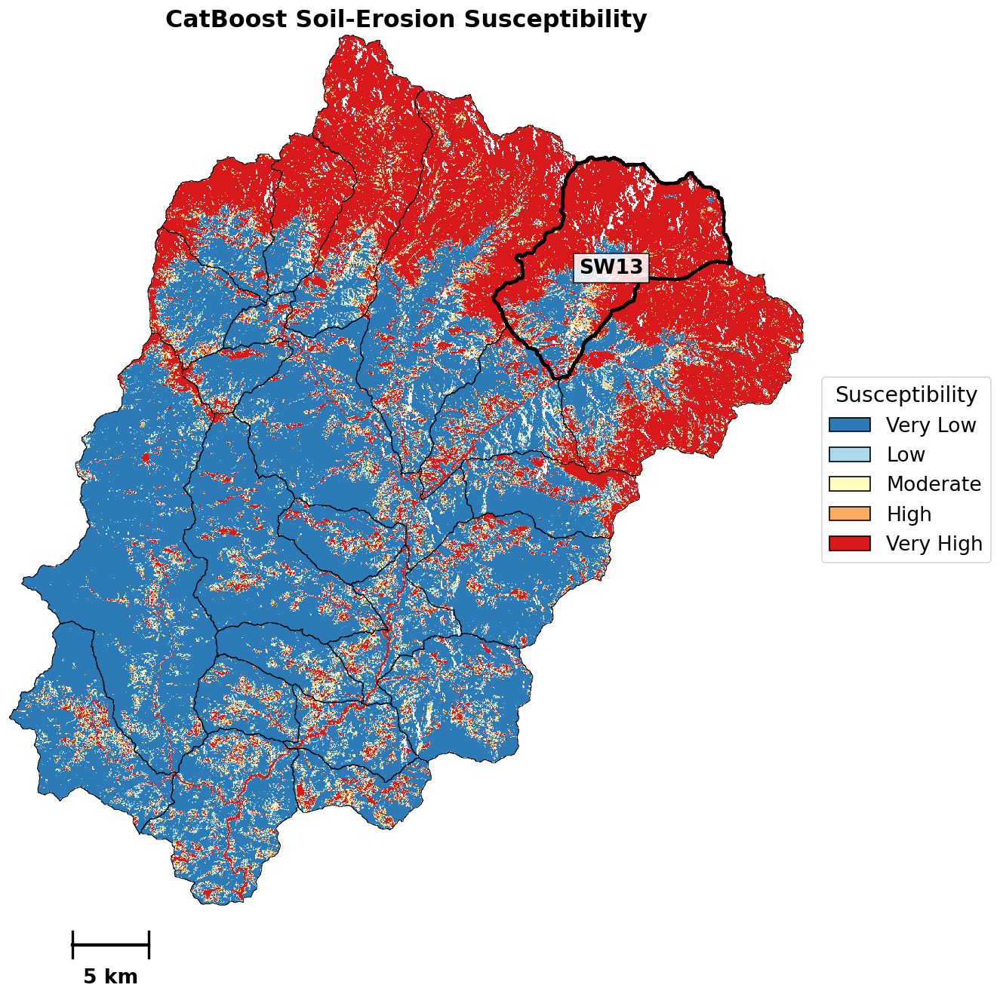

[DONE] FINAL SELECTED-MODEL SUSCEPTIBILITY MAP | elapsed 0.36 min


In [32]:
stage('FINAL SELECTED-MODEL SUSCEPTIBILITY MAP'); _t0=time.time()
sw_map=ensure_swid_column(gpd.read_file(sw_shp).to_crs(CRS))
with rasterio.open(FULL_RASTERS[SELECTED_MODEL]['S']) as src: sarr=src.read(1)
with rasterio.open(CLASS_RASTERS[SELECTED_MODEL]) as src: carr=src.read(1)
# Area-representative zonal mean S from full raster, not stratified points.
def zonal_values_for_sw(array,nodata_value,stat='mean'):
    rows=[]
    for _,r in sw_map.iterrows():
        m=geometry_mask([r.geometry],transform=GRID_TRANSFORM,invert=True,out_shape=(GRID_HEIGHT,GRID_WIDTH)); vals=array[m]
        vals=vals[(vals!=nodata_value)&np.isfinite(vals)] if np.issubdtype(vals.dtype,np.floating) else vals[vals!=nodata_value]
        value=float(np.mean(vals)) if len(vals) else np.nan; rows.append({'SWID':r.SWID,'Value':value})
    return pd.DataFrame(rows)
smean=zonal_values_for_sw(sarr,NODATA_FLOAT); highest_sw=str(smean.loc[smean.Value.idxmax(),'SWID']); print('Highest mean susceptibility SW:',highest_sw)
colors=ListedColormap(SUSCEPTIBILITY_COLORS); norm=BoundaryNorm(np.arange(.5,6.5,1),colors.N); display_arr=np.ma.masked_where(carr==0,carr)
fig,ax=plt.subplots(figsize=(12.5,12.5)); ax.imshow(display_arr,extent=[minx,maxx,miny,maxy],origin='upper',cmap=colors,norm=norm,interpolation='nearest')
sw_map.boundary.plot(ax=ax,color='black',linewidth=.55,zorder=5); sw_map[sw_map.SWID==highest_sw].boundary.plot(ax=ax,color='black',linewidth=2.6,zorder=7)
cent=sw_map[sw_map.SWID==highest_sw].geometry.iloc[0].representative_point(); ax.text(cent.x,cent.y,highest_sw,fontsize=FONT_LEGEND,fontweight='bold',ha='center',va='center',bbox={'facecolor':'white','alpha':.85,'edgecolor':'black'},zorder=8)
handles=[mpatches.Patch(facecolor=c,edgecolor='black',label=l) for c,l in zip(SUSCEPTIBILITY_COLORS,SUSCEPTIBILITY_LABELS)]; ax.legend(handles=handles,title='Susceptibility',loc='center left',bbox_to_anchor=(1.01,.5),frameon=True)
ax.set_title(f'{model_label(SELECTED_MODEL)} Soil-Erosion Susceptibility',fontweight='bold'); ax.set_axis_off(); add_scale_bar_below(ax,maxx-minx,SCALE_BAR_M)
FIG_SELECTED_SUS=save_figure(fig,DIRS['figures']/f'Figure_Final_{SELECTED_MODEL}_Susceptibility_SW_Boundaries.png'); plt.show(); plt.close(fig)
smean.rename(columns={'Value':'Mean_Susceptibility'}).sort_values('Mean_Susceptibility',ascending=False).to_csv(DIRS['tables']/f'{SELECTED_MODEL}_SW_Mean_Susceptibility.csv',index=False)
finish('FINAL SELECTED-MODEL SUSCEPTIBILITY MAP',_t0)


## 27. Area-percentage tables and the two retained area-percentage figures



AREA-PERCENTAGE TABLES + TWO FIGURES
Started: 2026-09-30 14:11:16


**Overall basin susceptibility class area percentages**

,Family,Class_ID,Class,Pixel_Count,Area_km2,Area_Percent
0,CatBoost,1,Very Low,989490,890.5410,55.5322
1,CatBoost,2,Low,72661,65.3949,4.0779
2,CatBoost,3,Moderate,129563,116.6067,7.2713
3,CatBoost,4,High,59706,53.7354,3.3508
4,CatBoost,5,Very High,530411,477.3699,29.7678
5,ExtraTrees,1,Very Low,954050,858.6450,53.5432
6,ExtraTrees,2,Low,100236,90.2124,5.6254
7,ExtraTrees,3,Moderate,137096,123.3864,7.6941
8,ExtraTrees,4,High,79220,71.2980,4.4460
9,ExtraTrees,5,Very High,511229,460.1061,28.6912


**23 SW susceptibility class area percentages**

,Family,SWID,Class_ID,Class,Pixel_Count,Area_km2,Area_Percent
0,CatBoost,SW23,1,Very Low,56018,50.4162,67.1679
1,CatBoost,SW23,2,Low,6894,6.2046,8.2662
2,CatBoost,SW23,3,Moderate,9419,8.4771,11.2938
3,CatBoost,SW23,4,High,3256,2.9304,3.9041
4,CatBoost,SW23,5,Very High,7813,7.0317,9.3681
5,CatBoost,SW22,1,Very Low,23869,21.4821,62.7438
6,CatBoost,SW22,2,Low,3147,2.8323,8.2724
7,CatBoost,SW22,3,Moderate,4609,4.1481,12.1156
8,CatBoost,SW22,4,High,1630,1.4670,4.2847
9,CatBoost,SW22,5,Very High,4787,4.3083,12.5835


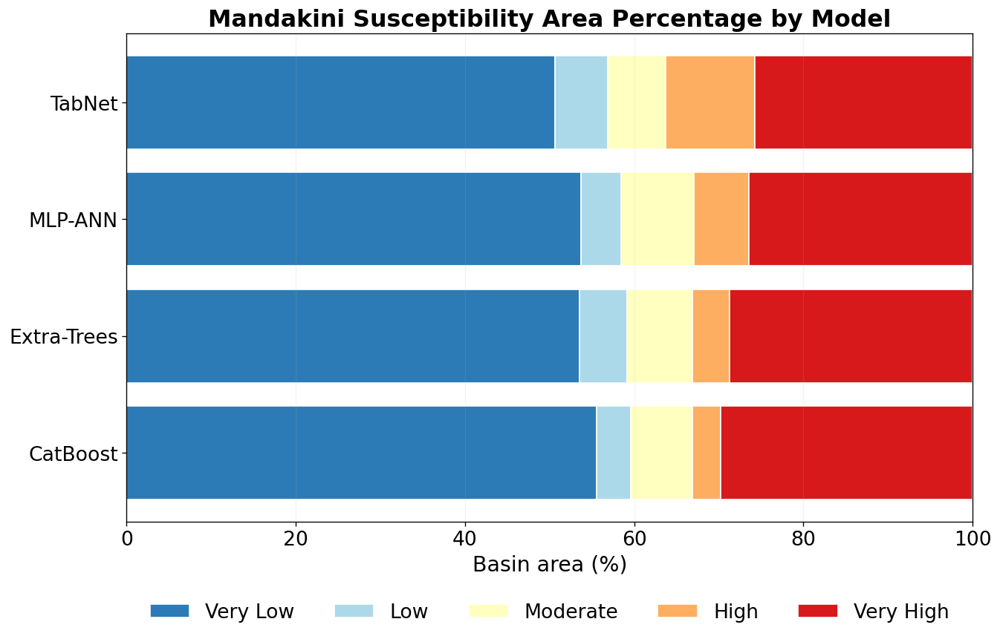

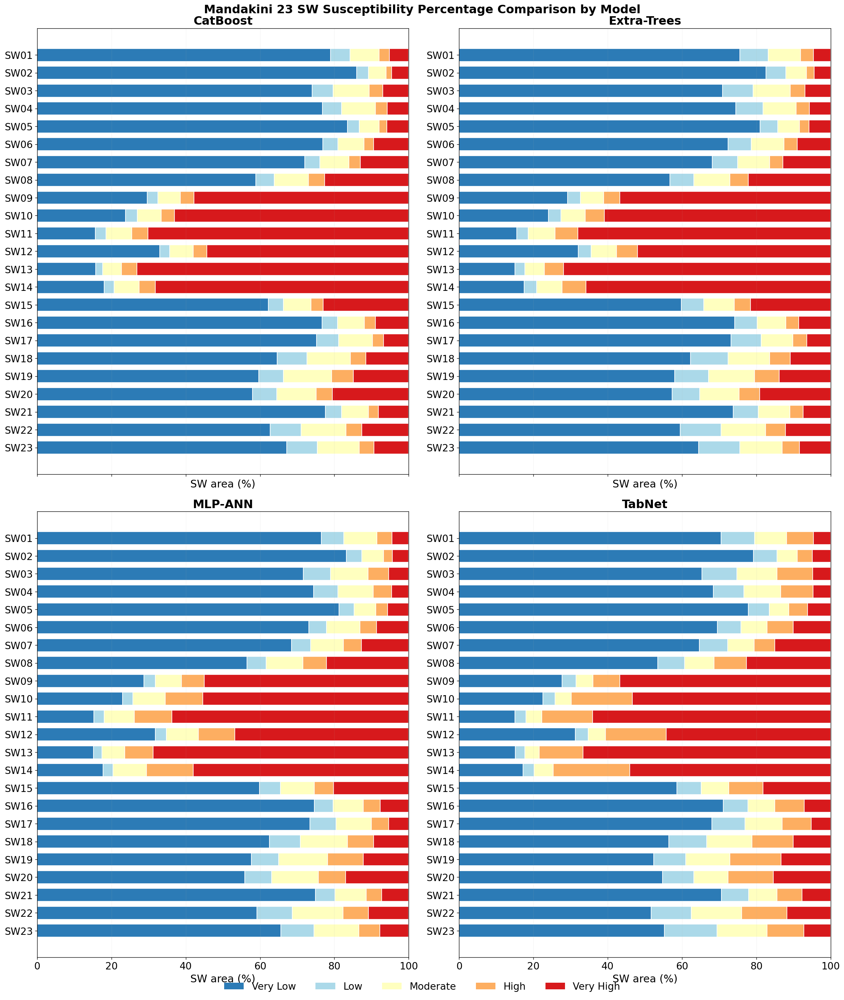

[DONE] AREA-PERCENTAGE TABLES + TWO FIGURES | elapsed 0.42 min


In [33]:
stage('AREA-PERCENTAGE TABLES + TWO FIGURES'); _t0=time.time(); pixel_km2=PIXEL_SIZE*PIXEL_SIZE/1e6; overall_rows=[]; sw_rows=[]
for family in MODEL_FAMILIES:
    with rasterio.open(CLASS_RASTERS[family]) as src: cl=src.read(1)
    valid=cl>0; total=int(valid.sum())
    for cid,label in enumerate(SUSCEPTIBILITY_LABELS,1):
        count=int((cl==cid).sum()); overall_rows.append({'Family':family,'Class_ID':cid,'Class':label,'Pixel_Count':count,'Area_km2':count*pixel_km2,'Area_Percent':100*count/total})
    for _,r in sw_map.iterrows():
        m=geometry_mask([r.geometry],transform=GRID_TRANSFORM,invert=True,out_shape=(GRID_HEIGHT,GRID_WIDTH)); vv=cl[m]; vv=vv[vv>0]; denom=max(len(vv),1)
        for cid,label in enumerate(SUSCEPTIBILITY_LABELS,1):
            count=int((vv==cid).sum()); sw_rows.append({'Family':family,'SWID':r.SWID,'Class_ID':cid,'Class':label,'Pixel_Count':count,'Area_km2':count*pixel_km2,'Area_Percent':100*count/denom})
OVERALL_AREA=pd.DataFrame(overall_rows); SW_AREA=pd.DataFrame(sw_rows); OVERALL_AREA.to_csv(DIRS['tables']/'Overall_Susceptibility_Class_Area_Percent_By_Model.csv',index=False); SW_AREA.to_csv(DIRS['tables']/'SW_Susceptibility_Class_Area_Percent_By_Model.csv',index=False)
show_table(OVERALL_AREA,'Overall basin susceptibility class area percentages'); show_table(SW_AREA,'23 SW susceptibility class area percentages',max_rows=500)
# Figure 1: overall model composition.
pivot=OVERALL_AREA.pivot(index='Family',columns='Class',values='Area_Percent').reindex(index=MODEL_FAMILIES,columns=SUSCEPTIBILITY_LABELS)
fig,ax=plt.subplots(figsize=(11.5,7.5)); left=np.zeros(len(pivot))
for label,color in zip(SUSCEPTIBILITY_LABELS,SUSCEPTIBILITY_COLORS): ax.barh(pivot.index,pivot[label],left=left,color=color,edgecolor='white',label=label); left+=pivot[label].to_numpy()
ax.set_yticklabels([model_label(x) for x in pivot.index]); ax.set_xlim(0,100); ax.set_xlabel('Basin area (%)'); ax.set_title('Mandakini Susceptibility Area Percentage by Model',fontweight='bold'); ax.legend(ncol=5,loc='upper center',bbox_to_anchor=(.5,-.13),frameon=False); ax.grid(axis='x',alpha=.15); fig.tight_layout(); save_figure(fig,DIRS['figures']/'Figure_Overall_Susceptibility_Area_Percent_By_Model.png'); plt.show(); plt.close(fig)
# Figure 2: 23 SW class composition for each model, four non-overlapping panels.
fig,axes=plt.subplots(2,2,figsize=(19,22),constrained_layout=True,sharex=True)
order=[f'SW{i:02d}' for i in range(1,24)]
for ax,family in zip(axes.ravel(),MODEL_FAMILIES):
    p=SW_AREA[SW_AREA.Family==family].pivot(index='SWID',columns='Class',values='Area_Percent').reindex(index=order,columns=SUSCEPTIBILITY_LABELS).fillna(0); left=np.zeros(len(p))
    for label,color in zip(SUSCEPTIBILITY_LABELS,SUSCEPTIBILITY_COLORS): ax.barh(p.index,p[label],left=left,color=color,edgecolor='white',height=.72,label=label); left+=p[label].to_numpy()
    ax.set_title(model_label(family),fontweight='bold'); ax.set_xlim(0,100); ax.set_xlabel('SW area (%)'); ax.invert_yaxis(); ax.grid(axis='x',alpha=.12)
handles=[mpatches.Patch(facecolor=c,label=l) for c,l in zip(SUSCEPTIBILITY_COLORS,SUSCEPTIBILITY_LABELS)]; fig.legend(handles=handles,ncol=5,loc='lower center',bbox_to_anchor=(.5,-.015),frameon=False); fig.suptitle('Mandakini 23 SW Susceptibility Percentage Comparison by Model',fontweight='bold',y=1.01)
save_figure(fig,DIRS['figures']/'Figure_23SW_Susceptibility_Area_Percent_By_Model.png'); plt.show(); plt.close(fig)
finish('AREA-PERCENTAGE TABLES + TWO FIGURES',_t0)


## 28. Continuous RUSLE verification for SWPI


In [34]:
stage('CONTINUOUS RUSLE VERIFICATION FOR SWPI'); _t0=time.time()

# The same current continuous RUSLE source used to rebuild the targets is reused for SWPI.
if RUSLE_CONTINUOUS_PATH is None or not Path(RUSLE_CONTINUOUS_PATH).exists():
    raise FileNotFoundError('Continuous RUSLE source is unavailable.')
if not RUSLE_ALIGNED_PATH.exists():
    raise FileNotFoundError('Aligned continuous RUSLE surface is unavailable.')

with rasterio.open(RUSLE_ALIGNED_PATH) as src:
    a=src.read(1)
    nd=src.nodata
valid=np.isfinite(a)
if nd is not None:
    valid &= ~np.isclose(a,nd)
valid &= BASIN_MASK
vals=a[valid]

if len(vals)==0 or len(np.unique(vals[:min(len(vals),200000)]))<=50:
    raise RuntimeError('Aligned RUSLE surface is not a valid continuous numerical surface.')

RUSLE_AUDIT=pd.DataFrame([{
    'Source_File':Path(RUSLE_CONTINUOUS_PATH).name,
    'Aligned_File':RUSLE_ALIGNED_PATH.name,
    'Valid_Basin_Pixels':int(valid.sum()),
    'Min':float(np.nanmin(vals)),
    'Mean':float(np.nanmean(vals)),
    'Median':float(np.nanmedian(vals)),
    'Max':float(np.nanmax(vals)),
    'CRS':CRS,
    'Resolution_m':PIXEL_SIZE,
}])
RUSLE_AUDIT.to_csv(DIRS['tables']/'Continuous_RUSLE_SWPI_Audit.csv',index=False)
show_table(RUSLE_AUDIT,'Continuous RUSLE source used for SWPI')

SWPI_AVAILABLE=True
del a,valid,vals
cleanup()
finish('CONTINUOUS RUSLE VERIFICATION FOR SWPI',_t0)



CONTINUOUS RUSLE VERIFICATION FOR SWPI
Started: 2026-09-30 14:11:42


**Continuous RUSLE source used for SWPI**

,Source_File,Aligned_File,Valid_Basin_Pixels,Min,Mean,Median,Max,CRS,Resolution_m
0,Mandakini_REU_RUSLE_Continuous_30m.tif,RUSLE_A_Continuous_30m.tif,1824923,0.0000,155.9492,21.5608,3159.4556,EPSG:32644,30.0000


[DONE] CONTINUOUS RUSLE VERIFICATION FOR SWPI | elapsed 0.02 min


## 29. Model-specific SWPI, consensus ranking, reliability columns, and consensus SWPI map



SWPI + CONSENSUS PRIORITIZATION
Started: 2026-09-30 16:43:39


**Model-specific SWPI for all 23 SWs**

,Family,SWID,SW_Name,Mean_S,Mean_P_H,HVH_Percent,Mean_RUSLE,N_S,N_P_H,N_HVH,N_RUSLE,SWPI,Model_Rank
0,CatBoost,SW23,Lower Mandakini,0.2034,0.1172,13.2722,50.2195,0.1620,0.0897,0.1008,0.0622,0.1167,14
1,CatBoost,SW22,Mid Mandakini,0.2422,0.1517,16.8682,68.3153,0.2174,0.1393,0.1513,0.0997,0.1670,11
2,CatBoost,SW21,Upper Mandakini,0.1501,0.0973,10.8218,39.3066,0.0859,0.0610,0.0664,0.0395,0.0688,17
3,CatBoost,SW20,Madhyamaheswar Ganga,0.3087,0.2290,24.9073,73.6462,0.3122,0.2503,0.2641,0.1108,0.2569,9
4,CatBoost,SW19,Sur Gad,0.2747,0.1815,20.6930,40.9882,0.2636,0.1821,0.2050,0.0430,0.1984,10
5,CatBoost,SW18,Sauri Gad,0.2274,0.1400,15.6997,53.5419,0.1962,0.1224,0.1349,0.0691,0.1464,12
6,CatBoost,SW17,Kyunja Gad,0.1522,0.0861,9.7843,24.6711,0.0889,0.0449,0.0518,0.0092,0.0585,19
7,CatBoost,SW16,Kakra Gad,0.1593,0.1063,11.8741,27.8225,0.0990,0.0739,0.0811,0.0157,0.0767,16
8,CatBoost,SW15,Kyar Gad,0.3023,0.2476,26.2561,79.8831,0.3031,0.2771,0.2831,0.1237,0.2657,8
9,CatBoost,SW14,Bantoli Gad,0.7524,0.7013,72.5879,290.0741,0.9453,0.9293,0.9336,0.5599,0.8812,3


**Consensus SWPI rank with reliability kept separate**

,SWID,SW_Name,CatBoost,ExtraTrees,MLP_ANN,TabNet,Mean_Model_Rank,Mean_SWPI,Consensus_Rank,Ordinary_Singleton_Rate,Ordinary_Mean_Set_Size,GeoCP_Singleton_Rate,GeoCP_Mean_Set_Size
0,SW13,Markanda Ganga,1,1,1,1,1.0000,1.0000,1,98.1111,0.9811,97.5556,1.0089
1,SW11,Mandakini River,2,2,2,2,2.0000,0.9620,2,96.6667,0.9667,94.8889,0.9489
2,SW14,Bantoli Gad,3,3,3,3,3.0000,0.8682,3,96.5556,0.9678,96.8889,1.0156
3,SW10,Vasuki Ganga,4,4,4,4,4.0000,0.7990,4,97.4444,0.9744,97.3333,0.9733
4,SW09,Sina Gad,5,5,5,5,5.0000,0.7426,5,97.1111,0.9756,96.6667,0.9667
5,SW12,Madhani River,6,6,6,6,6.0000,0.6956,6,96.4444,0.9644,97.0000,0.9767
6,SW08,Triyungi Narayan Gad,7,7,7,7,7.0000,0.2876,7,97.5556,0.9778,94.3333,0.9433
7,SW15,Kyar Gad,8,8,8,9,8.2500,0.2561,8,98.1111,0.9811,98.1111,0.9811
8,SW20,Madhyamaheswar Ganga,9,9,9,8,8.7500,0.2491,9,98.5556,0.9922,97.8889,0.9833
9,SW19,Sur Gad,10,10,10,10,10.0000,0.2055,10,97.5556,0.9756,94.8889,0.9533


Highest consensus priority SW: SW13

Rasterizing consensus Mean SWPI...
Rasterizing consensus rank...
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/Consensus_Mean_SWPI_30m.tif
[SAVE] /content/drive/MyDrive/Mandakini_reu/03_Models/Consensus_Rank_30m.tif

Consensus TIFF audit
Mean SWPI range: 0.0005 to 1.0000
Consensus ranks present: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
[PASS] Consensus rank TIFF contains ranks 1-23.


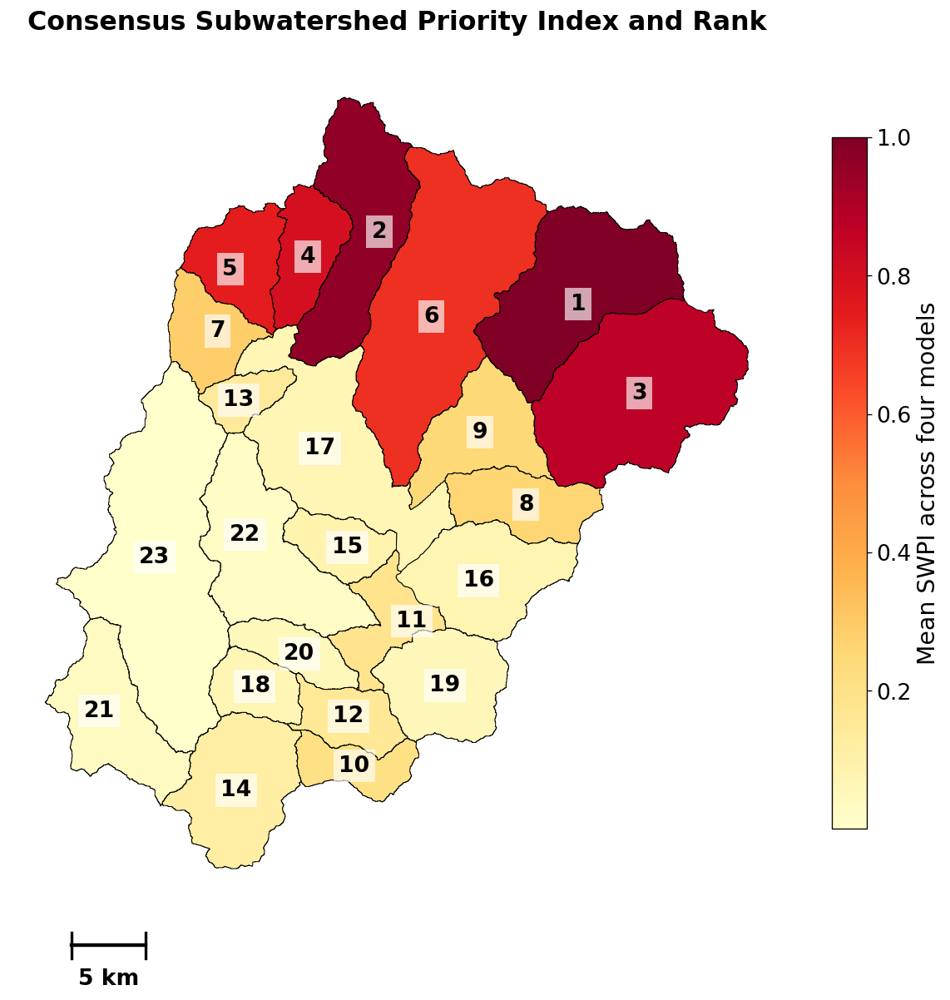

[SAVE] /content/drive/MyDrive/Mandakini_reu/07_Figures/Figure_Consensus_SWPI_Priority_Map.png
[DONE] SWPI + CONSENSUS PRIORITIZATION | elapsed 0.14 min


In [46]:
# =============================================================================
# SWPI + CONSENSUS PRIORITIZATION
# =============================================================================

stage('SWPI + CONSENSUS PRIORITIZATION')
_t0 = time.time()

from rasterio.features import geometry_mask, rasterize

CONSENSUS_SWPI_TABLE = None


# =============================================================================
# 1. SWPI AVAILABILITY CHECK
# =============================================================================

if not SWPI_AVAILABLE:

    print(
        '[DEFERRED] SWPI cannot be computed until a continuous '
        'area-representative RUSLE raster is available.'
    )


else:

    # =========================================================================
    # 2. READ AREA-REPRESENTATIVE CONTINUOUS RUSLE
    # =========================================================================

    with rasterio.open(
        RUSLE_ALIGNED_PATH
    ) as src:

        rusle_full = src.read(
            1
        )


    rows = []


    def minmax(v):

        v = np.asarray(
            v,
            float
        )

        lo = np.nanmin(
            v
        )

        hi = np.nanmax(
            v
        )

        return (
            np.zeros_like(
                v
            )
            if hi <= lo
            else
            (
                v - lo
            )
            /
            (
                hi - lo
            )
        )


    # =========================================================================
    # 3. MODEL-SPECIFIC SWPI
    # =========================================================================

    for family in MODEL_FAMILIES:

        with rasterio.open(
            FULL_RASTERS[
                family
            ][
                'S'
            ]
        ) as src:

            s = src.read(
                1
            )


        with rasterio.open(
            FULL_RASTERS[
                family
            ][
                'P2'
            ]
        ) as src:

            p2 = src.read(
                1
            )


        with rasterio.open(
            CLASS_RASTERS[
                family
            ]
        ) as src:

            cl = src.read(
                1
            )


        famrows = []


        for _, r in sw_map.iterrows():

            m = geometry_mask(
                [
                    r.geometry
                ],
                transform=GRID_TRANSFORM,
                invert=True,
                out_shape=(
                    GRID_HEIGHT,
                    GRID_WIDTH
                )
            )


            sv = s[
                m
            ]

            sv = sv[
                (
                    sv
                    !=
                    NODATA_FLOAT
                )
                &
                np.isfinite(
                    sv
                )
            ]


            pv = p2[
                m
            ]

            pv = pv[
                (
                    pv
                    !=
                    NODATA_FLOAT
                )
                &
                np.isfinite(
                    pv
                )
            ]


            cv = cl[
                m
            ]

            cv = cv[
                cv > 0
            ]


            rv = rusle_full[
                m
            ]

            rv = rv[
                (
                    rv
                    !=
                    NODATA_FLOAT
                )
                &
                np.isfinite(
                    rv
                )
            ]


            famrows.append(
                {
                    'Family':
                        family,

                    'SWID':
                        r.SWID,

                    'SW_Name':
                        SW_NAMES.get(
                            r.SWID,
                            r.SWID
                        ),

                    'Mean_S':
                        float(
                            sv.mean()
                        ),

                    'Mean_P_H':
                        float(
                            pv.mean()
                        ),

                    'HVH_Percent':
                        float(
                            100
                            *
                            np.isin(
                                cv,
                                [
                                    4,
                                    5
                                ]
                            ).mean()
                        ),

                    'Mean_RUSLE':
                        float(
                            rv.mean()
                        )
                }
            )


        f = pd.DataFrame(
            famrows
        )


        for src_col, n_col in [
            (
                'Mean_S',
                'N_S'
            ),
            (
                'Mean_P_H',
                'N_P_H'
            ),
            (
                'HVH_Percent',
                'N_HVH'
            ),
            (
                'Mean_RUSLE',
                'N_RUSLE'
            )
        ]:

            f[
                n_col
            ] = minmax(
                f[
                    src_col
                ]
            )


        f[
            'SWPI'
        ] = (
            0.40
            *
            f.N_S
            +
            0.25
            *
            f.N_P_H
            +
            0.20
            *
            f.N_HVH
            +
            0.15
            *
            f.N_RUSLE
        )


        f[
            'Model_Rank'
        ] = (
            f.SWPI
            .rank(
                ascending=False,
                method='min'
            )
            .astype(
                int
            )
        )


        rows.append(
            f
        )


    # =========================================================================
    # 4. SAVE MODEL-SPECIFIC SWPI
    # =========================================================================

    SWPI_LONG = pd.concat(
        rows,
        ignore_index=True
    )


    SWPI_LONG.to_csv(
        DIRS[
            'tables'
        ]
        /
        'Model_Specific_SWPI_23SW.csv',
        index=False
    )


    show_table(
        SWPI_LONG,
        'Model-specific SWPI for all 23 SWs',
        max_rows=200
    )


    # =========================================================================
    # 5. CONSENSUS RANK
    # =========================================================================

    wide_rank = (
        SWPI_LONG
        .pivot(
            index=[
                'SWID',
                'SW_Name'
            ],
            columns='Family',
            values='Model_Rank'
        )
        .reset_index()
    )


    wide_swpi = SWPI_LONG.pivot(
        index='SWID',
        columns='Family',
        values='SWPI'
    )


    wide_rank[
        'Mean_Model_Rank'
    ] = wide_rank[
        MODEL_FAMILIES
    ].mean(
        axis=1
    )


    wide_rank[
        'Mean_SWPI'
    ] = wide_rank.SWID.map(
        wide_swpi.mean(
            axis=1
        )
    )


    wide_rank = (
        wide_rank
        .sort_values(
            [
                'Mean_Model_Rank',
                'Mean_SWPI',
                'SWID'
            ],
            ascending=[
                True,
                False,
                True
            ]
        )
        .reset_index(
            drop=True
        )
    )


    wide_rank[
        'Consensus_Rank'
    ] = np.arange(
        1,
        len(
            wide_rank
        )
        +
        1
    )


    # =========================================================================
    # 6. KEEP GEOCP RELIABILITY SEPARATE
    # =========================================================================

    CONSENSUS_SWPI_TABLE = wide_rank.merge(
        SW_RELIABILITY,
        on='SWID',
        how='left'
    )


    CONSENSUS_SWPI_TABLE.to_csv(
        DIRS[
            'tables'
        ]
        /
        'Consensus_SWPI_Rank_and_GeoCP_Reliability.csv',
        index=False
    )


    show_table(
        CONSENSUS_SWPI_TABLE,
        'Consensus SWPI rank with reliability kept separate'
    )


    priority_sw = str(
        CONSENSUS_SWPI_TABLE.loc[
            CONSENSUS_SWPI_TABLE.Consensus_Rank.idxmin(),
            'SWID'
        ]
    )


    print(
        'Highest consensus priority SW:',
        priority_sw
    )


    # =========================================================================
    # 7. JOIN CONSENSUS RESULTS TO 23 SW POLYGONS
    # =========================================================================

    plot = sw_map.merge(
        CONSENSUS_SWPI_TABLE[
            [
                'SWID',
                'Mean_SWPI',
                'Consensus_Rank'
            ]
        ],
        on='SWID',
        how='left'
    )


    if plot[
        'Mean_SWPI'
    ].isna().any():

        raise RuntimeError(
            'One or more SWs are missing Mean_SWPI after the consensus merge.'
        )


    if plot[
        'Consensus_Rank'
    ].isna().any():

        raise RuntimeError(
            'One or more SWs are missing Consensus_Rank after the consensus merge.'
        )


    # =========================================================================
    # 8. GENERATE CONSENSUS GEOTIFFS
    # =========================================================================
    #
    # TIFF 1:
    # Continuous Mean SWPI across the four models.
    #
    # TIFF 2:
    # Consensus rank 1-23.
    #
    # =========================================================================

    consensus_swpi_tif = (
        DIRS[
            'models'
        ]
        /
        'Consensus_Mean_SWPI_30m.tif'
    )


    consensus_rank_tif = (
        DIRS[
            'models'
        ]
        /
        'Consensus_Rank_30m.tif'
    )


    swpi_shapes = [
        (
            geom,
            float(
                value
            )
        )
        for geom, value
        in zip(
            plot.geometry,
            plot[
                'Mean_SWPI'
            ]
        )
        if (
            geom is not None
            and
            not geom.is_empty
            and
            pd.notna(
                value
            )
        )
    ]


    rank_shapes = [
        (
            geom,
            int(
                value
            )
        )
        for geom, value
        in zip(
            plot.geometry,
            plot[
                'Consensus_Rank'
            ]
        )
        if (
            geom is not None
            and
            not geom.is_empty
            and
            pd.notna(
                value
            )
        )
    ]


    if len(
        swpi_shapes
    ) != 23:

        raise RuntimeError(
            f'Expected 23 SWPI polygon values for rasterization; '
            f'found {len(swpi_shapes)}.'
        )


    if len(
        rank_shapes
    ) != 23:

        raise RuntimeError(
            f'Expected 23 consensus-rank polygon values for rasterization; '
            f'found {len(rank_shapes)}.'
        )


    print(
        '\nRasterizing consensus Mean SWPI...'
    )


    consensus_swpi_arr = rasterize(
        shapes=swpi_shapes,
        out_shape=(
            GRID_HEIGHT,
            GRID_WIDTH
        ),
        transform=GRID_TRANSFORM,
        fill=NODATA_FLOAT,
        dtype='float32'
    )


    print(
        'Rasterizing consensus rank...'
    )


    consensus_rank_arr = rasterize(
        shapes=rank_shapes,
        out_shape=(
            GRID_HEIGHT,
            GRID_WIDTH
        ),
        transform=GRID_TRANSFORM,
        fill=0,
        dtype='int16'
    )


    # =========================================================================
    # 9. SAVE CONTINUOUS CONSENSUS SWPI TIFF
    # =========================================================================

    with rasterio.open(
        consensus_swpi_tif,
        'w',
        driver='GTiff',
        height=GRID_HEIGHT,
        width=GRID_WIDTH,
        count=1,
        dtype='float32',
        crs=CRS,
        transform=GRID_TRANSFORM,
        nodata=NODATA_FLOAT,
        compress='lzw'
    ) as dst:

        dst.write(
            consensus_swpi_arr.astype(
                'float32'
            ),
            1
        )


    print(
        '[SAVE]',
        consensus_swpi_tif
    )


    # =========================================================================
    # 10. SAVE CONSENSUS RANK TIFF
    # =========================================================================

    with rasterio.open(
        consensus_rank_tif,
        'w',
        driver='GTiff',
        height=GRID_HEIGHT,
        width=GRID_WIDTH,
        count=1,
        dtype='int16',
        crs=CRS,
        transform=GRID_TRANSFORM,
        nodata=0,
        compress='lzw'
    ) as dst:

        dst.write(
            consensus_rank_arr.astype(
                'int16'
            ),
            1
        )


    print(
        '[SAVE]',
        consensus_rank_tif
    )


    # =========================================================================
    # 11. TIFF AUDIT
    # =========================================================================

    valid_swpi = consensus_swpi_arr[
        consensus_swpi_arr
        !=
        NODATA_FLOAT
    ]


    valid_rank = consensus_rank_arr[
        consensus_rank_arr
        >
        0
    ]


    print(
        '\nConsensus TIFF audit'
    )


    print(
        'Mean SWPI range:',
        f'{float(valid_swpi.min()):.4f}',
        'to',
        f'{float(valid_swpi.max()):.4f}'
    )


    print(
        'Consensus ranks present:',
        sorted(
            np.unique(
                valid_rank
            ).astype(
                int
            ).tolist()
        )
    )


    expected_ranks = list(
        range(
            1,
            24
        )
    )


    actual_ranks = sorted(
        np.unique(
            valid_rank
        ).astype(
            int
        ).tolist()
    )


    if actual_ranks != expected_ranks:

        raise RuntimeError(
            'Consensus rank TIFF does not contain all ranks 1-23. '
            f'Found: {actual_ranks}'
        )


    print(
        '[PASS] Consensus rank TIFF contains ranks 1-23.'
    )


    # =========================================================================
    # 12. CONSENSUS FIGURE
    # =========================================================================
    #
    # IMPORTANT:
    # NO SPECIAL/BOLD BOUNDARY FOR RANK 1.
    # Every SW boundary uses the SAME linewidth.
    #
    # =========================================================================

    fig, ax = plt.subplots(
        figsize=(
            12.5,
            12.5
        )
    )


    plot.plot(
        column='Mean_SWPI',
        ax=ax,
        cmap='YlOrRd',
        edgecolor='black',
        linewidth=.6,
        legend=True,
        legend_kwds={
            'label':
                'Mean SWPI across four models',

            'shrink':
                .72
        }
    )


    for _, r in plot.iterrows():

        pt = r.geometry.representative_point()


        ax.text(
            pt.x,
            pt.y,
            str(
                int(
                    r.Consensus_Rank
                )
            ),
            ha='center',
            va='center',
            fontsize=16,
            fontweight='bold',
            bbox={
                'facecolor':
                    'white',

                'alpha':
                    .65,

                'edgecolor':
                    'none'
            }
        )


    ax.set_title(
        'Consensus Subwatershed Priority Index and Rank',
        fontweight='bold'
    )


    ax.set_axis_off()


    add_scale_bar_below(
        ax,
        maxx - minx,
        SCALE_BAR_M
    )


    consensus_fig = save_figure(
        fig,
        DIRS[
            'figures'
        ]
        /
        'Figure_Consensus_SWPI_Priority_Map.png'
    )


    plt.show()


    plt.close(
        fig
    )


    print(
        '[SAVE]',
        consensus_fig
    )


    # =========================================================================
    # 13. CLEAN MEMORY
    # =========================================================================

    del rusle_full
    del consensus_swpi_arr
    del consensus_rank_arr


finish(
    'SWPI + CONSENSUS PRIORITIZATION',
    _t0
)

cleanup()

## 30. Standard SHAP on the full locked TEST set for the selected calibrated susceptibility score



STANDARD SHAP: FULL LOCKED TEST
Started: 2026-09-30 14:11:50
[SAVE] SHAP_Training_Background_300.csv
Full locked TEST rows: 3151 | remaining: 3151 | background: 300 | max_evals: 21


Standard SHAP TEST batches:   0%|          | 0/32 [00:00<?, ?it/s]

SHAP reconstruction max abs error: 9.490053417410271e-08 | mean abs error: 2.8442239435374562e-08


**Global SHAP importance, full locked TEST**

,ECF,Mean_Absolute_SHAP
0,BSI,0.2821
1,MNDWI,0.1366
2,STI,0.1230
3,TRI,0.0271
4,LULC,0.0224
5,TWI,0.0196
6,Lithology,0.0150
7,S1-VV,0.0032
8,Dd,0.0030
9,LD,0.0026


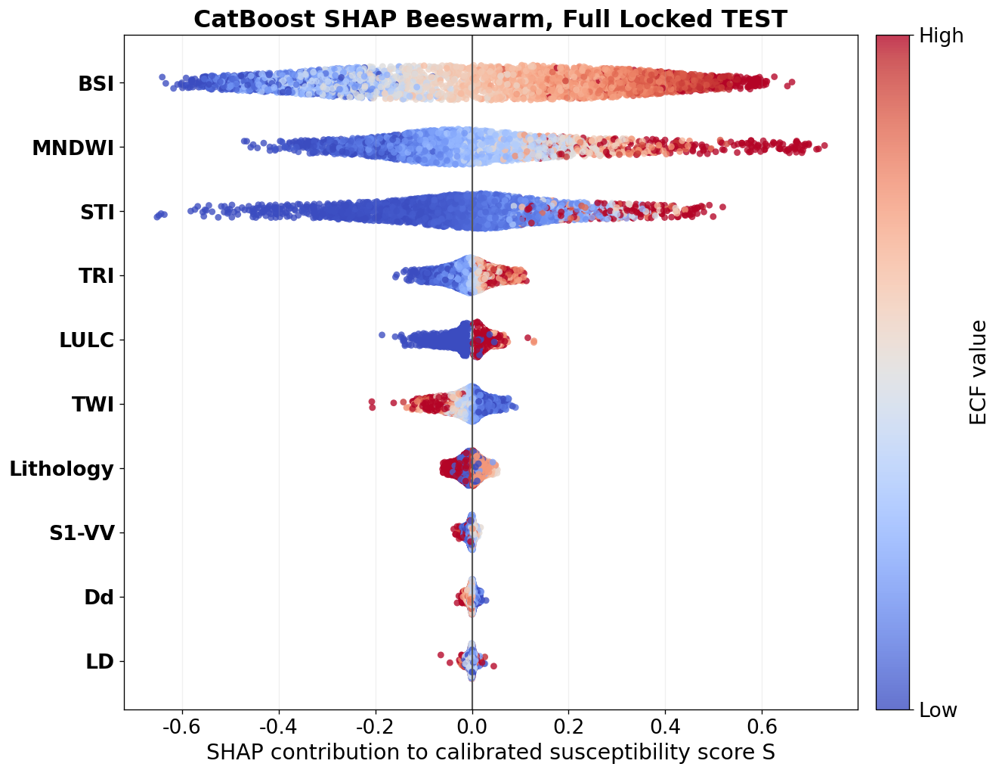

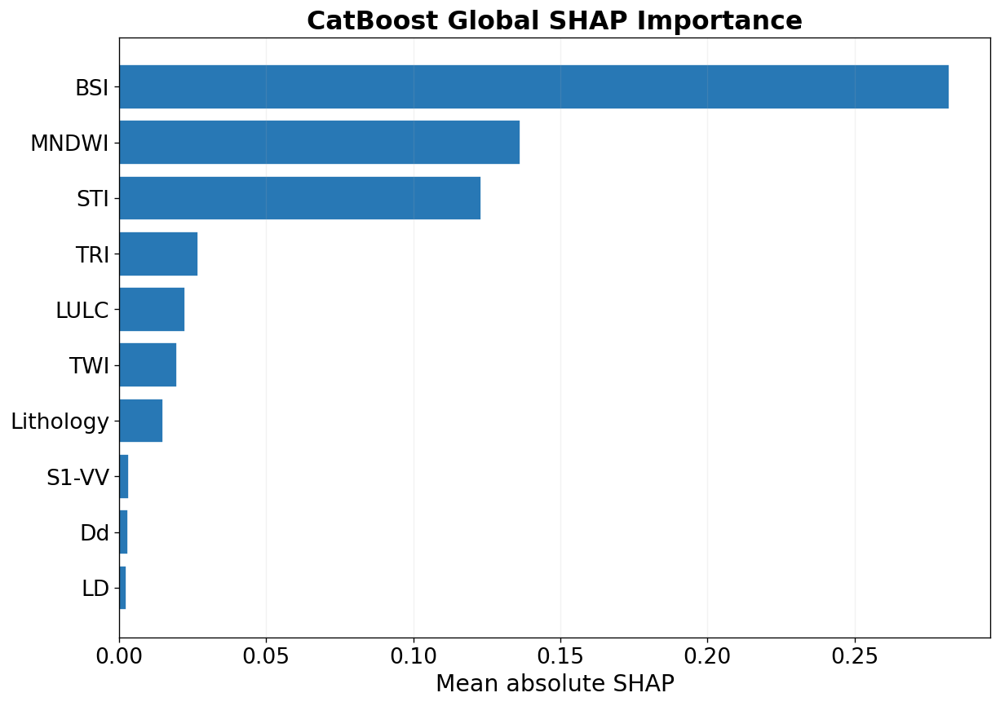

[DONE] STANDARD SHAP: FULL LOCKED TEST | elapsed 4.91 min


In [36]:
stage('STANDARD SHAP: FULL LOCKED TEST'); _t0=time.time()
# Explanation target is the selected model's final calibrated susceptibility score S.
train=data[data.Split=='TRAIN'].copy(); test=data[data.Split=='TEST'].copy(); selected_bundle=FINAL_BUNDLES[SELECTED_MODEL]; selected_calibrator=FINAL_CALIBRATORS[SELECTED_MODEL]

def calibrated_s_wrapper(Xraw):
    arr=np.asarray(Xraw)
    X=pd.DataFrame(arr,columns=ECFS)
    for c in CONTINUOUS_ECFS: X[c]=pd.to_numeric(X[c],errors='raise').astype(float)
    for c in CATEGORICAL_ECFS: X[c]=np.rint(pd.to_numeric(X[c],errors='raise')).astype(int)
    pu,_,_,_=selected_bundle.predict_uncalibrated(X); pc=selected_calibrator.transform(pu); return susceptibility_score(pc)

bg_path=DIRS['xai']/'SHAP_Training_Background_300.csv'
bg_meta=DIRS['xai']/'SHAP_Training_Background_300.meta.json'
bg_sig=hash_payload({
    'train_ids':train.Point_ID.tolist(),
    'train_targets':train.Target.tolist(),
    'sample_size':SHAP_BACKGROUND_SIZE,
    'seed':SEED,
    'ecfs':ECFS,
})
if valid_checkpoint(bg_meta,bg_sig) and bg_path.exists():
    SHAP_BACKGROUND=pd.read_csv(bg_path)
    print('[RESTORE validated]',bg_path.name)
else:
    sss=StratifiedShuffleSplit(
        n_splits=1,
        train_size=min(SHAP_BACKGROUND_SIZE,len(train)),
        random_state=SEED
    )
    bg_idx,_=next(sss.split(train,train.Target))
    SHAP_BACKGROUND=train.iloc[bg_idx][['Point_ID','Target']+ECFS].copy()
    SHAP_BACKGROUND.to_csv(bg_path,index=False)
    save_json(bg_meta,{
        'status':'COMPLETE',
        'signature':bg_sig,
        'rows':len(SHAP_BACKGROUND),
    })
    print('[SAVE]',bg_path.name)

Xbg=SHAP_BACKGROUND[ECFS].to_numpy(float)
Xtest=test[ECFS].to_numpy(float)
shap_sig=hash_payload({
    'selected_model':SELECTED_MODEL,
    'test_ids':test.Point_ID.tolist(),
    'background_ids':SHAP_BACKGROUND.Point_ID.tolist(),
    'ecfs':ECFS,
    'target':'calibrated S'
})
shap_npz=DIRS['xai']/'Standard_SHAP_Full_TEST_Checkpoint.npz'; shap_meta=DIRS['xai']/'Standard_SHAP_Full_TEST_Metadata.json'
SHAP_VALUES=np.full((len(test),len(ECFS)),np.nan,dtype=np.float32); SHAP_BASE=np.full(len(test),np.nan,dtype=np.float32); processed=np.zeros(len(test),bool)
if valid_checkpoint(shap_meta,shap_sig) and shap_npz.exists():
    ck=np.load(shap_npz); SHAP_VALUES[:]=ck['values']; SHAP_BASE[:]=ck['base']; processed[:]=ck['processed'].astype(bool); print('[RESTORE] standard SHAP',int(processed.sum()),'/',len(test))
masker=shap.maskers.Independent(Xbg,max_samples=len(Xbg)); explainer=shap.PermutationExplainer(calibrated_s_wrapper,masker,feature_names=ECFS,seed=SEED)
remaining=np.where(~processed)[0]; SHAP_BATCH=100
print('Full locked TEST rows:',len(test),'| remaining:',len(remaining),'| background:',len(Xbg),'| max_evals:',2*len(ECFS)+1)
for start in tqdm(range(0,len(remaining),SHAP_BATCH),desc='Standard SHAP TEST batches'):
    ids=remaining[start:start+SHAP_BATCH]; ex=explainer(Xtest[ids],max_evals=2*len(ECFS)+1,batch_size=128,silent=True)
    SHAP_VALUES[ids]=np.asarray(ex.values,dtype=np.float32); base=np.asarray(ex.base_values); SHAP_BASE[ids]=base.reshape(-1) if base.size>1 else float(base.reshape(-1)[0]); processed[ids]=True
    np.savez_compressed(shap_npz,values=SHAP_VALUES,base=SHAP_BASE,processed=processed.astype(np.uint8)); save_json(shap_meta,{'status':'COMPLETE' if processed.all() else 'RUNNING','signature':shap_sig,'processed':int(processed.sum()),'total':len(test)})
if not processed.all() or not np.isfinite(SHAP_VALUES).all(): raise RuntimeError('Standard SHAP did not complete cleanly')
_audit_n=min(100,len(test)); _direct=calibrated_s_wrapper(Xtest[:_audit_n]); _reconstructed=SHAP_BASE[:_audit_n]+SHAP_VALUES[:_audit_n].sum(axis=1); _err=np.abs(_direct-_reconstructed); print('SHAP reconstruction max abs error:',float(_err.max()),'| mean abs error:',float(_err.mean()))
if not np.isfinite(_err).all(): raise RuntimeError('SHAP reconstruction audit produced non-finite values')
pd.DataFrame({'Point_ID':test.Point_ID.iloc[:_audit_n].to_numpy(),'Direct_S':_direct,'SHAP_Reconstructed_S':_reconstructed,'Absolute_Error':_err}).to_csv(DIRS['tables']/'SHAP_Reconstruction_Audit.csv',index=False)
pd.DataFrame(SHAP_VALUES,columns=ECFS).assign(Point_ID=test.Point_ID.to_numpy()).to_csv(DIRS['xai']/'Standard_SHAP_Full_Locked_TEST.csv',index=False)
importance=pd.DataFrame({'ECF':[ecf_label(x) for x in ECFS],'Mean_Absolute_SHAP':np.mean(np.abs(SHAP_VALUES),axis=0)}).sort_values('Mean_Absolute_SHAP',ascending=False).reset_index(drop=True); importance.to_csv(DIRS['tables']/'Standard_SHAP_Global_Importance.csv',index=False); show_table(importance,'Global SHAP importance, full locked TEST')
# FOS-study visual language: coolwarm low-to-high values and a neutral zero reference.
order=np.argsort(np.mean(np.abs(SHAP_VALUES),axis=0))[::-1]; fig,ax=plt.subplots(figsize=(11.5,8.8)); rng=np.random.default_rng(SEED); last_sc=None
for rowpos,j in enumerate(order):
    sv=SHAP_VALUES[:,j]; fv=Xtest[:,j]; ranks=stats.rankdata(sv,method='average')/len(sv); jitter=(rng.random(len(sv))-.5)*.55*(.35+.65*np.sin(np.pi*ranks)); lo,hi=np.quantile(fv,[.05,.95]); normv=np.clip((fv-lo)/max(hi-lo,1e-12),0,1)
    last_sc=ax.scatter(sv,np.full(len(sv),rowpos)+jitter,c=normv,cmap='coolwarm',vmin=0,vmax=1,s=28,alpha=.78,edgecolor='none')
ax.axvline(0,color='#555555',lw=1.3); ax.set_yticks(np.arange(len(order))); ax.set_yticklabels([ecf_label(ECFS[j]) for j in order],fontweight='bold'); ax.invert_yaxis(); ax.set_xlabel('SHAP contribution to calibrated susceptibility score S'); ax.set_title(f'{model_label(SELECTED_MODEL)} SHAP Beeswarm, Full Locked TEST',fontweight='bold'); ax.grid(axis='x',alpha=.18)
cb=fig.colorbar(last_sc,ax=ax,pad=.02); cb.set_ticks([0,1]); cb.set_ticklabels(['Low','High']); cb.set_label('ECF value'); fig.tight_layout(); save_figure(fig,DIRS['figures']/f'Figure_{SELECTED_MODEL}_SHAP_Beeswarm_Full_TEST.png'); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(10.5,7.5)); imp=importance.sort_values('Mean_Absolute_SHAP'); ax.barh(imp.ECF,imp.Mean_Absolute_SHAP,color='#2878B5',edgecolor='white'); ax.set_xlabel('Mean absolute SHAP'); ax.set_title(f'{model_label(SELECTED_MODEL)} Global SHAP Importance',fontweight='bold'); ax.grid(axis='x',alpha=.16); fig.tight_layout(); save_figure(fig,DIRS['figures']/f'Figure_{SELECTED_MODEL}_SHAP_Global_Importance.png'); plt.show(); plt.close(fig)
finish('STANDARD SHAP: FULL LOCKED TEST',_t0); cleanup()


## 31. SHAP-IQ FSII through third order on a frozen 1,000-point TEST subset


In [37]:
stage('SHAP-IQ FSII ORDER 1-3'); _t0=time.time()
# The exact prior Mandakini mechanics are retained: FSII, order 3, 1,000 TEST, 300 TRAIN background, imputer 32, budget 256, checkpoints every 25.
fs_sample_path=DIRS['xai']/'SHAPIQ_1000_Stratified_TEST_Points.csv'
fs_sample_meta=DIRS['xai']/'SHAPIQ_1000_Stratified_TEST_Points.meta.json'
fs_sample_sig=hash_payload({
    'test_ids':test.Point_ID.tolist(),
    'test_targets':test.Target.tolist(),
    'sample_size':SHAPIQ_SAMPLE_SIZE,
    'seed':SEED,
    'stratify':'Target',
})
if valid_checkpoint(fs_sample_meta,fs_sample_sig) and fs_sample_path.exists():
    FS_TEST=pd.read_csv(fs_sample_path)
    print('[RESTORE validated]',fs_sample_path.name)
else:
    sss=StratifiedShuffleSplit(
        n_splits=1,
        train_size=min(SHAPIQ_SAMPLE_SIZE,len(test)),
        random_state=SEED
    )
    ix,_=next(sss.split(test,test.Target))
    FS_TEST=test.iloc[ix][['Point_ID','SWID','Target']+ECFS].copy().reset_index(drop=True)
    FS_TEST.to_csv(fs_sample_path,index=False)
    save_json(fs_sample_meta,{
        'status':'COMPLETE',
        'signature':fs_sample_sig,
        'rows':len(FS_TEST),
    })
    print('[SAVE]',fs_sample_path.name)
FS_BG=SHAP_BACKGROUND.copy(); X_FS=FS_TEST[ECFS].to_numpy(float); X_BG=FS_BG[ECFS].to_numpy(float)
EFFECT_KEYS=[]
for order_n in range(1,SHAPIQ_MAX_ORDER+1): EFFECT_KEYS.extend(list(combinations(range(len(ECFS)),order_n)))
if len(EFFECT_KEYS)!=175: raise RuntimeError(f'Expected 175 order 1-3 effects, got {len(EFFECT_KEYS)}')
EFFECT_TO_COL={k:i for i,k in enumerate(EFFECT_KEYS)}; EFFECT_LABELS=[' × '.join(ecf_label(ECFS[i]) for i in k) for k in EFFECT_KEYS]
fs_explainer=shapiq.TabularExplainer(model=calibrated_s_wrapper,data=X_BG,index='FSII',max_order=SHAPIQ_MAX_ORDER,imputer='marginal',approximator='auto',random_state=SEED,verbose=False,sample_size=SHAPIQ_IMPUTER_SAMPLE_SIZE,categorical_features=CAT_INDICES_RAW,joint_marginal_distribution=True)
fs_sig=hash_payload({'model':SELECTED_MODEL,'test_ids':FS_TEST.Point_ID.tolist(),'background_ids':FS_BG.Point_ID.tolist(),'budget':SHAPIQ_BUDGET,'max_order':3,'ecfs':ECFS,'target':'calibrated S'})
fs_npz=DIRS['xai']/'SHAPIQ_FSII_Order3_Checkpoint.npz'; fs_meta=DIRS['xai']/'SHAPIQ_FSII_Order3_Metadata.json'; LOCAL_FSII=np.full((len(FS_TEST),175),np.nan,dtype=np.float32); FS_DONE=np.zeros(len(FS_TEST),bool)
if valid_checkpoint(fs_meta,fs_sig) and fs_npz.exists():
    ck=np.load(fs_npz); LOCAL_FSII[:]=ck['local_fsii']; FS_DONE[:]=ck['processed'].astype(bool); print('[RESTORE] FSII',int(FS_DONE.sum()),'/',len(FS_TEST))
remaining=np.where(~FS_DONE)[0]; print('Selected TEST rows:',len(FS_TEST),'| effects per row: 175 | budget:',SHAPIQ_BUDGET,'| remaining:',len(remaining))
for loop_no,pos in enumerate(tqdm(remaining,desc='FSII order 1-3'),start=1):
    result=fs_explainer.explain(X_FS[pos],budget=SHAPIQ_BUDGET,random_state=SEED+int(pos)); vals=result.dict_values
    if str(result.index).upper()!='FSII' or int(result.max_order)!=3: raise RuntimeError('SHAP-IQ returned unexpected index/order')
    for inter,col in EFFECT_TO_COL.items():
        if inter not in vals: raise KeyError(f'SHAP-IQ missing interaction {inter}')
        LOCAL_FSII[pos,col]=float(vals[inter])
    FS_DONE[pos]=True
    if loop_no%SHAPIQ_CHECKPOINT_EVERY==0 or loop_no==len(remaining):
        np.savez_compressed(fs_npz,local_fsii=LOCAL_FSII,processed=FS_DONE.astype(np.uint8)); save_json(fs_meta,{'status':'COMPLETE' if FS_DONE.all() else 'RUNNING','signature':fs_sig,'processed':int(FS_DONE.sum()),'total':len(FS_TEST)})
if not FS_DONE.all() or not np.isfinite(LOCAL_FSII).all(): raise RuntimeError('FSII matrix is incomplete or non-finite')
local_df=pd.DataFrame(LOCAL_FSII,columns=EFFECT_LABELS); local_df.insert(0,'Point_ID',FS_TEST.Point_ID.to_numpy()); local_df.to_csv(DIRS['xai']/'SHAPIQ_Local_FSII_1000x175.csv',index=False); np.save(DIRS['xai']/'SHAPIQ_Local_FSII_1000x175.npy',LOCAL_FSII)
rows=[]
for col,key in enumerate(EFFECT_KEYS):
    v=LOCAL_FSII[:,col]; rows.append({'Interaction':EFFECT_LABELS[col],'Indices':'|'.join(map(str,key)),'Order':len(key),'Mean_Absolute_FSII':float(np.mean(np.abs(v))),'Mean_Signed_FSII':float(np.mean(v)),'Positive_Fraction':float(np.mean(v>0)),'Negative_Fraction':float(np.mean(v<0))})
FSII_EFFECTS=pd.DataFrame(rows).sort_values('Mean_Absolute_FSII',ascending=False).reset_index(drop=True); FSII_TOP15=FSII_EFFECTS.head(SHAPIQ_TOP_N).copy(); FSII_EFFECTS.to_csv(DIRS['xai']/'SHAPIQ_All_175_Effects.csv',index=False); FSII_TOP15.to_csv(DIRS['xai']/'SHAPIQ_Top15_Effects.csv',index=False); show_table(FSII_TOP15,'SHAP-IQ Top 15 first-, second-, and third-order effects')
finish('SHAP-IQ FSII ORDER 1-3',_t0); cleanup()



SHAP-IQ FSII ORDER 1-3
Started: 2026-09-30 14:16:46
[SAVE] SHAPIQ_1000_Stratified_TEST_Points.csv
Selected TEST rows: 1000 | effects per row: 175 | budget: 256 | remaining: 1000


FSII order 1-3:   0%|          | 0/1000 [00:00<?, ?it/s]

**SHAP-IQ Top 15 first-, second-, and third-order effects**

,Interaction,Indices,Order,Mean_Absolute_FSII,Mean_Signed_FSII,Positive_Fraction,Negative_Fraction
0,BSI,6,1,0.2808,-0.0192,0.5110,0.4890
1,MNDWI,7,1,0.1499,-0.0433,0.3410,0.6590
2,STI,5,1,0.1227,-0.0160,0.4990,0.5010
3,BSI × MNDWI,6|7,2,0.1063,0.0602,0.7160,0.2840
4,STI × BSI × MNDWI,5|6|7,3,0.0823,-0.0014,0.4630,0.5370
5,STI × BSI,5|6,2,0.0796,0.0161,0.5480,0.4520
6,TWI,4,1,0.0472,-0.0110,0.4450,0.5550
7,TRI,3,1,0.0471,-0.0014,0.4980,0.5020
8,LULC,9,1,0.0431,-0.0013,0.4960,0.5040
9,STI × MNDWI,5|7,2,0.0389,0.0125,0.6480,0.3520


[DONE] SHAP-IQ FSII ORDER 1-3 | elapsed 7.88 min


## 32. Top-15 SHAP-IQ UpSet figure and model-driven order-specific follow-up plots



TOP-15 SHAP-IQ VISUALIZATION
Started: 2026-09-30 16:05:13


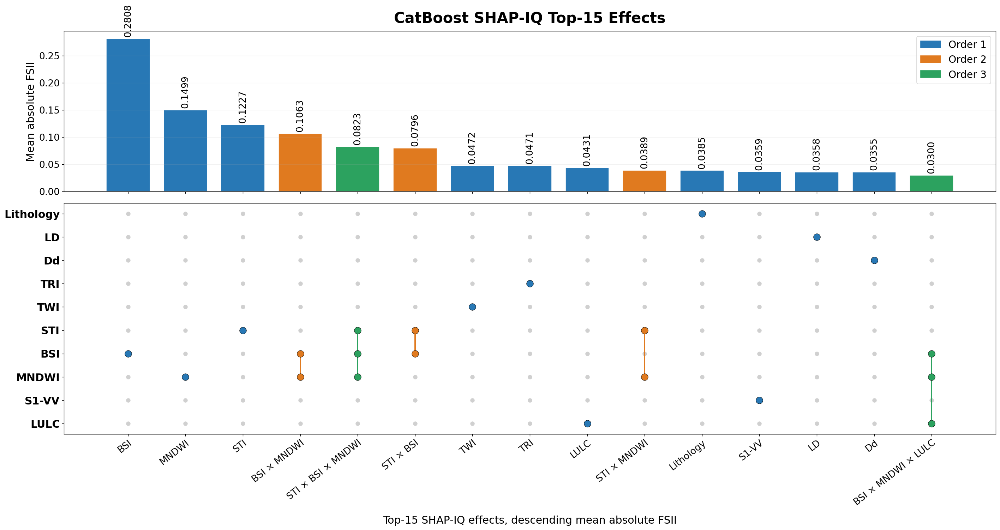

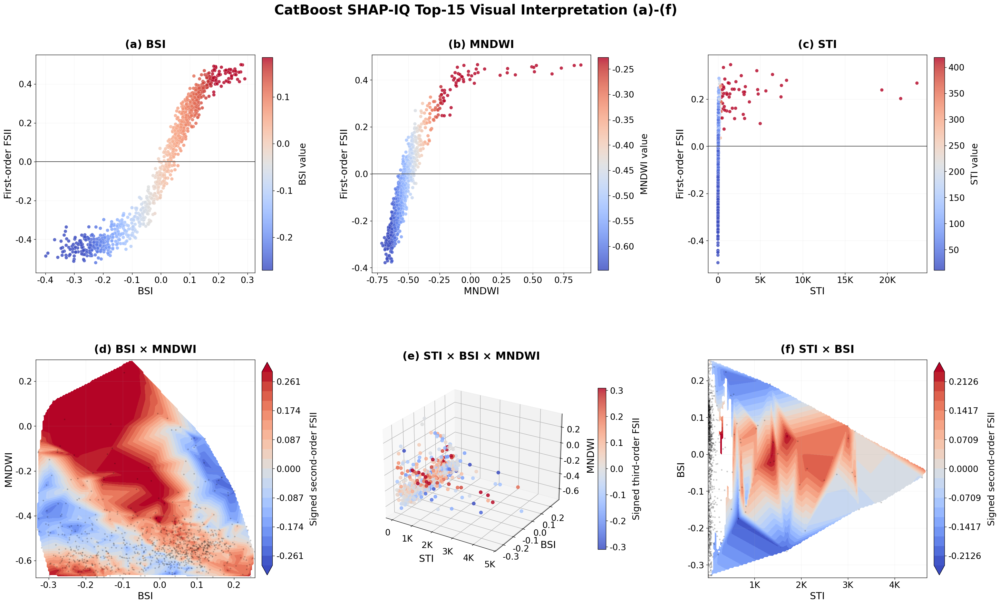

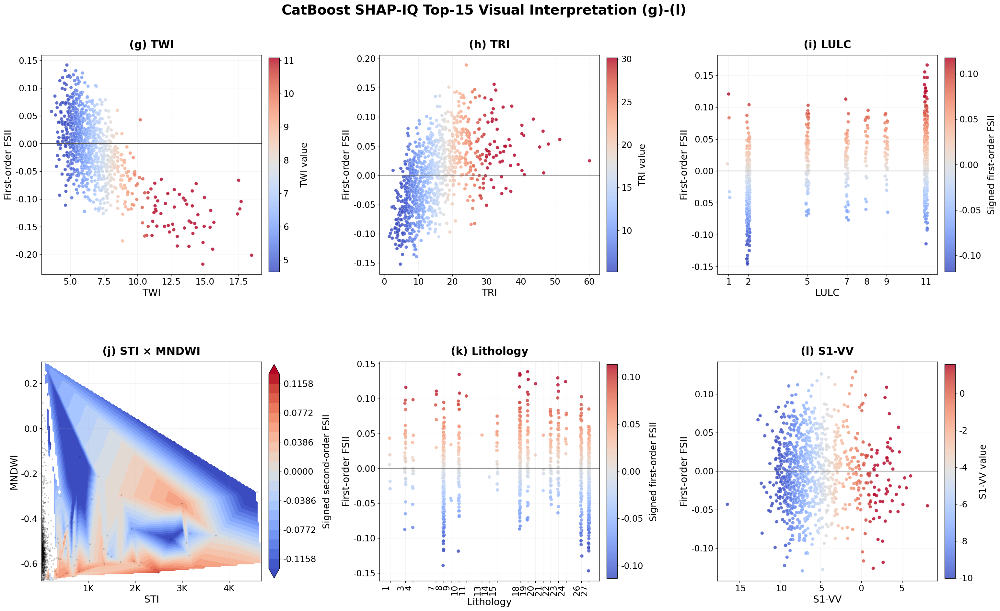

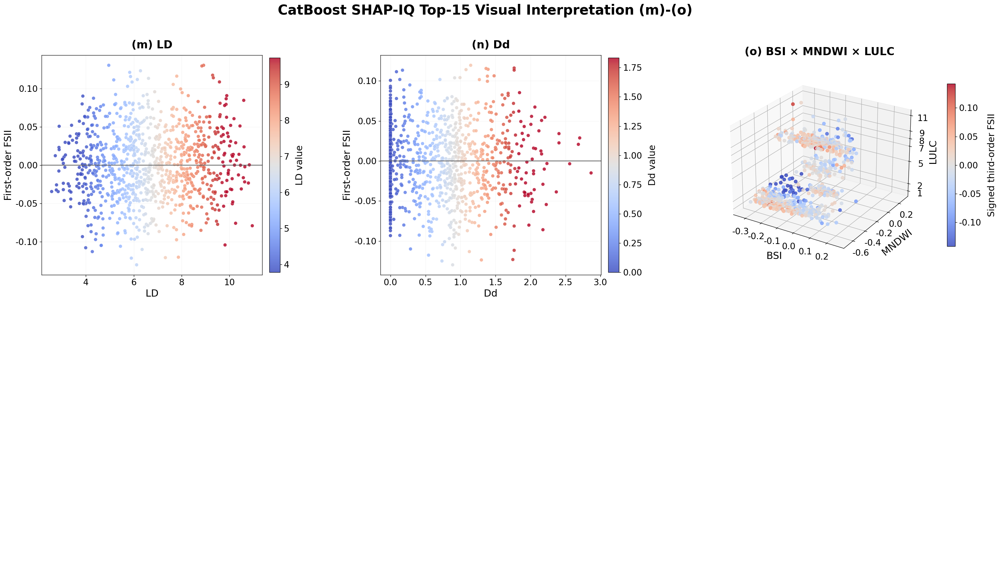

Saved UpSet figure: /content/drive/MyDrive/Mandakini_reu/07_Figures/Figure_CatBoost_SHAPIQ_Top15_UpSet.png
Saved three SHAP-IQ panel figures in: /content/drive/MyDrive/Mandakini_reu/07_Figures
Panel (o) LULC z-label gap: 0.075 inch (5.40 pt)
[DONE] TOP-15 SHAP-IQ VISUALIZATION | elapsed 1.96 min


In [44]:
stage('TOP-15 SHAP-IQ VISUALIZATION')
_t0 = time.time()

import math
import string
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.tri as mtri

from matplotlib.ticker import FuncFormatter
from matplotlib.colors import TwoSlopeNorm


# =============================================================================
# 1. PUBLICATION DISPLAY SETTINGS
# =============================================================================

FIG_TITLE_FS = 25
PANEL_TITLE_FS = 20
AXIS_LABEL_FS = 18
TICK_FS = 16
CBAR_LABEL_FS = 17
CBAR_TICK_FS = 16
UPSET_X_FS = 16
UPSET_Y_FS = 18
UPSET_VALUE_FS = 16
LEGEND_FS = 17

PLOTS_PER_FIGURE = 6
N_COLS = 3
N_ROWS = 2

# Used only for interpolation and 3-D visual display.
# FSII values themselves are NOT modified.
DISPLAY_Q_LOW = 0.01
DISPLAY_Q_HIGH = 0.99


# =============================================================================
# PANEL (o) ONLY:
# LULC z-axis label gap from numeric tick-label region
# =============================================================================
#
# Matplotlib labelpad is specified in points.
#
# 1 inch = 72 points
#
# Requested range:
# 0.05–0.10 inch
#
# Locked value:
# 0.075 inch = 5.4 points
#
# This setting affects ONLY panel (o).
# =============================================================================

LULC_Z_LABEL_GAP_IN = 0.075

LULC_Z_LABELPAD_PT = (
    LULC_Z_LABEL_GAP_IN
    *
    72.0
)


# =============================================================================
# 2. TOP-15 EFFECTS
# =============================================================================

top = (
    FSII_TOP15
    .sort_values(
        'Mean_Absolute_FSII',
        ascending=False
    )
    .reset_index(
        drop=True
    )
    .copy()
)


if len(top) != 15:

    raise RuntimeError(
        f'Expected exactly 15 SHAP-IQ effects; found {len(top)}.'
    )


panel_letters = list(
    string.ascii_lowercase[:15]
)


# =============================================================================
# 3. BASIC HELPERS
# =============================================================================

def effect_indices(row):

    return [
        int(v)
        for v
        in str(
            row.Indices
        ).split('|')
    ]


def effect_features(row):

    return [
        ECFS[i]
        for i
        in effect_indices(
            row
        )
    ]


def effect_name(row):

    return ' × '.join(
        ecf_label(
            feature
        )
        for feature
        in effect_features(
            row
        )
    )


def wrapped_effect_name(
    row,
    width=18
):

    return textwrap.fill(
        effect_name(
            row
        ),
        width=width,
        break_long_words=False
    )


# =============================================================================
# 4. STI THOUSANDS FORMATTER
# =============================================================================

def k_formatter(
    value,
    pos=None
):
    """
    1000  -> 1K
    5000  -> 5K
    10000 -> 10K
    12500 -> 12.5K
    """

    if not np.isfinite(
        value
    ):

        return ''


    absolute = abs(
        value
    )


    if absolute >= 1000:

        kval = (
            value
            /
            1000.0
        )


        if np.isclose(
            kval,
            round(
                kval
            ),
            atol=1e-9
        ):

            return (
                f'{int(round(kval))}K'
            )


        return (
            f'{kval:.1f}K'
        )


    if absolute >= 100:

        return (
            f'{value:.0f}'
        )


    if absolute >= 10:

        return (
            f'{value:.1f}'
            .rstrip('0')
            .rstrip('.')
        )


    return (
        f'{value:g}'
    )


K_FORMATTER = FuncFormatter(
    k_formatter
)


def apply_sti_formatter(
    ax,
    axis_name,
    feature
):

    if feature != 'STI':

        return


    if axis_name == 'x':

        ax.xaxis.set_major_formatter(
            K_FORMATTER
        )


    elif axis_name == 'y':

        ax.yaxis.set_major_formatter(
            K_FORMATTER
        )


    elif axis_name == 'z':

        ax.zaxis.set_major_formatter(
            K_FORMATTER
        )


# =============================================================================
# 5. CATEGORICAL CODE DISPLAY
# =============================================================================

def categorical_codes(
    values
):

    return sorted(
        int(v)
        for v
        in np.unique(
            np.rint(
                values
            ).astype(
                int
            )
        )
    )


def apply_category_codes(
    ax,
    axis_name,
    feature,
    values
):

    if feature not in CATEGORICAL_ECFS:

        return


    codes = categorical_codes(
        values
    )


    rotate_x = (
        90
        if len(codes) > 10
        else 0
    )


    if axis_name == 'x':

        ax.set_xticks(
            codes
        )


        ax.set_xticklabels(
            [
                str(v)
                for v
                in codes
            ],
            fontsize=TICK_FS,
            rotation=rotate_x,
            ha=(
                'center'
                if rotate_x == 0
                else
                'right'
            )
        )


    elif axis_name == 'y':

        ax.set_yticks(
            codes
        )


        ax.set_yticklabels(
            [
                str(v)
                for v
                in codes
            ],
            fontsize=TICK_FS
        )


    elif axis_name == 'z':

        ax.set_zticks(
            codes
        )


        ax.set_zticklabels(
            [
                str(v)
                for v
                in codes
            ],
            fontsize=TICK_FS
        )


# =============================================================================
# 6. ROBUST DISPLAY HELPERS
# =============================================================================

def robust_window(
    values,
    qlow=DISPLAY_Q_LOW,
    qhigh=DISPLAY_Q_HIGH
):

    values = np.asarray(
        values,
        dtype=float
    )


    finite = values[
        np.isfinite(
            values
        )
    ]


    if finite.size == 0:

        raise RuntimeError(
            'No finite values available for plotting.'
        )


    lo, hi = np.quantile(
        finite,
        [
            qlow,
            qhigh
        ]
    )


    if not (
        np.isfinite(
            lo
        )
        and
        np.isfinite(
            hi
        )
    ):

        raise RuntimeError(
            'Invalid plotting quantiles.'
        )


    if np.isclose(
        lo,
        hi
    ):

        lo = float(
            np.nanmin(
                finite
            )
        )

        hi = float(
            np.nanmax(
                finite
            )
        )


    return (
        float(
            lo
        ),
        float(
            hi
        )
    )


def signed_limits(
    values,
    percentile=98.0
):

    values = np.asarray(
        values,
        dtype=float
    )


    finite = values[
        np.isfinite(
            values
        )
    ]


    if finite.size == 0:

        return (
            -1.0,
            1.0
        )


    vmax = float(
        np.nanpercentile(
            np.abs(
                finite
            ),
            percentile
        )
    )


    if (
        not np.isfinite(
            vmax
        )
        or
        vmax <= 0
    ):

        vmax = float(
            np.nanmax(
                np.abs(
                    finite
                )
            )
        )


    if (
        not np.isfinite(
            vmax
        )
        or
        vmax <= 0
    ):

        vmax = 1e-9


    return (
        -vmax,
        vmax
    )


# =============================================================================
# 7. PANEL TITLE
# =============================================================================

def add_panel_title(
    ax,
    letter,
    text,
    is_3d=False
):

    title_text = (
        f'({letter}) {text}'
    )


    ax.set_title(
        title_text,
        fontsize=PANEL_TITLE_FS,
        fontweight='bold',
        pad=(
            18
            if is_3d
            else
            13
        )
    )


# =============================================================================
# 8. COMMON AXIS FORMATTING
# =============================================================================

def style_2d_axis(
    ax
):

    ax.tick_params(
        axis='both',
        labelsize=TICK_FS
    )


    ax.grid(
        alpha=.14,
        linewidth=.7
    )


def style_colorbar(
    cb,
    label
):

    cb.set_label(
        label,
        fontsize=CBAR_LABEL_FS,
        labelpad=11
    )


    cb.ax.tick_params(
        labelsize=CBAR_TICK_FS
    )


# =============================================================================
# 9. IMPROVED CONTINUOUS × CONTINUOUS INTERPOLATION
# =============================================================================

def make_interpolated_continuous_interaction(
    ax,
    xvals,
    yvals,
    fsii_vals,
    f1,
    f2
):

    xvals = np.asarray(
        xvals,
        dtype=float
    )


    yvals = np.asarray(
        yvals,
        dtype=float
    )


    zvals = np.asarray(
        fsii_vals,
        dtype=float
    )


    xlo, xhi = robust_window(
        xvals
    )


    ylo, yhi = robust_window(
        yvals
    )


    keep = (
        np.isfinite(
            xvals
        )
        &
        np.isfinite(
            yvals
        )
        &
        np.isfinite(
            zvals
        )
        &
        (
            xvals
            >=
            xlo
        )
        &
        (
            xvals
            <=
            xhi
        )
        &
        (
            yvals
            >=
            ylo
        )
        &
        (
            yvals
            <=
            yhi
        )
    )


    xw = xvals[
        keep
    ]


    yw = yvals[
        keep
    ]


    zw = zvals[
        keep
    ]


    if len(
        xw
    ) < 10:

        raise RuntimeError(
            f'Insufficient observations for '
            f'{ecf_label(f1)} × {ecf_label(f2)} interpolation.'
        )


    interpolation_df = pd.DataFrame(
        {
            'x':
                xw,

            'y':
                yw,

            'z':
                zw
        }
    )


    interpolation_df = (
        interpolation_df
        .groupby(
            [
                'x',
                'y'
            ],
            as_index=False
        )[
            'z'
        ]
        .mean()
    )


    xu = interpolation_df[
        'x'
    ].to_numpy(
        dtype=float
    )


    yu = interpolation_df[
        'y'
    ].to_numpy(
        dtype=float
    )


    zu = interpolation_df[
        'z'
    ].to_numpy(
        dtype=float
    )


    if len(
        xu
    ) < 3:

        raise RuntimeError(
            f'Not enough unique observations for '
            f'{ecf_label(f1)} × {ecf_label(f2)} interpolation.'
        )


    try:

        triangulation = mtri.Triangulation(
            xu,
            yu
        )


        analyzer = mtri.TriAnalyzer(
            triangulation
        )


        flat_mask = analyzer.get_flat_tri_mask(
            min_circle_ratio=.01
        )


        if (
            flat_mask is not None
            and
            len(flat_mask)
            ==
            len(
                triangulation.triangles
            )
        ):

            triangulation.set_mask(
                flat_mask
            )


        interpolator = mtri.LinearTriInterpolator(
            triangulation,
            zu
        )


        gx = np.linspace(
            xlo,
            xhi,
            160
        )


        gy = np.linspace(
            ylo,
            yhi,
            160
        )


        XG, YG = np.meshgrid(
            gx,
            gy
        )


        ZG = interpolator(
            XG,
            YG
        )


        vmin, vmax = signed_limits(
            zw,
            percentile=98.0
        )


        levels = np.linspace(
            vmin,
            vmax,
            21
        )


        contour = ax.contourf(
            XG,
            YG,
            ZG,
            levels=levels,
            cmap='coolwarm',
            extend='both'
        )


        ax.scatter(
            xw,
            yw,
            s=8,
            c='black',
            alpha=.22,
            linewidths=0,
            rasterized=True,
            zorder=5
        )


        ax.set_xlim(
            xlo,
            xhi
        )


        ax.set_ylim(
            ylo,
            yhi
        )


        apply_sti_formatter(
            ax,
            'x',
            f1
        )


        apply_sti_formatter(
            ax,
            'y',
            f2
        )


        return contour


    except Exception as exc:

        print(
            f'[WARN] Triangular interpolation failed for '
            f'{ecf_label(f1)} × {ecf_label(f2)}: {exc}'
        )


        print(
            '[WARN] Using signed-FSII scatter fallback.'
        )


        vmin, vmax = signed_limits(
            zw,
            percentile=98.0
        )


        scatter = ax.scatter(
            xw,
            yw,
            c=zw,
            cmap='coolwarm',
            vmin=vmin,
            vmax=vmax,
            s=34,
            alpha=.80,
            edgecolor='white',
            linewidth=.25,
            rasterized=True
        )


        ax.set_xlim(
            xlo,
            xhi
        )


        ax.set_ylim(
            ylo,
            yhi
        )


        apply_sti_formatter(
            ax,
            'x',
            f1
        )


        apply_sti_formatter(
            ax,
            'y',
            f2
        )


        return scatter


# =============================================================================
# 10. SHAP-IQ UPSET FIGURE
# =============================================================================

x = np.arange(
    len(
        top
    )
)


effect_labels = [
    wrapped_effect_name(
        row,
        width=18
    )
    for _, row
    in top.iterrows()
]


bar_colors = [
    FSII_ORDER_COLORS[
        int(
            order
        )
    ]
    for order
    in top.Order
]


fig = plt.figure(
    figsize=(
        25,
        14
    )
)


gs = fig.add_gridspec(
    2,
    1,
    height_ratios=[
        2.15,
        3.10
    ],
    hspace=.06
)


axb = fig.add_subplot(
    gs[
        0
    ]
)


axm = fig.add_subplot(
    gs[
        1
    ],
    sharex=axb
)


axb.bar(
    x,
    top.Mean_Absolute_FSII,
    color=bar_colors,
    edgecolor='white',
    linewidth=1.0,
    width=.76
)


bar_offset = (
    float(
        top.Mean_Absolute_FSII.max()
    )
    *
    .012
)


for i, value in enumerate(
    top.Mean_Absolute_FSII
):

    axb.text(
        i,
        value + bar_offset,
        f'{value:.4f}',
        ha='center',
        va='bottom',
        rotation=90,
        fontsize=UPSET_VALUE_FS
    )


axb.set_ylabel(
    'Mean absolute FSII',
    fontsize=AXIS_LABEL_FS
)


axb.set_title(
    f'{model_label(SELECTED_MODEL)} SHAP-IQ Top-15 Effects',
    fontsize=FIG_TITLE_FS,
    fontweight='bold',
    pad=14
)


axb.grid(
    axis='y',
    alpha=.16
)


axb.tick_params(
    axis='y',
    labelsize=TICK_FS
)


axb.tick_params(
    axis='x',
    labelbottom=False
)


upset_legend = [
    mpatches.Patch(
        color=FSII_ORDER_COLORS[
            order
        ],
        label=f'Order {order}'
    )
    for order
    in [
        1,
        2,
        3
    ]
]


axb.legend(
    handles=upset_legend,
    loc='upper right',
    frameon=True,
    fontsize=LEGEND_FS
)


for row_idx, feature in enumerate(
    ECFS
):

    axm.scatter(
        x,
        np.full(
            len(
                x
            ),
            row_idx
        ),
        s=42,
        color='#D0D0D0',
        zorder=1
    )


for col_idx, row in top.iterrows():

    inds = effect_indices(
        row
    )


    ys = []


    for idx in inds:

        axm.scatter(
            col_idx,
            idx,
            s=135,
            color=FSII_ORDER_COLORS[
                int(
                    row.Order
                )
            ],
            edgecolor='black',
            linewidth=.55,
            zorder=3
        )


        ys.append(
            idx
        )


    if len(
        ys
    ) > 1:

        axm.plot(
            [
                col_idx,
                col_idx
            ],
            [
                min(
                    ys
                ),
                max(
                    ys
                )
            ],
            color=FSII_ORDER_COLORS[
                int(
                    row.Order
                )
            ],
            lw=2.4,
            zorder=2
        )


axm.set_yticks(
    range(
        len(
            ECFS
        )
    )
)


axm.set_yticklabels(
    [
        ecf_label(
            feature
        )
        for feature
        in ECFS
    ],
    fontsize=UPSET_Y_FS,
    fontweight='bold'
)


axm.invert_yaxis()


axm.set_xticks(
    x
)


axm.set_xticklabels(
    effect_labels,
    rotation=38,
    ha='right',
    rotation_mode='anchor',
    fontsize=UPSET_X_FS
)


axm.set_xlabel(
    'Top-15 SHAP-IQ effects, descending mean absolute FSII',
    fontsize=AXIS_LABEL_FS,
    labelpad=14
)


axm.tick_params(
    axis='y',
    labelsize=UPSET_Y_FS
)


axm.grid(
    False
)


fig.subplots_adjust(
    left=.105,
    right=.985,
    top=.93,
    bottom=.25
)


upset_path = (
    DIRS[
        'figures'
    ]
    /
    f'Figure_{SELECTED_MODEL}_SHAPIQ_Top15_UpSet.png'
)


save_figure(
    fig,
    upset_path
)


plt.show()


plt.close(
    fig
)


cleanup()


# =============================================================================
# 11. THREE MULTIPANEL FIGURES
# =============================================================================

n_figs = math.ceil(
    len(
        top
    )
    /
    PLOTS_PER_FIGURE
)


for fig_no in range(
    n_figs
):

    start_idx = (
        fig_no
        *
        PLOTS_PER_FIGURE
    )


    end_idx = min(
        start_idx
        +
        PLOTS_PER_FIGURE,
        len(
            top
        )
    )


    fig = plt.figure(
        figsize=(
            25,
            16.5
        )
    )


    panel_grid = fig.add_gridspec(
        N_ROWS,
        N_COLS,
        left=.045,
        right=.985,
        bottom=.065,
        top=.885,
        wspace=.42,
        hspace=.40
    )


    for slot in range(
        PLOTS_PER_FIGURE
    ):

        global_idx = (
            start_idx
            +
            slot
        )


        grid_row = (
            slot
            //
            N_COLS
        )


        grid_col = (
            slot
            %
            N_COLS
        )


        if global_idx >= len(
            top
        ):

            ax_empty = fig.add_subplot(
                panel_grid[
                    grid_row,
                    grid_col
                ]
            )


            ax_empty.axis(
                'off'
            )


            continue


        row = top.iloc[
            global_idx
        ]


        inds = effect_indices(
            row
        )


        feats = effect_features(
            row
        )


        order_n = int(
            row.Order
        )


        effect_key = tuple(
            inds
        )


        if effect_key not in EFFECT_TO_COL:

            raise RuntimeError(
                f'Effect {effect_key} was not found in EFFECT_TO_COL.'
            )


        local = LOCAL_FSII[
            :,
            EFFECT_TO_COL[
                effect_key
            ]
        ]


        letter = panel_letters[
            global_idx
        ]


        # =====================================================================
        # ORDER 1
        # =====================================================================

        if order_n == 1:

            ax = fig.add_subplot(
                panel_grid[
                    grid_row,
                    grid_col
                ]
            )


            feature = feats[
                0
            ]


            vals = np.asarray(
                X_FS[
                    :,
                    inds[
                        0
                    ]
                ],
                dtype=float
            )


            if feature in CONTINUOUS_ECFS:

                finite_vals = vals[
                    np.isfinite(
                        vals
                    )
                ]


                lo, hi = np.quantile(
                    finite_vals,
                    [
                        .05,
                        .95
                    ]
                )


                sc = ax.scatter(
                    vals,
                    local,
                    c=vals,
                    cmap='coolwarm',
                    vmin=lo,
                    vmax=hi,
                    s=40,
                    alpha=.82,
                    edgecolor='white',
                    linewidth=.28,
                    rasterized=True
                )


                cb = fig.colorbar(
                    sc,
                    ax=ax,
                    pad=.030,
                    fraction=.045
                )


                style_colorbar(
                    cb,
                    f'{ecf_label(feature)} value'
                )


                if feature == 'STI':

                    cb.ax.yaxis.set_major_formatter(
                        K_FORMATTER
                    )


                apply_sti_formatter(
                    ax,
                    'x',
                    feature
                )


            else:

                rng = np.random.default_rng(
                    SEED
                    +
                    global_idx
                )


                jittered = (
                    vals
                    +
                    (
                        rng.random(
                            len(
                                vals
                            )
                        )
                        -
                        .5
                    )
                    *
                    .16
                )


                vmin, vmax = signed_limits(
                    local,
                    percentile=98.0
                )


                sc = ax.scatter(
                    jittered,
                    local,
                    c=local,
                    cmap='coolwarm',
                    vmin=vmin,
                    vmax=vmax,
                    s=40,
                    alpha=.82,
                    edgecolor='white',
                    linewidth=.28,
                    rasterized=True
                )


                cb = fig.colorbar(
                    sc,
                    ax=ax,
                    pad=.030,
                    fraction=.045
                )


                style_colorbar(
                    cb,
                    'Signed first-order FSII'
                )


                apply_category_codes(
                    ax,
                    'x',
                    feature,
                    vals
                )


            ax.axhline(
                0,
                color='#555555',
                lw=1.25
            )


            ax.set_xlabel(
                ecf_label(
                    feature
                ),
                fontsize=AXIS_LABEL_FS
            )


            ax.set_ylabel(
                'First-order FSII',
                fontsize=AXIS_LABEL_FS
            )


            add_panel_title(
                ax,
                letter,
                ecf_label(
                    feature
                )
            )


            style_2d_axis(
                ax
            )


        # =====================================================================
        # ORDER 2: CONTINUOUS × CONTINUOUS
        # =====================================================================

        elif (
            order_n == 2
            and
            all(
                feature in CONTINUOUS_ECFS
                for feature
                in feats
            )
        ):

            ax = fig.add_subplot(
                panel_grid[
                    grid_row,
                    grid_col
                ]
            )


            f1, f2 = feats


            x1 = X_FS[
                :,
                inds[
                    0
                ]
            ]


            x2 = X_FS[
                :,
                inds[
                    1
                ]
            ]


            mappable = (
                make_interpolated_continuous_interaction(
                    ax=ax,
                    xvals=x1,
                    yvals=x2,
                    fsii_vals=local,
                    f1=f1,
                    f2=f2
                )
            )


            cb = fig.colorbar(
                mappable,
                ax=ax,
                pad=.030,
                fraction=.045
            )


            style_colorbar(
                cb,
                'Signed second-order FSII'
            )


            ax.set_xlabel(
                ecf_label(
                    f1
                ),
                fontsize=AXIS_LABEL_FS
            )


            ax.set_ylabel(
                ecf_label(
                    f2
                ),
                fontsize=AXIS_LABEL_FS
            )


            add_panel_title(
                ax,
                letter,
                (
                    f'{ecf_label(f1)} × '
                    f'{ecf_label(f2)}'
                )
            )


            style_2d_axis(
                ax
            )


        # =====================================================================
        # ORDER 2 WITH A CATEGORICAL ECF
        # =====================================================================

        elif order_n == 2:

            ax = fig.add_subplot(
                panel_grid[
                    grid_row,
                    grid_col
                ]
            )


            f1, f2 = feats


            x1 = np.asarray(
                X_FS[
                    :,
                    inds[
                        0
                    ]
                ],
                dtype=float
            )


            x2 = np.asarray(
                X_FS[
                    :,
                    inds[
                        1
                    ]
                ],
                dtype=float
            )


            if (
                f1 in CATEGORICAL_ECFS
                and
                f2 in CATEGORICAL_ECFS
            ):

                c1 = categorical_codes(
                    x1
                )


                c2 = categorical_codes(
                    x2
                )


                matrix = np.full(
                    (
                        len(
                            c2
                        ),
                        len(
                            c1
                        )
                    ),
                    np.nan,
                    dtype=float
                )


                x1_code = np.rint(
                    x1
                ).astype(
                    int
                )


                x2_code = np.rint(
                    x2
                ).astype(
                    int
                )


                for iy, code2 in enumerate(
                    c2
                ):

                    for ix, code1 in enumerate(
                        c1
                    ):

                        mask = (
                            (
                                x1_code
                                ==
                                code1
                            )
                            &
                            (
                                x2_code
                                ==
                                code2
                            )
                        )


                        if mask.any():

                            matrix[
                                iy,
                                ix
                            ] = np.mean(
                                local[
                                    mask
                                ]
                            )


                vmin, vmax = signed_limits(
                    matrix,
                    percentile=100.0
                )


                im = ax.imshow(
                    matrix,
                    cmap='coolwarm',
                    vmin=vmin,
                    vmax=vmax,
                    aspect='auto',
                    interpolation='nearest'
                )


                ax.set_xticks(
                    range(
                        len(
                            c1
                        )
                    )
                )


                ax.set_xticklabels(
                    [
                        str(v)
                        for v
                        in c1
                    ],
                    rotation=(
                        90
                        if len(c1) > 10
                        else
                        0
                    ),
                    ha=(
                        'right'
                        if len(c1) > 10
                        else
                        'center'
                    ),
                    fontsize=TICK_FS
                )


                ax.set_yticks(
                    range(
                        len(
                            c2
                        )
                    )
                )


                ax.set_yticklabels(
                    [
                        str(v)
                        for v
                        in c2
                    ],
                    fontsize=TICK_FS
                )


                cb = fig.colorbar(
                    im,
                    ax=ax,
                    pad=.030,
                    fraction=.045
                )


                style_colorbar(
                    cb,
                    'Mean signed second-order FSII'
                )


                ax.set_xlabel(
                    ecf_label(
                        f1
                    ),
                    fontsize=AXIS_LABEL_FS
                )


                ax.set_ylabel(
                    ecf_label(
                        f2
                    ),
                    fontsize=AXIS_LABEL_FS
                )


            else:

                if f1 in CATEGORICAL_ECFS:

                    cat_feature = f1
                    cat_values = x1

                    cont_feature = f2
                    cont_values = x2


                else:

                    cat_feature = f2
                    cat_values = x2

                    cont_feature = f1
                    cont_values = x1


                rng = np.random.default_rng(
                    SEED
                    +
                    global_idx
                )


                jittered_cat = (
                    cat_values
                    +
                    (
                        rng.random(
                            len(
                                cat_values
                            )
                        )
                        -
                        .5
                    )
                    *
                    .16
                )


                vmin, vmax = signed_limits(
                    local,
                    percentile=98.0
                )


                sc = ax.scatter(
                    cont_values,
                    jittered_cat,
                    c=local,
                    cmap='coolwarm',
                    vmin=vmin,
                    vmax=vmax,
                    s=38,
                    alpha=.80,
                    edgecolor='white',
                    linewidth=.25,
                    rasterized=True
                )


                cb = fig.colorbar(
                    sc,
                    ax=ax,
                    pad=.030,
                    fraction=.045
                )


                style_colorbar(
                    cb,
                    'Signed second-order FSII'
                )


                ax.set_xlabel(
                    ecf_label(
                        cont_feature
                    ),
                    fontsize=AXIS_LABEL_FS
                )


                ax.set_ylabel(
                    ecf_label(
                        cat_feature
                    ),
                    fontsize=AXIS_LABEL_FS
                )


                apply_category_codes(
                    ax,
                    'y',
                    cat_feature,
                    cat_values
                )


                apply_sti_formatter(
                    ax,
                    'x',
                    cont_feature
                )


            add_panel_title(
                ax,
                letter,
                (
                    f'{ecf_label(f1)} × '
                    f'{ecf_label(f2)}'
                )
            )


            style_2d_axis(
                ax
            )


        # =====================================================================
        # ORDER 3
        # =====================================================================

        elif order_n == 3:

            ax = fig.add_subplot(
                panel_grid[
                    grid_row,
                    grid_col
                ],
                projection='3d'
            )


            f1, f2, f3 = feats


            x1 = np.asarray(
                X_FS[
                    :,
                    inds[
                        0
                    ]
                ],
                dtype=float
            )


            x2 = np.asarray(
                X_FS[
                    :,
                    inds[
                        1
                    ]
                ],
                dtype=float
            )


            x3 = np.asarray(
                X_FS[
                    :,
                    inds[
                        2
                    ]
                ],
                dtype=float
            )


            local3 = np.asarray(
                local,
                dtype=float
            )


            display_mask = (
                np.isfinite(
                    x1
                )
                &
                np.isfinite(
                    x2
                )
                &
                np.isfinite(
                    x3
                )
                &
                np.isfinite(
                    local3
                )
            )


            for feature, values in [
                (
                    f1,
                    x1
                ),
                (
                    f2,
                    x2
                ),
                (
                    f3,
                    x3
                )
            ]:

                if feature in CONTINUOUS_ECFS:

                    lo, hi = robust_window(
                        values
                    )


                    display_mask &= (
                        (
                            values
                            >=
                            lo
                        )
                        &
                        (
                            values
                            <=
                            hi
                        )
                    )


            x1d = x1[
                display_mask
            ]


            x2d = x2[
                display_mask
            ]


            x3d = x3[
                display_mask
            ]


            locald = local3[
                display_mask
            ]


            vmin, vmax = signed_limits(
                locald,
                percentile=98.0
            )


            norm = TwoSlopeNorm(
                vmin=vmin,
                vcenter=0.0,
                vmax=vmax
            )


            sc = ax.scatter(
                x1d,
                x2d,
                x3d,
                c=locald,
                cmap='coolwarm',
                norm=norm,
                s=34,
                alpha=.84,
                depthshade=False,
                rasterized=True
            )


            # -----------------------------------------------------------------
            # Colorbar remains exactly as before.
            # -----------------------------------------------------------------

            cb = fig.colorbar(
                sc,
                ax=ax,
                pad=.115,
                shrink=.74,
                fraction=.045
            )


            style_colorbar(
                cb,
                'Signed third-order FSII'
            )


            ax.set_xlabel(
                ecf_label(
                    f1
                ),
                fontsize=AXIS_LABEL_FS,
                labelpad=13
            )


            ax.set_ylabel(
                ecf_label(
                    f2
                ),
                fontsize=AXIS_LABEL_FS,
                labelpad=13
            )


            # =================================================================
            # SPECIAL TREATMENT FOR PANEL (o) ONLY
            # =================================================================
            #
            # (o) = BSI × MNDWI × LULC
            #
            # LULC remains a proper 3-D z-axis label.
            #
            # Only its label spacing changes.
            #
            # Requested spacing:
            # 0.075 inch = 5.4 points
            #
            # Every other third-order panel keeps labelpad=13.
            # =================================================================

            is_panel_o_lulc = (
                global_idx == 14
                and
                f3 == 'LULC'
            )


            z_label_pad = (
                LULC_Z_LABELPAD_PT
                if is_panel_o_lulc
                else
                13
            )


           # Keep the 3-D z-axis label vertical
            ax.zaxis.set_rotate_label(False)

            ax.set_zlabel(
              ecf_label(f3),
              fontsize=AXIS_LABEL_FS,
              labelpad=z_label_pad,
              rotation=90
            )


            ax.tick_params(
                axis='x',
                labelsize=TICK_FS,
                pad=5
            )


            ax.tick_params(
                axis='y',
                labelsize=TICK_FS,
                pad=5
            )


            ax.tick_params(
                axis='z',
                labelsize=TICK_FS,
                pad=5
            )


            apply_category_codes(
                ax,
                'x',
                f1,
                x1d
            )


            apply_category_codes(
                ax,
                'y',
                f2,
                x2d
            )


            apply_category_codes(
                ax,
                'z',
                f3,
                x3d
            )


            apply_sti_formatter(
                ax,
                'x',
                f1
            )


            apply_sti_formatter(
                ax,
                'y',
                f2
            )


            apply_sti_formatter(
                ax,
                'z',
                f3
            )


            ax.view_init(
                elev=25,
                azim=-58
            )


            add_panel_title(
                ax,
                letter,
                (
                    f'{ecf_label(f1)} × '
                    f'{ecf_label(f2)} × '
                    f'{ecf_label(f3)}'
                ),
                is_3d=True
            )


        else:

            raise RuntimeError(
                f'Unexpected SHAP-IQ order {order_n} '
                f'for {effect_name(row)}.'
            )


    first_letter = panel_letters[
        start_idx
    ]


    last_letter = panel_letters[
        end_idx
        -
        1
    ]


    fig.suptitle(
        (
            f'{model_label(SELECTED_MODEL)} SHAP-IQ '
            f'Top-15 Visual Interpretation '
            f'({first_letter})-({last_letter})'
        ),
        fontsize=FIG_TITLE_FS,
        fontweight='bold',
        y=.965
    )


    out_path = (
        DIRS[
            'figures'
        ]
        /
        (
            f'Figure_{SELECTED_MODEL}_SHAPIQ_'
            f'Top15_Panels_{fig_no + 1}of{n_figs}.png'
        )
    )


    save_figure(
        fig,
        out_path
    )


    plt.show()


    plt.close(
        fig
    )


    cleanup()


# =============================================================================
# 12. FINISH
# =============================================================================

print(
    'Saved UpSet figure:',
    upset_path
)


print(
    'Saved three SHAP-IQ panel figures in:',
    DIRS[
        'figures'
    ]
)


print(
    'Panel (o) LULC z-label gap:',
    f'{LULC_Z_LABEL_GAP_IN:.3f} inch '
    f'({LULC_Z_LABELPAD_PT:.2f} pt)'
)


finish(
    'TOP-15 SHAP-IQ VISUALIZATION',
    _t0
)


cleanup()

## 33. Final reproducibility manifest and completion audit


In [39]:
stage('FINAL REPRODUCIBILITY MANIFEST'); _t0=time.time()
core_outputs=[
 FINAL_DATA_CSV,DIRS['tables']/'Continuous_VIF_Tolerance.csv',DIRS['tables']/'Categorical_Adjusted_GVIF.csv',DIRS['tables']/'Pearson_Correlation_Continuous_ECFs.csv',
 DIRS['figures']/'Figure_Continuous_8_ECFs.png',DIRS['figures']/'Figure_Categorical_Lithology_ESRI_LULC.png',SPLIT_CSV,
 DIRS['tables']/'Architecture_Search_Summary.csv',DIRS['tables']/'Lambda_Sensitivity_All_Models.csv',DIRS['tables']/'Borda_Model_Selection.csv',
 DIRS['tables']/'Locked_TEST_Metrics_All_Models.csv',DIRS['figures']/'Figure_Locked_TEST_ROC_All_Models.png',DIRS['tables']/'Conformal_TEST_Performance.csv',
 DIRS['figures']/'Figure_OrdinaryCP_vs_GeoCP_SW_Reliability_90pct.png',DIRS['figures']/f'Figure_Final_{SELECTED_MODEL}_Susceptibility_SW_Boundaries.png',
 DIRS['tables']/'Overall_Susceptibility_Class_Area_Percent_By_Model.csv',DIRS['tables']/'SW_Susceptibility_Class_Area_Percent_By_Model.csv',
 DIRS['figures']/'Figure_Overall_Susceptibility_Area_Percent_By_Model.png',DIRS['figures']/'Figure_23SW_Susceptibility_Area_Percent_By_Model.png',
 DIRS['figures']/f'Figure_{SELECTED_MODEL}_SHAP_Beeswarm_Full_TEST.png',DIRS['xai']/'SHAPIQ_Top15_Effects.csv',DIRS['figures']/f'Figure_{SELECTED_MODEL}_SHAPIQ_Top15_UpSet.png']
status=[{'Output':str(p.relative_to(RUN_ROOT)) if str(p).startswith(str(RUN_ROOT)) else str(p),'Exists':Path(p).exists(),'Size_MB':Path(p).stat().st_size/1e6 if Path(p).exists() else np.nan} for p in core_outputs]
if SWPI_AVAILABLE:
    for p in [DIRS['tables']/'Consensus_SWPI_Rank_and_GeoCP_Reliability.csv',DIRS['figures']/'Figure_Consensus_SWPI_Priority_Map.png']:
        status.append({'Output':str(p.relative_to(RUN_ROOT)),'Exists':Path(p).exists(),'Size_MB':Path(p).stat().st_size/1e6 if Path(p).exists() else np.nan})
status_df=pd.DataFrame(status); status_df.to_csv(DIRS['tables']/'Final_Output_Completion_Audit.csv',index=False); show_table(status_df,'Final output completion audit')
manifest={'Status':'COMPLETE' if status_df.Exists.all() else 'INCOMPLETE','Title':'Process-Informed Learning and GeoConformal Prediction for Soil-Erosion Susceptibility Modeling and Reliability-Aware Subwatershed Prioritization','Selected_Model':SELECTED_MODEL,'ECFs':[ecf_label(x) for x in ECFS],'Target_Thresholds':{'Target0':'A < 50','Target1':'50 <= A < 75','Target2':'A >= 75'},'Selected_Lambda':LAMBDA_SELECTED,'Spatial_Design':'23-SW whole-block 70/15/15 with 5 TRAIN-only spatial folds','Conformal':'Ordinary class-conditional CP vs Gaussian GeoCP; 90% main; 95% supplementary','SHAP_Foreground':'Full locked TEST','SHAPIQ':'FSII order 1-3; 1000 TEST; 300 TRAIN background; imputer 32; budget 256','SWPI_Available':bool(SWPI_AVAILABLE),'Continuous_RUSLE_Source':str(RUSLE_CONTINUOUS_PATH) if SWPI_AVAILABLE else None,'Completed_UTC':datetime.utcnow().isoformat()+'Z'}
save_json(DIRS['metadata']/'Final_Run_Manifest.json',manifest); display(Markdown(f"**Final status: {manifest['Status']}**")); display(Markdown(f"**Run root:** `{RUN_ROOT}`"))
if not SWPI_AVAILABLE: display(Markdown('**Only the SWPI/consensus outputs remain deferred until a valid continuous RUSLE surface is supplied. No stratified-point substitute was used.**'))
finish('FINAL REPRODUCIBILITY MANIFEST',_t0); cleanup()



FINAL REPRODUCIBILITY MANIFEST
Started: 2026-09-30 14:25:47


**Final output completion audit**

,Output,Exists,Size_MB
0,06_Tables/Mandakini_20700_Final_ECF_Dataset.csv,True,5.5324
1,06_Tables/Continuous_VIF_Tolerance.csv,True,0.0005
2,06_Tables/Categorical_Adjusted_GVIF.csv,True,0.0001
3,06_Tables/Pearson_Correlation_Continuous_ECFs.csv,True,0.0012
4,07_Figures/Figure_Continuous_8_ECFs.png,True,22.1565
5,07_Figures/Figure_Categorical_Lithology_ESRI_LULC.png,True,3.3326
6,02_Spatial_Splits/Mandakini_20700_Spatial_Split.csv,True,0.7317
7,06_Tables/Architecture_Search_Summary.csv,True,0.0017
8,06_Tables/Lambda_Sensitivity_All_Models.csv,True,0.0019
9,06_Tables/Borda_Model_Selection.csv,True,0.0003


**Final status: COMPLETE**

**Run root:** `/content/drive/MyDrive/Mandakini_reu`

[DONE] FINAL REPRODUCIBILITY MANIFEST | elapsed 0.00 min
